# CS 540.A : Machine Learning in Finance (Fall 2025/26)
 In this project, we (Team member and Ali Baki Türköz) investigate whether sentiment signals extracted from news and social media can help predict Bitcoin’s short-term price direction. The notebook you are viewing contains the complete code used for data collection/preprocessing, sentiment score construction, feature engineering, model training, and evaluation. The results and visualizations are generated directly from the experiments implemented here.

In [1]:
# (Colab only) from google.colab import drive
# (Colab only) drive.mount('/content/drive')

main_path = ".."

Mounted at /content/drive


This code will prompt you to authorize Google Drive access. Click on the link, select your Google account, and grant the necessary permissions. Once authorized, your Google Drive will be mounted at `/content/drive`.

#START: Merging Datasets

## Start, end, and overlapping dates.

Code that prints the start date, end date, and the overlapping (common) date range shared by all three of our CSV files.



In [ ]:
import pandas as pd
from datetime import timedelta

# Dosya yolları
news_path = main_path + "/data/raw/News.csv"
tweets_path = main_path + "/data/raw/Bitcoin_tweets_with_sentiment.csv"
price_path = main_path + "/data/raw/bitcoin_2017_to_2023_dakikalık.csv"

def get_unique_dates(file_path):
    df = pd.read_csv(file_path)

    # Muhtemel tarih sütunlarını bul
    possible_date_cols = [
        col for col in df.columns
        if col.lower() in ["date", "datetime", "timestamp", "time", "created_at", "data"]
    ]

    if not possible_date_cols:
        raise ValueError(f"Tarih sütunu bulunamadı! Dosya: {file_path}")

    date_col = possible_date_cols[0]

    # datetime'e çevir ve yalnızca gün kısmını al
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    dates = df[date_col].dt.date.dropna().unique()

    return set(dates), date_col


# --- Her veri setindeki günleri al ---
news_dates, news_col = get_unique_dates(news_path)
tweets_dates, tweets_col = get_unique_dates(tweets_path)
price_dates, price_col = get_unique_dates(price_path)

print(f"News veri setinde toplam farklı gün sayısı:   {len(news_dates)}")
print(f"Tweets veri setinde toplam farklı gün sayısı: {len(tweets_dates)}")
print(f"Price veri setinde toplam farklı gün sayısı:  {len(price_dates)}")

# ----------------------------------------------------------
#          3 VERİ SETİNDE DE BULUNAN ORTAK GÜNLER
# ----------------------------------------------------------

common_dates = news_dates & tweets_dates & price_dates  # küme kesişimi

if not common_dates:
    print("\nUYARI: Üç veri setinde de ortak olan hiçbir gün yok!")
else:
    common_dates_sorted = sorted(common_dates)
    common_start = common_dates_sorted[0]
    common_end   = common_dates_sorted[-1]

    print("\n--------------------------------------------------")
    print("ÜÇ VERİ SETİNDE DE BULUNAN ORTAK GÜN ARALIĞI (min → max):")
    print(common_start, "→", common_end)
    print(f"Toplam ortak gün sayısı (dağınık): {len(common_dates)}")
    print("--------------------------------------------------")

    # ------------------------------------------------------
    #   ORTAK GÜNLER İÇİN SÜREKLİ (ARDIŞIK) ARALIKLARI BUL
    # ------------------------------------------------------
    segments = []
    seg_start = common_dates_sorted[0]
    prev = common_dates_sorted[0]

    for d in common_dates_sorted[1:]:
        if d == prev + timedelta(days=1):
            # aynı segment devam ediyor
            prev = d
        else:
            # eski segmenti kapat, yenisine başla
            segments.append((seg_start, prev))
            seg_start = d
            prev = d
    # son segmenti ekle
    segments.append((seg_start, prev))

    print("\nORTAK VE SÜREKLİ (ARDIŞIK) GÜN ARALIKLARI:")
    for i, (s, e) in enumerate(segments, 1):
        days_count = (e - s).days + 1
        print(f"{i}. aralık: {s} → {e}  (toplam {days_count} gün)")

    # En uzun sürekli ortak aralığı bul
    longest_seg = max(segments, key=lambda x: (x[1] - x[0]).days)
    longest_start, longest_end = longest_seg
    longest_len = (longest_end - longest_start).days + 1

    print("\nEN UZUN SÜREKLİ ORTAK ARALIK:")
    print(f"{longest_start} → {longest_end}  (toplam {longest_len} gün)")

    # ------------------------------------------------------
    #   HER VERİ SETİ İÇİN, common_start–common_end ARALIĞINDA
    #   EKSİK GÜNLERİ YAZDIR
    # ------------------------------------------------------
    full_range = pd.date_range(start=common_start, end=common_end, freq="D")
    full_days = [d.date() for d in full_range]

    def print_missing(label, date_set):
        missing = sorted(set(full_days) - date_set)
        print(f"\n{label} veri setinde, {common_start}–{common_end} aralığında toplam {len(missing)} eksik gün var.")
        if missing:
            print("Eksik günler:")
            for d in missing:
                print(d)

    print_missing("NEWS", news_dates)
    print_missing("TWEETS", tweets_dates)
    print_missing("PRICE", price_dates)


News veri setinde toplam farklı gün sayısı:   774
Tweets veri setinde toplam farklı gün sayısı: 222
Price veri setinde toplam farklı gün sayısı:  2176

--------------------------------------------------
ÜÇ VERİ SETİNDE DE BULUNAN ORTAK GÜN ARALIĞI (min → max):
2021-10-18 → 2023-01-09
Toplam ortak gün sayısı (dağınık): 139
--------------------------------------------------

ORTAK VE SÜREKLİ (ARDIŞIK) GÜN ARALIKLARI:
1. aralık: 2021-10-18 → 2021-10-19  (toplam 2 gün)
2. aralık: 2021-10-27 → 2021-10-27  (toplam 1 gün)
3. aralık: 2021-10-29 → 2021-10-29  (toplam 1 gün)
4. aralık: 2021-11-04 → 2021-11-06  (toplam 3 gün)
5. aralık: 2021-11-11 → 2021-11-12  (toplam 2 gün)
6. aralık: 2021-11-18 → 2021-11-19  (toplam 2 gün)
7. aralık: 2021-11-24 → 2021-11-26  (toplam 3 gün)
8. aralık: 2021-12-11 → 2021-12-11  (toplam 1 gün)
9. aralık: 2021-12-17 → 2021-12-17  (toplam 1 gün)
10. aralık: 2021-12-29 → 2021-12-30  (toplam 2 gün)
11. aralık: 2022-01-11 → 2022-01-14  (toplam 4 gün)
12. aralık: 2022-0

In [ ]:
import pandas as pd

# Hedeflenen tarih aralığı (Dahil)
target_start_str = "2022-05-22"
target_end_str   = "2022-06-04"

# Tarih objelerine çevirelim
target_start = pd.to_datetime(target_start_str).date()
target_end   = pd.to_datetime(target_end_str).date()

print(f"\n{'='*60}")
print(f"HEDEF ARALIK: {target_start} - {target_end}")
print(f"{'='*60}\n")

def count_rows_in_range(file_path, file_label):
    # Dosyayı oku
    df = pd.read_csv(file_path)

    # Tarih sütununu bul (sizin kodunuzdaki mantıkla)
    possible_date_cols = [
        col for col in df.columns
        if col.lower() in ["date", "datetime", "timestamp", "time", "created_at", "data"]
    ]

    if not possible_date_cols:
        print(f"{file_label}: Tarih sütunu bulunamadı!")
        return 0

    date_col = possible_date_cols[0]

    # Tarih formatına çevir
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')

    # Sadece tarihi al (saat bilgisinden bağımsız filtreleme için)
    # Bu sayede 2022-06-04 saat 23:59'daki veri de dahil edilir.
    mask = (df[date_col].dt.date >= target_start) & (df[date_col].dt.date <= target_end)
    filtered_df = df[mask]

    count = len(filtered_df)
    print(f"📂 {file_label:<10} veri setinde bu aralıkta {count} satır veri var.")
    return count

# 1. Mevcut Ham Veri Sayılarını Hesapla
news_count   = count_rows_in_range(news_path, "NEWS")
tweets_count = count_rows_in_range(tweets_path, "TWEETS")
price_count  = count_rows_in_range(price_path, "PRICE")

# 2. Saatlik Veri Hesabı (Teorik)
# Gün sayısı hesabı (Uç noktalar dahil olduğu için +1 eklenir)
delta = target_end - target_start
total_days = delta.days + 1
total_hours = total_days * 24

print(f"\n{'-'*60}")
print(f"SAATLİK VERİ ANALİZİ")
print(f"{'-'*60}")
print(f"Bu tarih aralığı toplam {total_days} günü kapsamaktadır.")
print(f"Eğer verileri 'saatlik' (hourly) frekansa getirirseniz (resample):")
print(f"Toplam Satır Sayısı = {total_days} gün x 24 saat = {total_hours} satır olacaktır.")

# Eğer elinizdeki veri setleri bu 336 saatin tamamını kapsamıyorsa,
# birleştirme (merge) işleminde eksik saatler oluşabilir veya 'NaN' ile dolabilir.


HEDEF ARALIK: 2022-05-22 - 2022-06-04

📂 NEWS       veri setinde bu aralıkta 573 satır veri var.
📂 TWEETS     veri setinde bu aralıkta 224785 satır veri var.
📂 PRICE      veri setinde bu aralıkta 20160 satır veri var.

------------------------------------------------------------
SAATLİK VERİ ANALİZİ
------------------------------------------------------------
Bu tarih aralığı toplam 14 günü kapsamaktadır.
Eğer verileri 'saatlik' (hourly) frekansa getirirseniz (resample):
Toplam Satır Sayısı = 14 gün x 24 saat = 336 satır olacaktır.


## Printing the first 5 rows

In [ ]:
import pandas as pd

# Set the path to the file you'd like to load
news_path = main_path+"/data/raw/News.csv"

# Load the CSV file into a pandas DataFrame
df = pd.read_csv(news_path)

print("First 5 records:")
display(df.head())

First 5 records:


,date,sentiment,source,subject,text,title,url
0,2023-12-19 06:40:41,"{'class': 'negative', 'polarity': -0.1, 'subje...",CryptoNews,altcoin,Grayscale CEO Michael Sonnenshein believes the...,Grayscale CEO Calls for Simultaneous Approval ...,https://cryptonews.comhttps://cryptonews.com/n...
1,2023-12-19 06:03:24,"{'class': 'neutral', 'polarity': 0.0, 'subject...",CryptoNews,blockchain,"In an exclusive interview with CryptoNews, Man...",Indian Government is Actively Collaborating Wi...,https://cryptonews.comhttps://cryptonews.com/n...
2,2023-12-19 05:55:14,"{'class': 'positive', 'polarity': 0.05, 'subje...",CryptoNews,blockchain,According to the Federal Court ruling on Decem...,Judge Approves Settlement: Binance to Pay $1.5...,https://cryptonews.comhttps://cryptonews.com/n...
3,2023-12-19 05:35:26,"{'class': 'positive', 'polarity': 0.5, 'subjec...",CoinTelegraph,blockchain,Some suggest EVM inscriptions are the latest w...,Why a gold rush for inscriptions has broken ha...,https://cointelegraph.com/news/inscriptions-ev...
4,2023-12-19 05:31:08,"{'class': 'neutral', 'polarity': 0.0, 'subject...",CoinTelegraph,ethereum,A decision by bloXroute Labs to start censorin...,‘Concerning precedent’ — bloXroute Labs' MEV r...,https://cointelegraph.com/news/concerning-prec...


In [ ]:
import pandas as pd

# Set the path to the file you'd like to load
tweets_path = main_path+"/data/raw/Bitcoin_tweets_with_sentiment.csv"

# Load the CSV file into a pandas DataFrame
df = pd.read_csv(tweets_path)

print("First 5 records:")
display(df.head())

First 5 records:


,user_name,date,text,sentiment_all_scores,sentiment_label,sentiment_score
0,Troy Galaxy,2022-12-25 16:51:16,@WagmiGameCo #WAGMIGAMES_TO_THE_WORLD \n\nSame...,"[{""label"": ""positive"", ""score"": 0.913735210895...",positive,0.913735
1,BTC Status Alert 📊,2022-12-25 16:51:40,#BTC Derivs Sheet (Tweet every 15 min.)\nCME D...,"[{""label"": ""neutral"", ""score"": 0.8396134376525...",neutral,0.839613
2,Ethereum Yoda,2022-12-25 16:52:00,#Ethereum price update: \n\n#ETH $1211.48 USD\...,"[{""label"": ""neutral"", ""score"": 0.9196282625198...",neutral,0.919628
3,AJGoldman,2022-12-25 16:52:11,@XZactLeptoquark Happy holidays to you to my f...,"[{""label"": ""positive"", ""score"": 0.983858525753...",positive,0.983859
4,Crypto Alerted,2022-12-25 16:52:22,APYSwap (APYS) went up 11.4 percent in the las...,"[{""label"": ""positive"", ""score"": 0.843751549720...",positive,0.843752


In [ ]:
import pandas as pd

# Set the path to the file you'd like to load
price_path = main_path+"/data/raw/bitcoin_2017_to_2023_dakikalık.csv"

# Load the CSV file into a pandas DataFrame
df = pd.read_csv(price_path)

print("First 5 records:")
display(df.head())

First 5 records:


,timestamp,open,high,low,close,volume,quote_asset_volume,number_of_trades,taker_buy_base_asset_volume,taker_buy_quote_asset_volume
0,2023-08-01 13:19:00,28902.48,28902.49,28902.48,28902.49,4.68658,1.354538e+05,258,0.89391,25836.224836
1,2023-08-01 13:18:00,28902.48,28902.49,28902.48,28902.49,4.77589,1.380351e+05,317,2.24546,64899.385195
2,2023-08-01 13:17:00,28908.52,28908.53,28902.48,28902.49,11.52263,3.330532e+05,451,2.70873,78290.170121
3,2023-08-01 13:16:00,28907.41,28912.74,28907.41,28908.53,15.89610,4.595556e+05,483,10.22981,295738.166916
4,2023-08-01 13:15:00,28896.00,28907.42,28893.03,28907.41,37.74657,1.090761e+06,686,16.50452,476955.246611


## Exploring the datasets

Now, in news.csv, there are other coins besides BTC, so we need to filter the data to keep only BTC-related rows.

In [ ]:
import pandas as pd

news_path = main_path+"/data/raw/News.csv"

df_news = pd.read_csv(news_path)

# stringe çevir (emin olmak için)
subjects = df_news["subject"].astype(str)

# case-insensitive, kelime bazlı arama
mask_bitcoin = subjects.str.contains(r"\bbitcoin\b", case=False, na=False)
mask_btc     = subjects.str.contains(r"\bbtc\b", case=False, na=False)

count_bitcoin = mask_bitcoin.sum()
count_btc     = mask_btc.sum()

print("subject sütununda 'Bitcoin/bitcoin' geçen satır sayısı:", count_bitcoin)
print("subject sütununda 'BTC/btc' geçen satır sayısı:", count_btc)


subject sütununda 'Bitcoin/bitcoin' geçen satır sayısı: 9968
subject sütununda 'BTC/btc' geçen satır sayısı: 0


## Calculating the Daily Average Score for the Tweets Dataset;

In [ ]:
import os
import pandas as pd
import numpy as np

# -------------------------------------------------------------------------
# AYARLAR
# -------------------------------------------------------------------------
tweets_path = main_path + "/data/raw/twitter_btc_with_vader.csv"

date_blocks = [
    ("2021-10-18", "2021-10-19"), ("2021-10-27", "2021-10-27"), ("2021-10-29", "2021-10-29"),
    ("2021-11-04", "2021-11-06"), ("2021-11-11", "2021-11-13"), ("2021-11-18", "2021-11-20"),
    ("2021-11-24", "2021-11-26"), ("2021-12-11", "2021-12-11"), ("2021-12-17", "2021-12-18"),
    ("2021-12-29", "2021-12-31"), ("2022-01-11", "2022-01-15"), ("2022-01-19", "2022-01-23"),
    ("2022-02-09", "2022-02-10"), ("2022-02-14", "2022-02-19"), ("2022-03-02", "2022-03-03"),
    ("2022-03-06", "2022-03-11"), ("2022-03-14", "2022-03-25"), ("2022-04-13", "2022-04-23"),
    ("2022-04-27", "2022-05-03"), ("2022-05-10", "2022-05-14"), ("2022-05-22", "2022-06-05"),
    ("2022-06-14", "2022-06-19"), ("2022-06-23", "2022-06-30"), ("2022-07-02", "2022-07-04"),
    ("2022-07-11", "2022-07-18"), ("2022-08-30", "2022-09-05"), ("2022-09-11", "2022-09-15"),
    ("2022-10-09", "2022-10-16"), ("2022-11-07", "2022-11-17"), ("2022-11-20", "2022-11-22"),
    ("2022-12-24", "2022-12-28"), ("2023-01-06", "2023-01-10")
]

# -------------------------------------------------------------------------
# 1. VERİYİ OKU VE TEMİZLE (DÜZELTİLDİ)
# -------------------------------------------------------------------------
print("Veri okunuyor...")
# on_bad_lines='skip': Çok bozuk satırları direkt atlar, hata vermez
# low_memory=False: Karışık tip uyarısını susturur
df = pd.read_csv(tweets_path, on_bad_lines='skip', low_memory=False)

print(f"Ham veri satır sayısı: {len(df)}")

# Tarih formatını ayarla (Kritik Düzeltme Burası)
# errors='coerce': Dönüştürülemeyen saçma verileri NaT (Not a Time) yapar, programı çökertmez.
df["date"] = pd.to_datetime(df["date"], errors='coerce')

# Tarihi bozuk olan (NaT) satırları sil
df = df.dropna(subset=['date'])

print(f"Hatalı satırlar temizlendikten sonra satır sayısı: {len(df)}")

# Hedef sütunlar (Senin verdiğin sütunlar)
target_cols = ['neg', 'neu', 'pos', 'compound']

# Hangi sütunların mevcut olduğunu kontrol et
existing_cols = [col for col in target_cols if col in df.columns]
print(f"Kullanılacak sentiment sütunları: {existing_cols}")

if not existing_cols:
    print("HATA: Dataset içinde 'neg', 'neu', 'pos', 'compound' sütunları bulunamadı!")
    # Eğer isimler farklıysa burada rename gerekebilir ama senin verdiğin listede bunlar var görünüyor.
else:
    # -------------------------------------------------------------------------
    # 2. BLOKLARI İŞLE (GÜNLÜK ORTALAMA)
    # -------------------------------------------------------------------------
    processed_blocks = []
    total_days_count = 0

    print(f"Toplam {len(date_blocks)} blok işlenecek...")

    for start_str, end_str in date_blocks:
        ts_start = pd.Timestamp(start_str)
        ts_end_full = pd.Timestamp(end_str) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)

        # 1. Bu blok için referans günlük index
        block_daily_range = pd.date_range(start=ts_start, end=pd.Timestamp(end_str), freq="D")
        total_days_count += len(block_daily_range)

        # 2. Datadan kesit al
        mask = (df["date"] >= ts_start) & (df["date"] <= ts_end_full)
        chunk = df.loc[mask].copy()

        # 3. Günlük Ortalamaları Hesapla
        if chunk.empty:
            # Veri yoksa 0 ile doldur
            block_final = pd.DataFrame(0.0, index=block_daily_range, columns=target_cols)
        else:
            # Sadece gün kısmını al
            chunk["date_day"] = chunk["date"].dt.normalize()

            # Gün bazında groupby yap ve ortalama al
            daily_means = chunk.groupby("date_day")[existing_cols].mean()

            # 4. Eksik günleri tamamla (Reindex)
            block_final = daily_means.reindex(block_daily_range, fill_value=0.0)

            # Eğer eksik sentiment sütunu varsa onu da 0.0 ile oluştur
            for col in target_cols:
                if col not in block_final.columns:
                    block_final[col] = 0.0

        # Sütun sırasını sabitle
        block_final = block_final[target_cols]

        # Listeye ekle
        processed_blocks.append(block_final)

    # -------------------------------------------------------------------------
    # 3. BİRLEŞTİR VE KAYDET
    # -------------------------------------------------------------------------
    final_df = pd.concat(processed_blocks)
    final_df.index.name = "date"
    final_df = final_df.reset_index()

    # Dosya ismi
    dir_name, file_name = os.path.split(tweets_path)
    new_file_name = "DAILY_" + file_name
    out_path = os.path.join(dir_name, new_file_name)

    final_df.to_csv(out_path, index=False)

    # -------------------------------------------------------------------------
    # 4. KONTROL RAPORU
    # -------------------------------------------------------------------------
    print("\n" + "="*40)
    print("RAPOR")
    print("="*40)
    print(f"Kaydedilen Dosya: {new_file_name}")
    print(f"Toplam Gün Sayısı: {len(final_df)}")
    print(f"Beklenen Gün Sayısı: {total_days_count}")

    # Compound sütunu dolu mu kontrol et
    non_zero_compound = final_df[final_df['compound'] != 0].shape[0]
    print(f"Veri içeren (Compound != 0) gün sayısı: {non_zero_compound}")

    print("\n--- İstatistik Özet ---")
    print(final_df[target_cols].describe())
    print("="*40)

Veri okunuyor...
Ham veri satır sayısı: 31037
Hatalı satırlar temizlendikten sonra satır sayısı: 31035
Kullanılacak sentiment sütunları: ['neg', 'neu', 'pos', 'compound']
Toplam 1 blok işlenecek...

RAPOR
Kaydedilen Dosya: For_Fear_Greed_DAILY_News_with_vader.csv
Toplam Gün Sayısı: 709
Beklenen Gün Sayısı: 709
Veri içeren (Compound != 0) gün sayısı: 709

--- İstatistik Özet ---
              neg         neu         pos    compound
count  709.000000  709.000000  709.000000  709.000000
mean     0.052206    0.861628    0.086163    0.097806
std      0.016505    0.021553    0.018538    0.079689
min      0.000000    0.780889    0.030231   -0.202333
25%      0.040733    0.848412    0.074478    0.052650
50%      0.051339    0.862563    0.085265    0.096658
75%      0.062098    0.876328    0.096231    0.147733
max      0.106789    0.937000    0.157200    0.475000


# Applying VADER sentiment analysis to the NEWS dataset

In [ ]:
import pandas as pd
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

# main_path'i ve news_path'i sen daha önce şöyle tanımlamıştın (örnek):
# main_path = "/content/drive/MyDrive"
# news_path = main_path + "/data/raw/News.csv"

news_path = main_path + "/data/raw/News.csv"


# Çıktı dosya yolunu aynı klasörde oluştur (News_with_vader.csv)
output_path = news_path.replace(".csv", "_with_vader.csv")

# --- VADER sözlüğünü indir (bir kez indirmen yeterli) ---
nltk.download("vader_lexicon")

# --- CSV'yi oku ---
print(f"[INFO] '{news_path}' okunuyor...")
df = pd.read_csv(news_path, encoding="utf-8")

if "text" not in df.columns:
    raise ValueError("Hata: CSV içinde 'text' adlı bir sütun bulunamadı.")

# text sütununda NaN vb. varsa string'e çevir
df["text"] = df["text"].fillna("").astype(str)

# --- VADER analyzer ---
sia = SentimentIntensityAnalyzer()

# --- Her satır için sentiment skorlarını hesapla ---
print("[INFO] VADER sentiment skorları hesaplanıyor...")

scores_series = df["text"].apply(sia.polarity_scores)   # her satır için dict döner
scores_df = scores_series.apply(pd.Series)              # neg, neu, pos, compound sütunlarına aç

# Orijinal dataframe ile birleştir
df = pd.concat([df, scores_df], axis=1)

# --- Compound skorundan kategorik etiket üret ---
def label_from_compound(c: float) -> str:
    if c >= 0.05:
        return "positive"
    elif c <= -0.05:
        return "negative"
    else:
        return "neutral"

df["vader_label"] = df["compound"].apply(label_from_compound)

# --- Sonucu kaydet ---
df.to_csv(output_path, index=False, encoding="utf-8")
print(f"[OK] İşlem tamamlandı. Çıktı: {output_path}")


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


[INFO] '/content/drive/MyDrive/DERS NOTLARI/Özyeğin Yüksek Lisans/Çalışmalar ve Ders Notları/2. Sınıf/1. Dönem/CS 540.A : Machine Learning in Finance/Project/Datasets/News.csv' okunuyor...
[INFO] VADER sentiment skorları hesaplanıyor...
[OK] İşlem tamamlandı. Çıktı: /content/drive/MyDrive/DERS NOTLARI/Özyeğin Yüksek Lisans/Çalışmalar ve Ders Notları/2. Sınıf/1. Dönem/CS 540.A : Machine Learning in Finance/Project/Datasets/News_with_vader.csv


# Applying VADER sentiment analysis to the TWITTER dataset

In [ ]:
import pandas as pd
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

# ------------------------------------------------------------------
# 1) DOSYA YOLLARI
# ------------------------------------------------------------------
# main_path'i sen daha önce tanımlamıştın, örneğin:
# main_path = "/content/drive/MyDrive"

tweets_path = main_path + "/data/raw/twitter_btc.csv"
output_path = tweets_path.replace(".csv", "_with_vader.csv")

print("Girdi dosyası:", tweets_path)
print("Çıktı dosyası:", output_path)

# ------------------------------------------------------------------
# 2) VADER sözlüğünü indir (bir kez yeter)
# ------------------------------------------------------------------
nltk.download("vader_lexicon")

# ------------------------------------------------------------------
# 3) CSV'yi oku
#    (gerekirse engine='python', on_bad_lines='skip' ile açıyoruz)
# ------------------------------------------------------------------
print("[INFO] CSV okunuyor...")
df = pd.read_csv(
    tweets_path,
    engine="python",       # bozuk satır vs. olursa daha toleranslı
    on_bad_lines="skip",   # hatalı satırları atla
    encoding="utf-8"
)

print("[INFO] Sütunlar:", list(df.columns))

# ------------------------------------------------------------------
# 4) Tweet metnini içeren sütunu tespit et
# ------------------------------------------------------------------
text_col = None
for col in ["text", "Text", "tweet", "Tweet", "content", "Content", "body", "Body"]:
    if col in df.columns:
        text_col = col
        break

if text_col is None:
    raise ValueError("Tweet metnini içeren bir sütun bulunamadı (text/tweet/content vs.).")

print("[INFO] Metin sütunu:", text_col)

# NaN'leri temizleyip string'e çevir
df[text_col] = df[text_col].fillna("").astype(str)

# ------------------------------------------------------------------
# 5) VADER analyzer
# ------------------------------------------------------------------
sia = SentimentIntensityAnalyzer()

# ------------------------------------------------------------------
# 6) Her satır için sentiment skorlarını hesapla
# ------------------------------------------------------------------
print("[INFO] VADER sentiment skorları hesaplanıyor...")
scores_series = df[text_col].apply(sia.polarity_scores)   # her satır için dict
scores_df = scores_series.apply(pd.Series)                # neg, neu, pos, compound sütunlarına aç

# Orijinal dataframe'e ekle
df = pd.concat([df, scores_df], axis=1)

# ------------------------------------------------------------------
# 7) Compound skorundan kategorik etiket üret
# ------------------------------------------------------------------
def label_from_compound(c: float) -> str:
    if c >= 0.05:
        return "positive"
    elif c <= -0.05:
        return "negative"
    else:
        return "neutral"

df["vader_label"] = df["compound"].apply(label_from_compound)

# ------------------------------------------------------------------
# 8) İlk 5 satırı yazdır + CSV olarak kaydet
# ------------------------------------------------------------------
print(df.head())           # ilk 5 satır
df.to_csv(output_path, index=False, encoding="utf-8")
print("[OK] İşlem tamamlandı ve çıktı kaydedildi.")


Girdi dosyası: /content/drive/MyDrive/DERS NOTLARI/Özyeğin Yüksek Lisans/Çalışmalar ve Ders Notları/2. Sınıf/1. Dönem/CS 540.A : Machine Learning in Finance/Project/Datasets/twitter_btc.csv
Çıktı dosyası: /content/drive/MyDrive/DERS NOTLARI/Özyeğin Yüksek Lisans/Çalışmalar ve Ders Notları/2. Sınıf/1. Dönem/CS 540.A : Machine Learning in Finance/Project/Datasets/twitter_btc_with_vader.csv
[INFO] CSV okunuyor...


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


[INFO] Sütunlar: ['user_followers', 'user_verified', 'date', 'text', 'hard_cleaned_text', 'soft_cleaned_text', 'vader_sentiment', 'afinn_sentiment', 'sentiment', 'label']
[INFO] Metin sütunu: text
[INFO] VADER sentiment skorları hesaplanıyor...
  user_followers user_verified                 date  \
0         8534.0             0  2021-02-11 00:00:00   
1         6769.0             0  2021-02-11 00:00:00   
2          128.0             0  2021-02-11 00:00:00   
3          625.0             0  2021-02-11 00:00:00   
4         1249.0             0  2021-02-11 00:00:00   

                                                text  \
0  Blue Ridge Bank shares halted by NYSE after #b...   
1  😎 Today, that's this #Thursday, we will do a "...   
2  Guys evening, I have read this article about B...   
3  $BTC A big chance in a billion! Price: \487264...   
4  This network is secured by 9 508 nodes as of t...   

                                   hard_cleaned_text  \
0  blue ridge bank shares halte

# MODELING;

  ## Traditional_ML_Models-BTC_Price_Fear_Greed_News_Sentiment_EN_SAF_HAL

Traditional ML models were run using their default settings (out-of-the-box), without extensive hyperparameter tuning.

COLUMNS IN CSV:
['date', 'close', 'high', 'low', 'open', 'volume', 'Fear_Greed_Value', 'News_neg', 'News_neu', 'News_pos', 'News_compound']

Detected News Sentiment columns: ['News_neg', 'News_neu', 'News_pos', 'News_compound']

######################################################################
EXP: Price
Rows: 678 | Features: 16
Overall date range: 2022-02-09 -> 2023-12-18
[Price] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.
Walk-forward first TEST start: 2023-03-16
Walk-forward last  TEST end  : 2023-12-10
######################################################################
[Price | LogReg] Fold 01  TRAIN: 2022-02-09 -> 2023-03-15   TEST: 2023-03-16 -> 2023-04-14  | q_low=-0.009430, q_high=0.006971  | TRAIN dist={0: 132, 1: 136, 2: 132}  TEST dist={0: 12, 1: 11, 2: 7}
[Price | LogReg] Fold 02  TRAIN: 2022-02-09 -> 2023-04-14   TEST: 2023-04-15 -> 2023-05-14  | q_low=-0.009031, q_high=0.007297  | TRAIN dist={0: 142, 1: 146, 2: 142}  TE

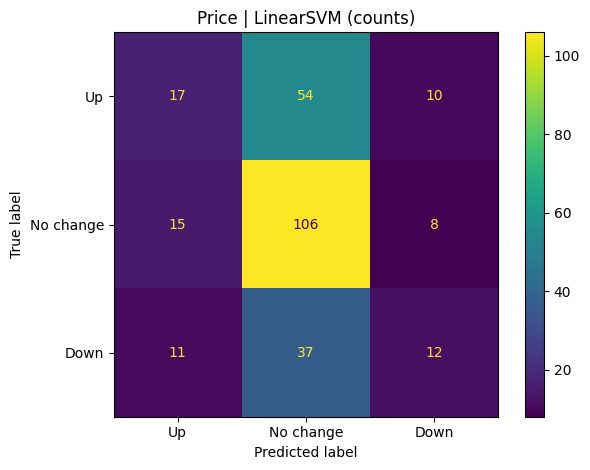

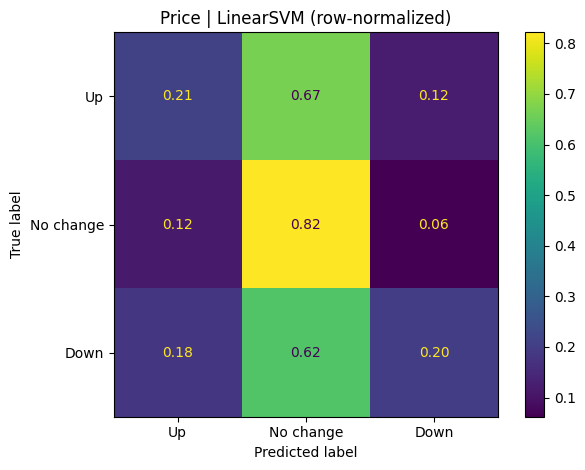

Experiment: Price+Fear | Best model: LinearSVM | Macro-F1=0.3600±0.0720


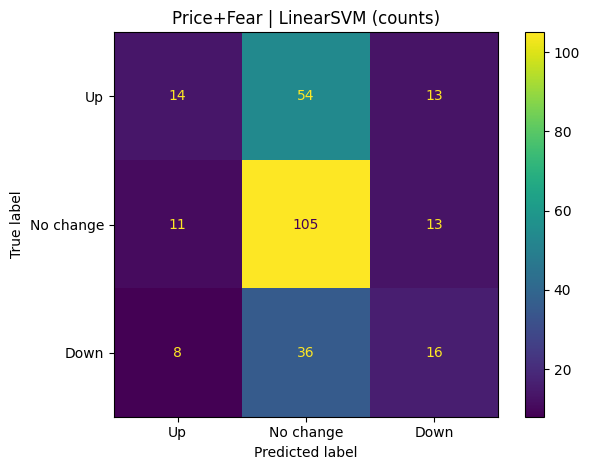

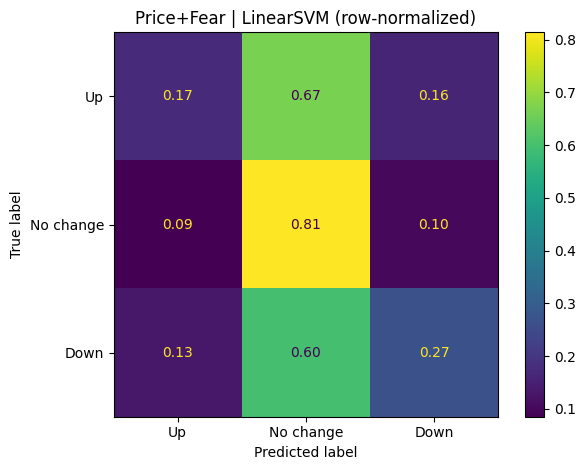

Experiment: Price+News | Best model: LogReg | Macro-F1=0.3690±0.0616


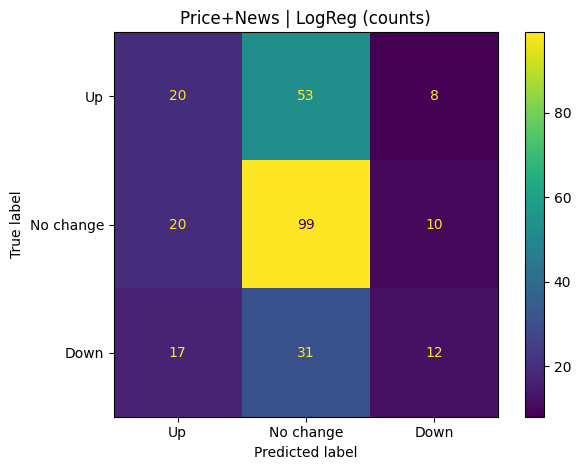

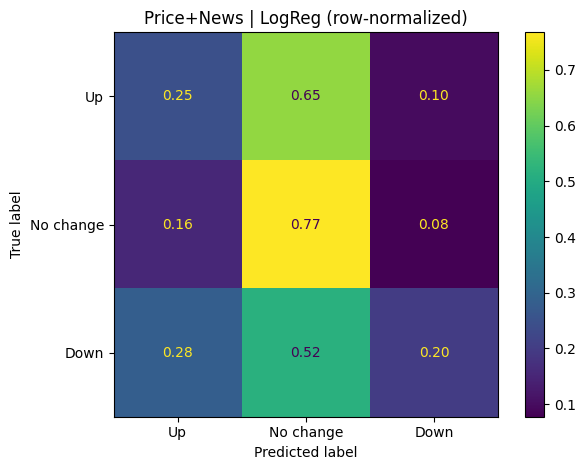

Experiment: Price+Fear+News | Best model: LogReg | Macro-F1=0.3375±0.0725


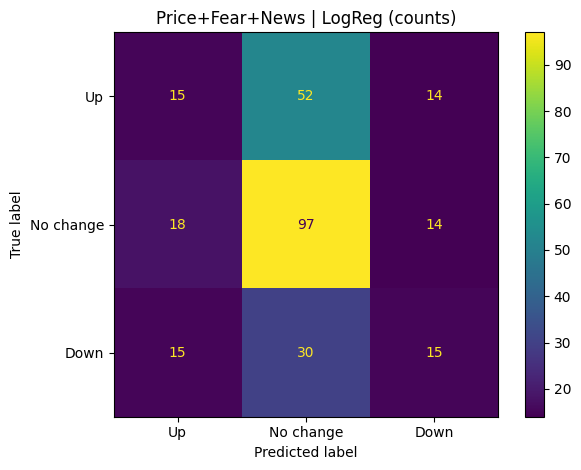

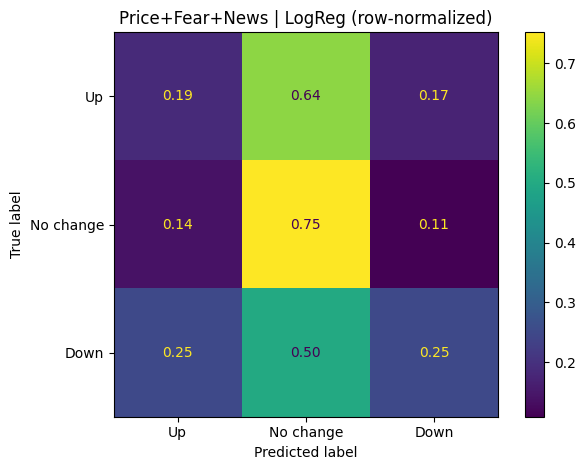

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight

# =========================
# 0) CONFIG (Walk-forward)
# =========================
INITIAL_TRAIN_SIZE = 400
TEST_SIZE = 30
STEP_SIZE = 30
PRINT_FOLDS = True

# 3-class encoding (as requested)
LABELS = [0, 1, 2]
LABEL_NAMES = ["Up", "No change", "Down"]

# =========================
# 1) Paths
# =========================
main_path = ".."
BTC_Price_Fear_Greed_News_Sentiment_path = main_path + "/data/processed/BTC_Price_Fear_Greed_News_Sentiment.csv"

# =========================
# 2) Load & basic cleaning
# =========================
df = pd.read_csv(BTC_Price_Fear_Greed_News_Sentiment_path)
df.columns = [c.strip() for c in df.columns]

print("COLUMNS IN CSV:")
print(df.columns.tolist())

def pick_col(cands):
    for c in cands:
        if c in df.columns:
            return c
    return None

date_col = pick_col(["Date", "date", "DATE"])
if date_col is None:
    raise ValueError(f"Date column not found. Columns: {df.columns.tolist()}")

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

open_col  = pick_col(["Open", "open"])
high_col  = pick_col(["High", "high"])
low_col   = pick_col(["Low", "low"])
close_col = pick_col(["Close", "close", "Adj Close", "adj_close"])
vol_col   = pick_col(["Volume", "volume", "Vol.", "vol"])

missing = [name for name, col in [
    ("Open", open_col), ("High", high_col), ("Low", low_col),
    ("Close", close_col), ("Volume", vol_col)
] if col is None]
if missing:
    raise ValueError(f"Missing required price columns: {missing}. Columns: {df.columns.tolist()}")

fear_col = "Fear_Greed_Value" if "Fear_Greed_Value" in df.columns else None
if fear_col is None:
    print("\nWARNING: 'Fear_Greed_Value' not found -> Fear experiments may be skipped.\n")

def to_num(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

for c in [open_col, high_col, low_col, close_col, vol_col]:
    df[c] = to_num(df[c])
if fear_col is not None:
    df[fear_col] = to_num(df[fear_col])

# =========================
# 3) Detect News Sentiment columns
# =========================
def detect_news_sentiment_cols(columns):
    cols = list(columns)

    preferred_sets = [
        ["news_negative", "news_neutral", "news_positive", "news_compound"],
        ["news_neg", "news_neu", "news_pos", "news_compound"],
    ]
    for s in preferred_sets:
        if all(c in cols for c in s):
            return s

    lowmap = {c: c.lower() for c in cols}
    def find_one(keys):
        for c in cols:
            lc = lowmap[c]
            if "news" in lc and any(k in lc for k in keys):
                return c
        return None

    neg = find_one(["neg", "negative"])
    neu = find_one(["neu", "neutral"])
    pos = find_one(["pos", "positive"])
    comp = find_one(["compound", "score", "vader"])

    found = [c for c in [neg, neu, pos, comp] if c is not None]
    if len(found) > 0:
        return found

    fallback = ["negative", "neutral", "positive", "compound"]
    if all(c in cols for c in fallback):
        return fallback

    return []

news_cols = detect_news_sentiment_cols(df.columns)
if len(news_cols) == 0:
    print("\nWARNING: News sentiment columns not detected -> News experiments may be skipped.\n")
else:
    print("\nDetected News Sentiment columns:", news_cols)
    for c in news_cols:
        df[c] = to_num(df[c])

# =========================
# 4) Feature engineering (NO TAU)
# =========================
def make_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()

    d["ret_1"] = np.log(d[close_col]).diff()
    d["next_ret"] = d["ret_1"].shift(-1)

    for lag in [1, 2, 3, 5, 10]:
        d[f"ret_lag_{lag}"] = d["ret_1"].shift(lag)

    for w in [7, 14, 30]:
        d[f"vol_{w}"] = d["ret_1"].rolling(w).std()

    for w in [7, 14, 30]:
        ma = d[close_col].rolling(w).mean()
        d[f"mom_{w}"] = (d[close_col] / ma) - 1.0

    d["range_pct"] = (d[high_col] - d[low_col]) / d[close_col]
    d["body_pct"]  = (d[close_col] - d[open_col]) / d[open_col]

    d["log_vol"] = np.log(d[vol_col].replace(0, np.nan))
    d["vol_chg"] = d[vol_col].pct_change()
    d["vol_mom_14"] = (d[vol_col] / d[vol_col].rolling(14).mean()) - 1.0

    engineered = [
        "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
        "vol_7","vol_14","vol_30",
        "mom_7","mom_14","mom_30",
        "range_pct","body_pct",
        "log_vol","vol_chg","vol_mom_14",
        "next_ret"
    ]
    return d.dropna(subset=engineered).copy()

price_features = [
    "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
    "vol_7","vol_14","vol_30",
    "mom_7","mom_14","mom_30",
    "range_pct","body_pct",
    "log_vol","vol_chg","vol_mom_14"
]

d_base = make_features(df)

# =========================
# 5) Walk-forward splitter
# =========================
def walk_forward_splits(n, initial_train_size, test_size, step_size):
    train_end = initial_train_size
    while train_end + test_size <= n:
        train_idx = np.arange(0, train_end)
        test_idx  = np.arange(train_end, train_end + test_size)
        yield train_idx, test_idx
        train_end += step_size

# =========================
# 6) Models (scaled for LogReg/SVM)
# =========================
def get_models(random_state=42):
    return {
        "LogReg": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=5000, random_state=random_state))
        ]),
        "LinearSVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LinearSVC(random_state=random_state))
        ]),
        "RBFSVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", random_state=random_state))
        ]),
        "RandomForest": RandomForestClassifier(random_state=random_state),
        "ExtraTrees": ExtraTreesClassifier(random_state=random_state),
        "GradBoost": GradientBoostingClassifier(random_state=random_state),
        "HistGradBoost": HistGradientBoostingClassifier(random_state=random_state),
    }

# =========================
# 7) Walk-forward evaluation (Fold-by-fold dynamic q_low/q_high)
# =========================
def fit_predict_with_weights(model, X_train, y_train, X_test):
    sw = compute_sample_weight(class_weight="balanced", y=y_train)
    if isinstance(model, Pipeline):
        model.fit(X_train, y_train, **{"clf__sample_weight": sw})
    else:
        model.fit(X_train, y_train, sample_weight=sw)
    return model.predict(X_test)

def fold_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
    }

def eval_walk_forward_dynamic_terciles(model, d_exp, feature_cols, exp_name, model_name, low_q=0.33, high_q=0.67):
    """
    Key change vs old code:
      - For EACH fold:
          * compute q_low/q_high from TRAIN slice only
          * create y_train, y_test using those fold-specific thresholds
      - This adapts labels as training window grows (regime adaptation) and prevents look-ahead.
    """
    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        raise ValueError(
            f"{exp_name}: Not enough rows ({len(d_exp)}) for walk-forward "
            f"(need at least {INITIAL_TRAIN_SIZE + TEST_SIZE})."
        )

    dates = pd.to_datetime(d_exp[date_col]).reset_index(drop=True)

    y_true_all, y_pred_all, date_all = [], [], []
    per_fold = []

    fold_no = 0
    for train_idx, test_idx in walk_forward_splits(
        len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE
    ):
        fold_no += 1

        train_start = dates.iloc[train_idx[0]].date()
        train_end   = dates.iloc[train_idx[-1]].date()
        test_start  = dates.iloc[test_idx[0]].date()
        test_end    = dates.iloc[test_idx[-1]].date()

        train = d_exp.iloc[train_idx]
        test  = d_exp.iloc[test_idx]

        # --- Fold-specific tercile thresholds computed ONLY from TRAIN next_ret ---
        train_rets = train["next_ret"].values
        q_low_fold = float(np.quantile(train_rets, low_q))
        q_high_fold = float(np.quantile(train_rets, high_q))

        # --- Fold-specific labels for TRAIN and TEST (using same fold thresholds) ---
        y_train = np.where(train["next_ret"].values >= q_high_fold, 0,
                  np.where(train["next_ret"].values <= q_low_fold, 2, 1))
        y_test  = np.where(test["next_ret"].values  >= q_high_fold, 0,
                  np.where(test["next_ret"].values  <= q_low_fold, 2, 1))

        if PRINT_FOLDS:
            dist_tr = pd.Series(y_train).value_counts().sort_index().to_dict()
            dist_te = pd.Series(y_test).value_counts().sort_index().to_dict()
            print(f"[{exp_name} | {model_name}] Fold {fold_no:02d}  "
                  f"TRAIN: {train_start} -> {train_end}   "
                  f"TEST: {test_start} -> {test_end}  | "
                  f"q_low={q_low_fold:.6f}, q_high={q_high_fold:.6f}  | "
                  f"TRAIN dist={dist_tr}  TEST dist={dist_te}")

        X_train = train[feature_cols].values
        X_test  = test[feature_cols].values

        y_pred = fit_predict_with_weights(model, X_train, y_train, X_test)

        y_true_all.append(y_test)
        y_pred_all.append(y_pred)
        date_all.append(dates.iloc[test_idx].values)

        per_fold.append(fold_metrics(y_test, y_pred))

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    date_all = np.concatenate(date_all)

    mf = pd.DataFrame(per_fold)
    summary = {
        "n_folds": fold_no,
        "accuracy_mean": float(mf["accuracy"].mean()),
        "accuracy_std": float(mf["accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "balanced_accuracy_mean": float(mf["balanced_accuracy"].mean()),
        "balanced_accuracy_std": float(mf["balanced_accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_f1_mean": float(mf["macro_f1"].mean()),
        "macro_f1_std": float(mf["macro_f1"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_precision_mean": float(mf["macro_precision"].mean()),
        "macro_precision_std": float(mf["macro_precision"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_recall_mean": float(mf["macro_recall"].mean()),
        "macro_recall_std": float(mf["macro_recall"].std(ddof=1)) if fold_no > 1 else 0.0,
    }

    return summary, date_all, y_true_all, y_pred_all

# =========================
# 8) Experiments: 4 feature sets
# =========================
experiments = []
experiments.append(("Price", d_base.copy(), price_features))

if fear_col is not None:
    d_pf = d_base.copy()
    d_pf["fear_greed"] = d_pf[fear_col]
    d_pf = d_pf.dropna(subset=["fear_greed"]).copy()
    experiments.append(("Price+Fear", d_pf, price_features + ["fear_greed"]))
else:
    print("Skipping Price+Fear (Fear_Greed_Value missing).")

if len(news_cols) > 0:
    d_pn = d_base.copy().dropna(subset=news_cols).copy()
    experiments.append(("Price+News", d_pn, price_features + news_cols))
else:
    print("Skipping Price+News (News sentiment columns not detected).")

if (fear_col is not None) and (len(news_cols) > 0):
    d_pfn = d_base.copy()
    d_pfn["fear_greed"] = d_pfn[fear_col]
    d_pfn = d_pfn.dropna(subset=["fear_greed"] + news_cols).copy()
    experiments.append(("Price+Fear+News", d_pfn, price_features + ["fear_greed"] + news_cols))
else:
    print("Skipping Price+Fear+News (Fear or News missing).")

# =========================
# 9) Run all models, store results + predictions for confusion matrix
# =========================
all_results = []
pred_store = {}  # (setup, model) -> (dates, y_true, y_pred)

for exp_name, d_exp, feat_cols in experiments:
    print("\n" + "#" * 70)
    print(f"EXP: {exp_name}")
    print(f"Rows: {len(d_exp)} | Features: {len(feat_cols)}")
    print(f"Overall date range: {pd.to_datetime(d_exp[date_col]).min().date()} -> {pd.to_datetime(d_exp[date_col]).max().date()}")

    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        print(f"Skipping {exp_name}: Not enough rows for walk-forward (need {INITIAL_TRAIN_SIZE + TEST_SIZE}).")
        continue

    # Informative only (global distribution is no longer the truth driver):
    # we do NOT set a fixed y_3class here anymore.
    print(f"[{exp_name}] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.")
    dates_exp = pd.to_datetime(d_exp[date_col]).reset_index(drop=True)
    print(f"Walk-forward first TEST start: {dates_exp.iloc[INITIAL_TRAIN_SIZE].date()}")
    last_test_end = None
    for _, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        last_test_end = dates_exp.iloc[test_idx[-1]].date()
    print(f"Walk-forward last  TEST end  : {last_test_end}")
    print("#" * 70)

    for model_name, model in get_models(42).items():
        summary, dates_all, y_true_all, y_pred_all = eval_walk_forward_dynamic_terciles(
            model, d_exp, feat_cols, exp_name, model_name, low_q=0.33, high_q=0.67
        )

        print(f"--> {model_name} summary: "
              f"Acc={summary['accuracy_mean']:.4f}±{summary['accuracy_std']:.4f} | "
              f"BalAcc={summary['balanced_accuracy_mean']:.4f}±{summary['balanced_accuracy_std']:.4f} | "
              f"Prec={summary['macro_precision_mean']:.4f}±{summary['macro_precision_std']:.4f} | "
              f"Rec={summary['macro_recall_mean']:.4f}±{summary['macro_recall_std']:.4f} | "
              f"F1={summary['macro_f1_mean']:.4f}±{summary['macro_f1_std']:.4f}")

        row = {"setup": exp_name, "model": model_name, **summary}
        all_results.append(row)
        pred_store[(exp_name, model_name)] = (dates_all, y_true_all, y_pred_all)

comp = pd.DataFrame(all_results)

def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"

comp["accuracy_mean±std"] = comp.apply(lambda r: pm(r["accuracy_mean"], r["accuracy_std"]), axis=1)
comp["precision_mean±std"] = comp.apply(lambda r: pm(r["macro_precision_mean"], r["macro_precision_std"]), axis=1)
comp["recall_mean±std"] = comp.apply(lambda r: pm(r["macro_recall_mean"], r["macro_recall_std"]), axis=1)
comp["macro_f1_mean±std"] = comp.apply(lambda r: pm(r["macro_f1_mean"], r["macro_f1_std"]), axis=1)
comp["bal_acc_mean±std"] = comp.apply(lambda r: pm(r["balanced_accuracy_mean"], r["balanced_accuracy_std"]), axis=1)

comp_sorted = comp.sort_values(["setup", "macro_f1_mean"], ascending=[True, False]).reset_index(drop=True)

print("\n============================")
print("COMPARISON TABLE (Walk-forward; dynamic fold terciles; mean ± std across folds)")
print("============================")
show_cols = [
    "setup", "model", "n_folds",
    "accuracy_mean±std", "precision_mean±std", "recall_mean±std",
    "macro_f1_mean±std", "bal_acc_mean±std"
]
print(comp_sorted[show_cols])

# =========================
# 10) Confusion Matrix: best model per experiment (by macro_f1_mean)
# =========================
def show_confusion(y_true, y_pred, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABEL_NAMES)
    disp.plot(values_format=".2f" if normalize else "d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

print("\n============================")
print("CONFUSION MATRICES (Best model per experiment by Macro-F1 mean)")
print("============================")

for exp_name, _, _ in experiments:
    if exp_name not in comp_sorted["setup"].unique():
        continue

    sub = comp_sorted[comp_sorted["setup"] == exp_name].sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
    best_model = sub.loc[0, "model"]
    best_f1_m = sub.loc[0, "macro_f1_mean"]
    best_f1_s = sub.loc[0, "macro_f1_std"]

    dates_all, y_true_all, y_pred_all = pred_store[(exp_name, best_model)]
    print(f"Experiment: {exp_name} | Best model: {best_model} | Macro-F1={best_f1_m:.4f}±{best_f1_s:.4f}")

    show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {best_model} (counts)", normalize=None)
    show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {best_model} (row-normalized)", normalize="true")


  ## Traditional_ML_Models-BTC_Price_Tweet_News_Sentiment_EN_SAF_HAL

COLUMNS IN CSV:
['date', 'close', 'high', 'low', 'open', 'volume', 'twitter_neg', 'twitter_neu', 'twitter_pos', 'twitter_compound', 'news_neg', 'news_neu', 'news_pos', 'news_compound']

######################################################################
EXP: Price
Rows: 136 | Features: 16
Overall date range: 2022-01-22 -> 2023-01-09
[Price] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.
Walk-forward first TEST start: 2022-07-16
Walk-forward last  TEST end  : 2023-01-08
######################################################################
[Price | LogReg] Fold 01  TRAIN: 2022-01-22 -> 2022-07-15   TEST: 2022-07-16 -> 2022-09-15  | q_low=-0.015257, q_high=0.012618  | TRAIN dist={0: 30, 1: 30, 2: 30}  TEST dist={0: 4, 1: 7, 2: 4}
[Price | LogReg] Fold 02  TRAIN: 2022-01-22 -> 2022-09-15   TEST: 2022-10-09 -> 2022-11-13  | q_low=-0.013937, q_high=0.011489  | TRAIN dist={0: 35, 1: 35, 2: 35}  TEST dist={0: 4, 1: 6, 2: 5}
[Price | LogReg] Fold 03

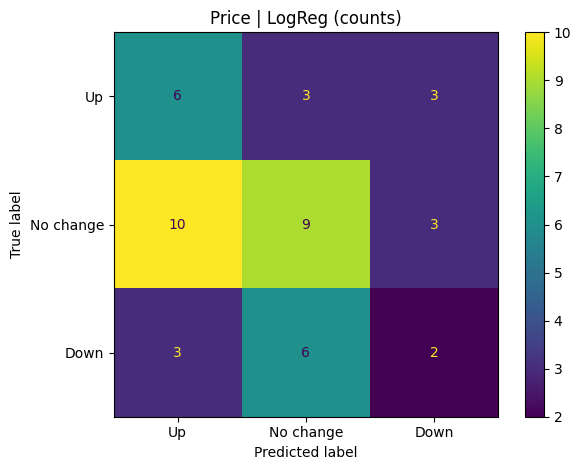

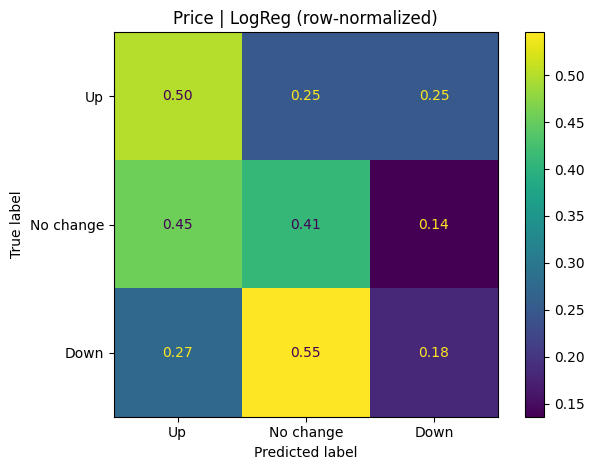

Experiment: Price+Twitter | Best model: LogReg | Macro-F1=0.3114±0.0596


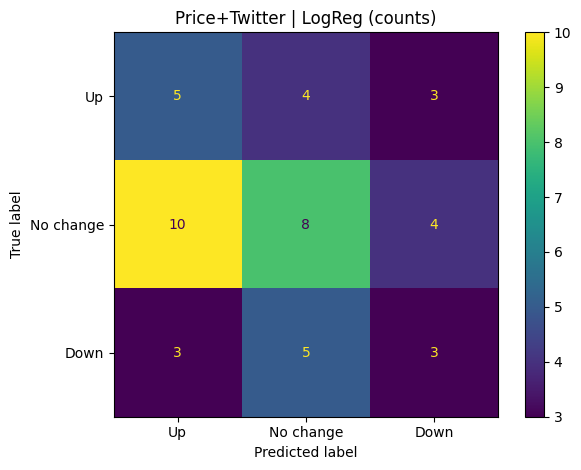

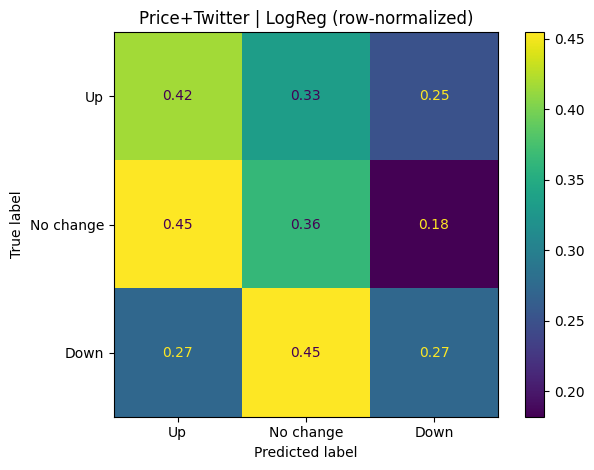

Experiment: Price+News | Best model: LogReg | Macro-F1=0.3344±0.0494


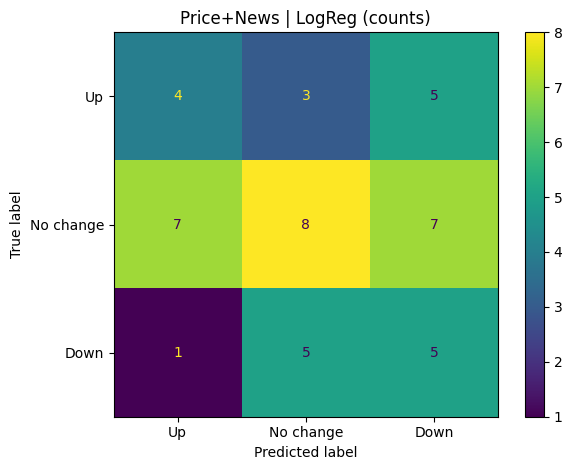

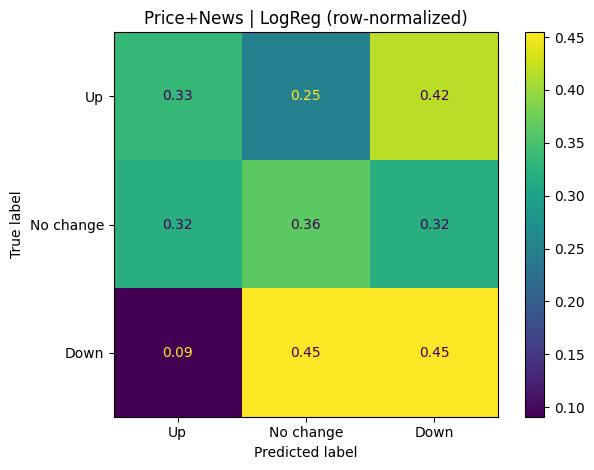

Experiment: All | Best model: LinearSVM | Macro-F1=0.2947±0.0837


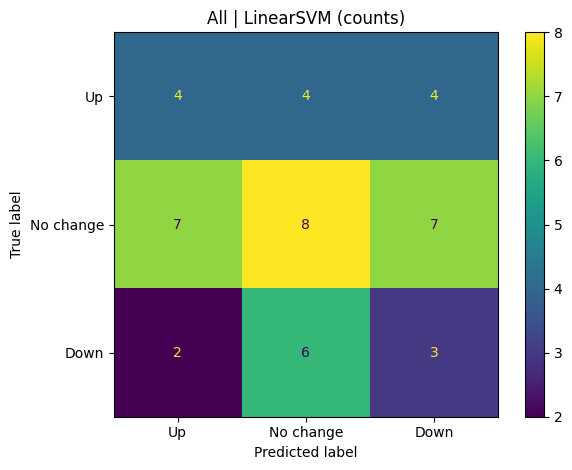

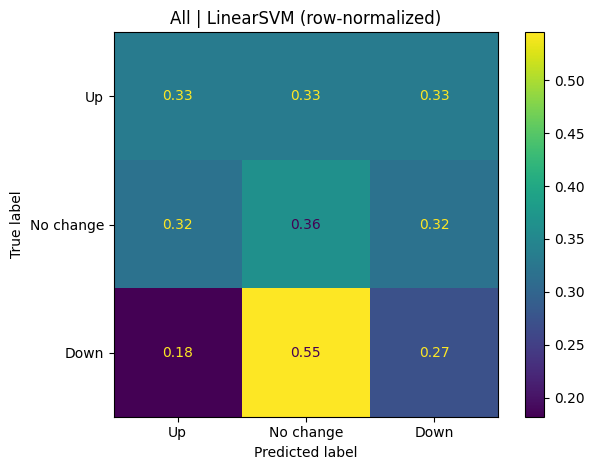

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight

# =========================
# 0) CONFIG (Walk-forward)
# =========================
INITIAL_TRAIN_SIZE = 90
TEST_SIZE = 15
STEP_SIZE = 15
PRINT_FOLDS = True

# 3-class encoding (as requested)
LABELS = [0, 1, 2]
LABEL_NAMES = ["Up", "No change", "Down"]

# =========================
# 1) Paths (DATASET A)
# =========================
main_path = ".."
BTC_Price_News_Tweets_Sentiment_path = main_path + "/data/processed/BTC_Price_News_Tweets_Sentiment.csv"

# =========================
# 2) Load & basic cleaning
# =========================
df = pd.read_csv(BTC_Price_News_Tweets_Sentiment_path)
df.columns = [c.strip() for c in df.columns]

print("COLUMNS IN CSV:")
print(df.columns.tolist())

# Beklenen kolonlar (Dataset A)
req_cols = ["date", "open", "high", "low", "close", "volume"]
for c in req_cols:
    if c not in df.columns:
        raise ValueError(f"Missing required column '{c}'. Columns: {df.columns.tolist()}")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

def to_num(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

# Fiyat kolonlarını sayısala çevir
for c in ["open", "high", "low", "close", "volume"]:
    df[c] = to_num(df[c])

# Twitter ve News kolonlarını sayısala çevir (varsa)
twitter_cols = ["twitter_neg", "twitter_neu", "twitter_pos", "twitter_compound"]
news_cols    = ["news_neg", "news_neu", "news_pos", "news_compound"]

for c in twitter_cols:
    if c in df.columns:
        df[c] = to_num(df[c])
for c in news_cols:
    if c in df.columns:
        df[c] = to_num(df[c])

# En azından fiyat kolonlarında NaN olanları at
df = df.dropna(subset=["open", "high", "low", "close", "volume"]).copy()

# =========================
# 3) Feature engineering (NO TAU)
# =========================
def make_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()

    # log return
    d["ret_1"] = np.log(d["close"]).diff()

    # next-day return used for labeling (not a feature directly)
    d["next_ret"] = d["ret_1"].shift(-1)

    # lagged returns
    for lag in [1, 2, 3, 5, 10]:
        d[f"ret_lag_{lag}"] = d["ret_1"].shift(lag)

    # rolling volatility
    for w in [7, 14, 30]:
        d[f"vol_{w}"] = d["ret_1"].rolling(w).std()

    # momentum via MA ratio
    for w in [7, 14, 30]:
        ma = d["close"].rolling(w).mean()
        d[f"mom_{w}"] = (d["close"] / ma) - 1.0

    # candle/range
    d["range_pct"] = (d["high"] - d["low"]) / d["close"]
    d["body_pct"]  = (d["close"] - d["open"]) / d["open"]

    # volume features
    d["log_vol"] = np.log(d["volume"].replace(0, np.nan))
    d["vol_chg"] = d["volume"].pct_change()
    d["vol_mom_14"] = (d["volume"] / d["volume"].rolling(14).mean()) - 1.0

    engineered = [
        "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
        "vol_7","vol_14","vol_30",
        "mom_7","mom_14","mom_30",
        "range_pct","body_pct",
        "log_vol","vol_chg","vol_mom_14",
        "next_ret"
    ]
    return d.dropna(subset=engineered).copy()

price_features = [
    "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
    "vol_7","vol_14","vol_30",
    "mom_7","mom_14","mom_30",
    "range_pct","body_pct",
    "log_vol","vol_chg","vol_mom_14"
]

d_base = make_features(df)

# =========================
# 4) Walk-forward splitter
# =========================
def walk_forward_splits(n, initial_train_size, test_size, step_size):
    train_end = initial_train_size
    while train_end + test_size <= n:
        train_idx = np.arange(0, train_end)
        test_idx  = np.arange(train_end, train_end + test_size)
        yield train_idx, test_idx
        train_end += step_size

# =========================
# 5) Models (scaled for LogReg/SVM)
# =========================
def get_models(random_state=42):
    return {
        "LogReg": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=5000, random_state=random_state))
        ]),
        "LinearSVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LinearSVC(random_state=random_state))
        ]),
        "RBFSVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", random_state=random_state))
        ]),
        "RandomForest": RandomForestClassifier(random_state=random_state),
        "ExtraTrees": ExtraTreesClassifier(random_state=random_state),
        "GradBoost": GradientBoostingClassifier(random_state=random_state),
        "HistGradBoost": HistGradientBoostingClassifier(random_state=random_state),
    }

# =========================
# 6) Walk-forward evaluation (Dynamic q_low/q_high per fold)
# =========================
def fit_predict_with_weights(model, X_train, y_train, X_test):
    sw = compute_sample_weight(class_weight="balanced", y=y_train)
    if isinstance(model, Pipeline):
        model.fit(X_train, y_train, **{"clf__sample_weight": sw})
    else:
        model.fit(X_train, y_train, sample_weight=sw)
    return model.predict(X_test)

def fold_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
    }

def eval_walk_forward_dynamic_terciles(model, d_exp, feature_cols, exp_name, model_name, low_q=0.33, high_q=0.67):
    """
    For EACH fold:
      - compute q_low/q_high from TRAIN slice only
      - label BOTH train and test with these fold thresholds
    """
    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        raise ValueError(
            f"{exp_name}: Not enough rows ({len(d_exp)}) for walk-forward "
            f"(need at least {INITIAL_TRAIN_SIZE + TEST_SIZE})."
        )

    dates = pd.to_datetime(d_exp["date"]).reset_index(drop=True)

    y_true_all, y_pred_all, date_all = [], [], []
    per_fold = []

    fold_no = 0
    for train_idx, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        fold_no += 1

        train_start = dates.iloc[train_idx[0]].date()
        train_end   = dates.iloc[train_idx[-1]].date()
        test_start  = dates.iloc[test_idx[0]].date()
        test_end    = dates.iloc[test_idx[-1]].date()

        train = d_exp.iloc[train_idx]
        test  = d_exp.iloc[test_idx]

        # Fold-specific thresholds from TRAIN only
        train_rets = train["next_ret"].values
        q_low_fold  = float(np.quantile(train_rets, low_q))
        q_high_fold = float(np.quantile(train_rets, high_q))

        # Fold-specific labels (apply same thresholds to train and test)
        y_train = np.where(train["next_ret"].values >= q_high_fold, 0,
                  np.where(train["next_ret"].values <= q_low_fold, 2, 1))
        y_test  = np.where(test["next_ret"].values  >= q_high_fold, 0,
                  np.where(test["next_ret"].values  <= q_low_fold, 2, 1))

        if PRINT_FOLDS:
            dist_tr = pd.Series(y_train).value_counts().sort_index().to_dict()
            dist_te = pd.Series(y_test).value_counts().sort_index().to_dict()
            print(f"[{exp_name} | {model_name}] Fold {fold_no:02d}  "
                  f"TRAIN: {train_start} -> {train_end}   "
                  f"TEST: {test_start} -> {test_end}  | "
                  f"q_low={q_low_fold:.6f}, q_high={q_high_fold:.6f}  | "
                  f"TRAIN dist={dist_tr}  TEST dist={dist_te}")

        X_train = train[feature_cols].values
        X_test  = test[feature_cols].values

        y_pred = fit_predict_with_weights(model, X_train, y_train, X_test)

        y_true_all.append(y_test)
        y_pred_all.append(y_pred)
        date_all.append(dates.iloc[test_idx].values)

        per_fold.append(fold_metrics(y_test, y_pred))

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    date_all = np.concatenate(date_all)

    mf = pd.DataFrame(per_fold)
    summary = {
        "n_folds": fold_no,
        "accuracy_mean": float(mf["accuracy"].mean()),
        "accuracy_std": float(mf["accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "balanced_accuracy_mean": float(mf["balanced_accuracy"].mean()),
        "balanced_accuracy_std": float(mf["balanced_accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_f1_mean": float(mf["macro_f1"].mean()),
        "macro_f1_std": float(mf["macro_f1"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_precision_mean": float(mf["macro_precision"].mean()),
        "macro_precision_std": float(mf["macro_precision"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_recall_mean": float(mf["macro_recall"].mean()),
        "macro_recall_std": float(mf["macro_recall"].std(ddof=1)) if fold_no > 1 else 0.0,
    }

    return summary, date_all, y_true_all, y_pred_all

# =========================
# 7) Experiments (Dataset A: Price/Twitter/News/All)
# =========================
experiments = []

# 1) Price
experiments.append(("Price", d_base.copy(), price_features))

# 2) Price + Twitter
if all(c in d_base.columns for c in twitter_cols):
    d_tw = d_base.dropna(subset=twitter_cols).copy()
    experiments.append(("Price+Twitter", d_tw, price_features + twitter_cols))
else:
    print("Skipping Price+Twitter (missing twitter columns).")

# 3) Price + News
if all(c in d_base.columns for c in news_cols):
    d_nw = d_base.dropna(subset=news_cols).copy()
    experiments.append(("Price+News", d_nw, price_features + news_cols))
else:
    print("Skipping Price+News (missing news columns).")

# 4) All
if all(c in d_base.columns for c in twitter_cols + news_cols):
    d_all = d_base.dropna(subset=twitter_cols + news_cols).copy()
    experiments.append(("All", d_all, price_features + twitter_cols + news_cols))
else:
    print("Skipping All (missing twitter/news columns).")

# =========================
# 8) Run all models, store results + predictions
# =========================
all_results = []
pred_store = {}  # (setup, model) -> (dates, y_true, y_pred)

for exp_name, d_exp, feat_cols in experiments:
    print("\n" + "#" * 70)
    print(f"EXP: {exp_name}")
    print(f"Rows: {len(d_exp)} | Features: {len(feat_cols)}")
    print(f"Overall date range: {pd.to_datetime(d_exp['date']).min().date()} -> {pd.to_datetime(d_exp['date']).max().date()}")

    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        print(f"Skipping {exp_name}: Not enough rows for walk-forward (need {INITIAL_TRAIN_SIZE + TEST_SIZE}).")
        continue

    print(f"[{exp_name}] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.")

    dates_exp = pd.to_datetime(d_exp["date"]).reset_index(drop=True)
    print(f"Walk-forward first TEST start: {dates_exp.iloc[INITIAL_TRAIN_SIZE].date()}")
    last_test_end = None
    for _, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        last_test_end = dates_exp.iloc[test_idx[-1]].date()
    print(f"Walk-forward last  TEST end  : {last_test_end}")
    print("#" * 70)

    for model_name, model in get_models(42).items():
        summary, dates_all, y_true_all, y_pred_all = eval_walk_forward_dynamic_terciles(
            model, d_exp, feat_cols, exp_name, model_name, low_q=0.33, high_q=0.67
        )

        print(f"--> {model_name} summary: "
              f"Acc={summary['accuracy_mean']:.4f}±{summary['accuracy_std']:.4f} | "
              f"BalAcc={summary['balanced_accuracy_mean']:.4f}±{summary['balanced_accuracy_std']:.4f} | "
              f"Prec={summary['macro_precision_mean']:.4f}±{summary['macro_precision_std']:.4f} | "
              f"Rec={summary['macro_recall_mean']:.4f}±{summary['macro_recall_std']:.4f} | "
              f"F1={summary['macro_f1_mean']:.4f}±{summary['macro_f1_std']:.4f}")

        row = {"setup": exp_name, "model": model_name, **summary}
        all_results.append(row)
        pred_store[(exp_name, model_name)] = (dates_all, y_true_all, y_pred_all)

comp = pd.DataFrame(all_results)

def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"

comp["accuracy_mean±std"]   = comp.apply(lambda r: pm(r["accuracy_mean"], r["accuracy_std"]), axis=1)
comp["precision_mean±std"]  = comp.apply(lambda r: pm(r["macro_precision_mean"], r["macro_precision_std"]), axis=1)
comp["recall_mean±std"]     = comp.apply(lambda r: pm(r["macro_recall_mean"], r["macro_recall_std"]), axis=1)
comp["macro_f1_mean±std"]   = comp.apply(lambda r: pm(r["macro_f1_mean"], r["macro_f1_std"]), axis=1)
comp["bal_acc_mean±std"]    = comp.apply(lambda r: pm(r["balanced_accuracy_mean"], r["balanced_accuracy_std"]), axis=1)

comp_sorted = comp.sort_values(["setup", "macro_f1_mean"], ascending=[True, False]).reset_index(drop=True)

print("\n============================")
print("COMPARISON TABLE (Dataset A; Walk-forward; dynamic fold terciles; mean ± std across folds)")
print("============================")
show_cols = [
    "setup", "model", "n_folds",
    "accuracy_mean±std", "precision_mean±std", "recall_mean±std",
    "macro_f1_mean±std", "bal_acc_mean±std"
]
print(comp_sorted[show_cols])

# =========================
# 9) Confusion Matrix: best model per experiment (by macro_f1_mean)
# =========================
def show_confusion(y_true, y_pred, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABEL_NAMES)
    disp.plot(values_format=".2f" if normalize else "d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

print("\n============================")
print("CONFUSION MATRICES (Best model per experiment by Macro-F1 mean)")
print("============================")

for exp_name, _, _ in experiments:
    if exp_name not in comp_sorted["setup"].unique():
        continue

    sub = comp_sorted[comp_sorted["setup"] == exp_name].sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
    best_model = sub.loc[0, "model"]
    best_f1_m = sub.loc[0, "macro_f1_mean"]
    best_f1_s = sub.loc[0, "macro_f1_std"]

    dates_all, y_true_all, y_pred_all = pred_store[(exp_name, best_model)]
    print(f"Experiment: {exp_name} | Best model: {best_model} | Macro-F1={best_f1_m:.4f}±{best_f1_s:.4f}")

    show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {best_model} (counts)", normalize=None)
    show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {best_model} (row-normalized)", normalize="true")


## Deep_Models_Trial-BTC_Price_Fear_Greed_News_Sentiment

MLP layer and neuron architectures from Homework-3, Problem 1 were used (same network structure), and the model was trained with the BTC price + Fear & Greed + News sentiment features.

COLUMNS IN CSV:
['date', 'close', 'high', 'low', 'open', 'volume', 'Fear_Greed_Value', 'News_neg', 'News_neu', 'News_pos', 'News_compound']

Detected News Sentiment columns: ['News_neg', 'News_neu', 'News_pos', 'News_compound']

######################################################################
EXP: Price
Rows: 678 | Features: 16
Overall date range: 2022-02-09 -> 2023-12-18
[Price] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.
Walk-forward first TEST start: 2023-03-16
Walk-forward last  TEST end  : 2023-12-10
######################################################################
[Price | MLP_1HL_8] Fold 01  TRAIN: 2022-02-09 -> 2023-03-15   TEST: 2023-03-16 -> 2023-04-14  | q_low=-0.009430, q_high=0.006971  | TRAIN dist={0: 132, 1: 136, 2: 132}  TEST dist={0: 12, 1: 11, 2: 7}
[Price | MLP_1HL_8] Fold 02  TRAIN: 2022-02-09 -> 2023-04-14   TEST: 2023-04-15 -> 2023-05-14  | q_low=-0.009031, q_high=0.007297  | TRAIN dist={0: 142, 1: 146, 2: 14

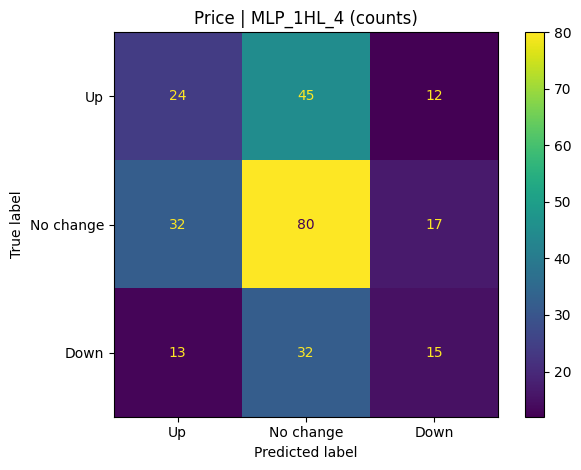

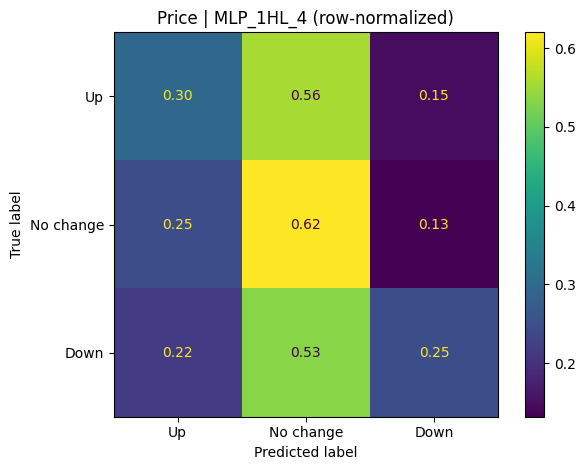

Experiment: Price+Fear | Best model: MLP_2HL_8_4 | Macro-F1=0.3610±0.1193


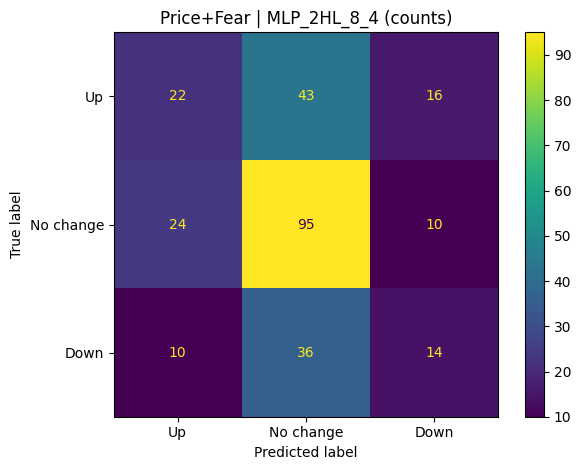

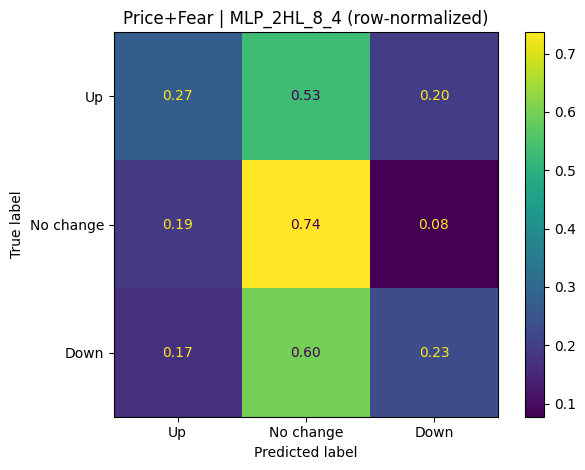

Experiment: Price+News | Best model: MLP_2HL_8_4 | Macro-F1=0.3097±0.0812


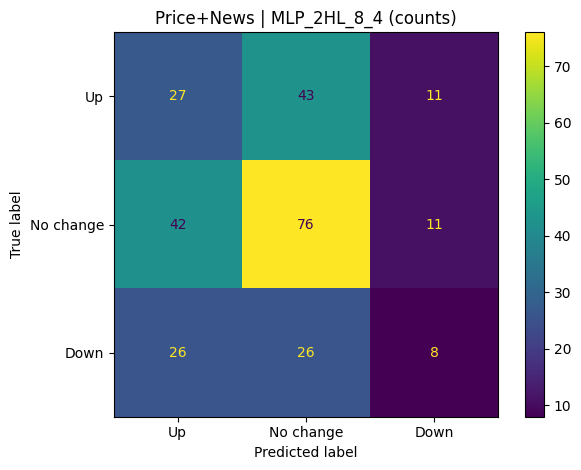

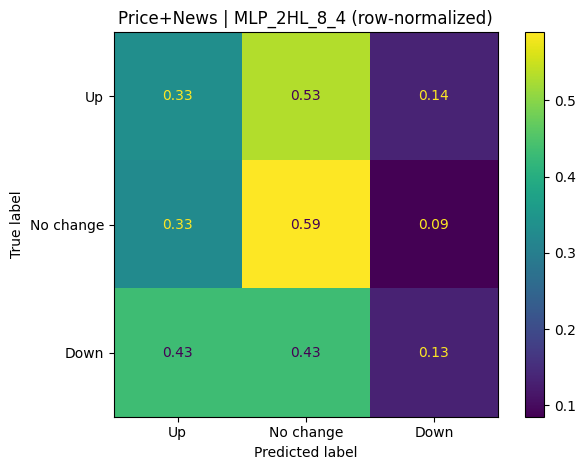

Experiment: Price+Fear+News | Best model: MLP_2HL_4_4 | Macro-F1=0.3340±0.0775


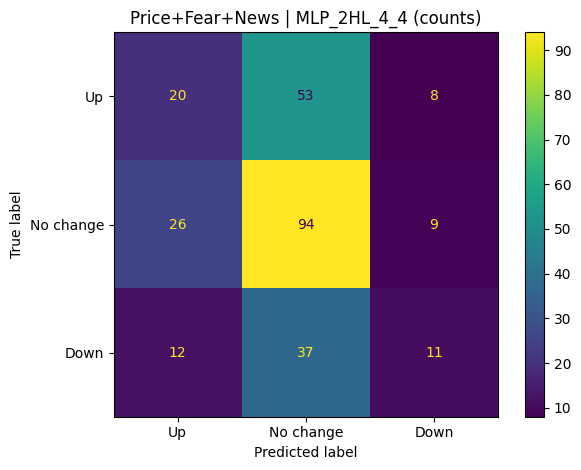

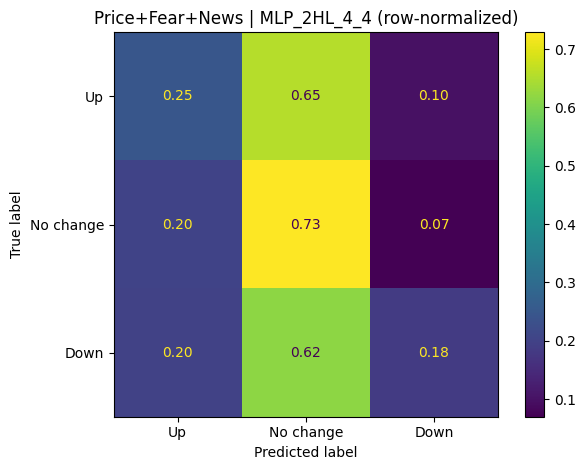

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight

# =========================
# 0) CONFIG (Walk-forward)
# =========================
INITIAL_TRAIN_SIZE = 400
TEST_SIZE = 30
STEP_SIZE = 30
PRINT_FOLDS = True

# 3-class encoding (as requested)
LABELS = [0, 1, 2]
LABEL_NAMES = ["Up", "No change", "Down"]

# =========================
# 1) Paths
# =========================
main_path = ".."
BTC_Price_Fear_Greed_News_Sentiment_path = main_path + "/data/processed/BTC_Price_Fear_Greed_News_Sentiment.csv"

# =========================
# 2) Load & basic cleaning
# =========================
df = pd.read_csv(BTC_Price_Fear_Greed_News_Sentiment_path)
df.columns = [c.strip() for c in df.columns]

print("COLUMNS IN CSV:")
print(df.columns.tolist())

def pick_col(cands):
    for c in cands:
        if c in df.columns:
            return c
    return None

date_col = pick_col(["Date", "date", "DATE"])
if date_col is None:
    raise ValueError(f"Date column not found. Columns: {df.columns.tolist()}")

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

open_col  = pick_col(["Open", "open"])
high_col  = pick_col(["High", "high"])
low_col   = pick_col(["Low", "low"])
close_col = pick_col(["Close", "close", "Adj Close", "adj_close"])
vol_col   = pick_col(["Volume", "volume", "Vol.", "vol"])

missing = [name for name, col in [
    ("Open", open_col), ("High", high_col), ("Low", low_col),
    ("Close", close_col), ("Volume", vol_col)
] if col is None]
if missing:
    raise ValueError(f"Missing required price columns: {missing}. Columns: {df.columns.tolist()}")

fear_col = "Fear_Greed_Value" if "Fear_Greed_Value" in df.columns else None
if fear_col is None:
    print("\nWARNING: 'Fear_Greed_Value' not found -> Fear experiments may be skipped.\n")

def to_num(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

for c in [open_col, high_col, low_col, close_col, vol_col]:
    df[c] = to_num(df[c])
if fear_col is not None:
    df[fear_col] = to_num(df[fear_col])

# =========================
# 3) Detect News Sentiment columns
# =========================
def detect_news_sentiment_cols(columns):
    cols = list(columns)

    preferred_sets = [
        ["news_negative", "news_neutral", "news_positive", "news_compound"],
        ["news_neg", "news_neu", "news_pos", "news_compound"],
    ]
    for s in preferred_sets:
        if all(c in cols for c in s):
            return s

    lowmap = {c: c.lower() for c in cols}
    def find_one(keys):
        for c in cols:
            lc = lowmap[c]
            if "news" in lc and any(k in lc for k in keys):
                return c
        return None

    neg = find_one(["neg", "negative"])
    neu = find_one(["neu", "neutral"])
    pos = find_one(["pos", "positive"])
    comp = find_one(["compound", "score", "vader"])

    found = [c for c in [neg, neu, pos, comp] if c is not None]
    if len(found) > 0:
        return found

    fallback = ["negative", "neutral", "positive", "compound"]
    if all(c in cols for c in fallback):
        return fallback

    return []

news_cols = detect_news_sentiment_cols(df.columns)
if len(news_cols) == 0:
    print("\nWARNING: News sentiment columns not detected -> News experiments may be skipped.\n")
else:
    print("\nDetected News Sentiment columns:", news_cols)
    for c in news_cols:
        df[c] = to_num(df[c])

# =========================
# 4) Feature engineering (NO TAU)
# =========================
def make_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()

    d["ret_1"] = np.log(d[close_col]).diff()
    d["next_ret"] = d["ret_1"].shift(-1)

    for lag in [1, 2, 3, 5, 10]:
        d[f"ret_lag_{lag}"] = d["ret_1"].shift(lag)

    for w in [7, 14, 30]:
        d[f"vol_{w}"] = d["ret_1"].rolling(w).std()

    for w in [7, 14, 30]:
        ma = d[close_col].rolling(w).mean()
        d[f"mom_{w}"] = (d[close_col] / ma) - 1.0

    d["range_pct"] = (d[high_col] - d[low_col]) / d[close_col]
    d["body_pct"]  = (d[close_col] - d[open_col]) / d[open_col]

    d["log_vol"] = np.log(d[vol_col].replace(0, np.nan))
    d["vol_chg"] = d[vol_col].pct_change()
    d["vol_mom_14"] = (d[vol_col] / d[vol_col].rolling(14).mean()) - 1.0

    engineered = [
        "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
        "vol_7","vol_14","vol_30",
        "mom_7","mom_14","mom_30",
        "range_pct","body_pct",
        "log_vol","vol_chg","vol_mom_14",
        "next_ret"
    ]
    return d.dropna(subset=engineered).copy()

price_features = [
    "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
    "vol_7","vol_14","vol_30",
    "mom_7","mom_14","mom_30",
    "range_pct","body_pct",
    "log_vol","vol_chg","vol_mom_14"
]

d_base = make_features(df)

# =========================
# 5) Walk-forward splitter
# =========================
def walk_forward_splits(n, initial_train_size, test_size, step_size):
    train_end = initial_train_size
    while train_end + test_size <= n:
        train_idx = np.arange(0, train_end)
        test_idx  = np.arange(train_end, train_end + test_size)
        yield train_idx, test_idx
        train_end += step_size

# =========================
# 6) Models (ONLY requested MLPs)
# =========================
def get_models(random_state=42):
    common_kwargs = dict(
        max_iter=5000,
        random_state=random_state
    )
    return {
        # a) MLP with 1 hidden layer with 8 units
        "MLP_1HL_8": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(8,), **common_kwargs))
        ]),
        # b) MLP with 1 hidden layer with 4 units
        "MLP_1HL_4": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(4,), **common_kwargs))
        ]),
        # c) MLP with 2 hidden layers with 4 units in both layers
        "MLP_2HL_4_4": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(4, 4), **common_kwargs))
        ]),
        # d) MLP with 2 hidden layers with 8 units then 4 units
        "MLP_2HL_8_4": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(8, 4), **common_kwargs))
        ]),
    }

# =========================
# 7) Walk-forward evaluation (Fold-by-fold dynamic q_low/q_high)
# =========================
def _balanced_oversample(X, y, random_state=42):
    """
    Simple class-balance oversampling (with replacement).
    Needed because sklearn MLPClassifier does NOT support sample_weight reliably.
    """
    rng = np.random.RandomState(random_state)
    classes, counts = np.unique(y, return_counts=True)
    max_count = int(counts.max())

    idx_balanced = []
    for cls, cnt in zip(classes, counts):
        idx = np.where(y == cls)[0]
        if int(cnt) < max_count:
            extra = rng.choice(idx, size=max_count - int(cnt), replace=True)
            idx_new = np.concatenate([idx, extra])
        else:
            idx_new = idx
        idx_balanced.append(idx_new)

    idx_balanced = np.concatenate(idx_balanced)
    rng.shuffle(idx_balanced)
    return X[idx_balanced], y[idx_balanced]

def fit_predict_with_weights(model, X_train, y_train, X_test):
    """
    Keeps the same 'balanced' idea:
      - tries sample_weight first
      - if model doesn't accept it (MLP), uses oversampling fallback
    """
    sw = compute_sample_weight(class_weight="balanced", y=y_train)

    try:
        if isinstance(model, Pipeline):
            model.fit(X_train, y_train, **{"clf__sample_weight": sw})
        else:
            model.fit(X_train, y_train, sample_weight=sw)
    except TypeError:
        Xb, yb = _balanced_oversample(X_train, y_train, random_state=42)
        model.fit(Xb, yb)

    return model.predict(X_test)

def fold_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
    }

def eval_walk_forward_dynamic_terciles(model, d_exp, feature_cols, exp_name, model_name, low_q=0.33, high_q=0.67):
    """
    Key change vs old code:
      - For EACH fold:
          * compute q_low/q_high from TRAIN slice only
          * create y_train, y_test using those fold-specific thresholds
      - This adapts labels as training window grows (regime adaptation) and prevents look-ahead.
    """
    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        raise ValueError(
            f"{exp_name}: Not enough rows ({len(d_exp)}) for walk-forward "
            f"(need at least {INITIAL_TRAIN_SIZE + TEST_SIZE})."
        )

    dates = pd.to_datetime(d_exp[date_col]).reset_index(drop=True)

    y_true_all, y_pred_all, date_all = [], [], []
    per_fold = []

    fold_no = 0
    for train_idx, test_idx in walk_forward_splits(
        len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE
    ):
        fold_no += 1

        train_start = dates.iloc[train_idx[0]].date()
        train_end   = dates.iloc[train_idx[-1]].date()
        test_start  = dates.iloc[test_idx[0]].date()
        test_end    = dates.iloc[test_idx[-1]].date()

        train = d_exp.iloc[train_idx]
        test  = d_exp.iloc[test_idx]

        # --- Fold-specific tercile thresholds computed ONLY from TRAIN next_ret ---
        train_rets = train["next_ret"].values
        q_low_fold = float(np.quantile(train_rets, low_q))
        q_high_fold = float(np.quantile(train_rets, high_q))

        # --- Fold-specific labels for TRAIN and TEST (using same fold thresholds) ---
        y_train = np.where(train["next_ret"].values >= q_high_fold, 0,
                  np.where(train["next_ret"].values <= q_low_fold, 2, 1))
        y_test  = np.where(test["next_ret"].values  >= q_high_fold, 0,
                  np.where(test["next_ret"].values  <= q_low_fold, 2, 1))

        if PRINT_FOLDS:
            dist_tr = pd.Series(y_train).value_counts().sort_index().to_dict()
            dist_te = pd.Series(y_test).value_counts().sort_index().to_dict()
            print(f"[{exp_name} | {model_name}] Fold {fold_no:02d}  "
                  f"TRAIN: {train_start} -> {train_end}   "
                  f"TEST: {test_start} -> {test_end}  | "
                  f"q_low={q_low_fold:.6f}, q_high={q_high_fold:.6f}  | "
                  f"TRAIN dist={dist_tr}  TEST dist={dist_te}")

        X_train = train[feature_cols].values
        X_test  = test[feature_cols].values

        y_pred = fit_predict_with_weights(model, X_train, y_train, X_test)

        y_true_all.append(y_test)
        y_pred_all.append(y_pred)
        date_all.append(dates.iloc[test_idx].values)

        per_fold.append(fold_metrics(y_test, y_pred))

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    date_all = np.concatenate(date_all)

    mf = pd.DataFrame(per_fold)
    summary = {
        "n_folds": fold_no,
        "accuracy_mean": float(mf["accuracy"].mean()),
        "accuracy_std": float(mf["accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "balanced_accuracy_mean": float(mf["balanced_accuracy"].mean()),
        "balanced_accuracy_std": float(mf["balanced_accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_f1_mean": float(mf["macro_f1"].mean()),
        "macro_f1_std": float(mf["macro_f1"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_precision_mean": float(mf["macro_precision"].mean()),
        "macro_precision_std": float(mf["macro_precision"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_recall_mean": float(mf["macro_recall"].mean()),
        "macro_recall_std": float(mf["macro_recall"].std(ddof=1)) if fold_no > 1 else 0.0,
    }

    return summary, date_all, y_true_all, y_pred_all

# =========================
# 8) Experiments: 4 feature sets
# =========================
experiments = []
experiments.append(("Price", d_base.copy(), price_features))

if fear_col is not None:
    d_pf = d_base.copy()
    d_pf["fear_greed"] = d_pf[fear_col]
    d_pf = d_pf.dropna(subset=["fear_greed"]).copy()
    experiments.append(("Price+Fear", d_pf, price_features + ["fear_greed"]))
else:
    print("Skipping Price+Fear (Fear_Greed_Value missing).")

if len(news_cols) > 0:
    d_pn = d_base.copy().dropna(subset=news_cols).copy()
    experiments.append(("Price+News", d_pn, price_features + news_cols))
else:
    print("Skipping Price+News (News sentiment columns not detected).")

if (fear_col is not None) and (len(news_cols) > 0):
    d_pfn = d_base.copy()
    d_pfn["fear_greed"] = d_pfn[fear_col]
    d_pfn = d_pfn.dropna(subset=["fear_greed"] + news_cols).copy()
    experiments.append(("Price+Fear+News", d_pfn, price_features + ["fear_greed"] + news_cols))
else:
    print("Skipping Price+Fear+News (Fear or News missing).")

# =========================
# 9) Run all models, store results + predictions for confusion matrix
# =========================
all_results = []
pred_store = {}  # (setup, model) -> (dates, y_true, y_pred)

for exp_name, d_exp, feat_cols in experiments:
    print("\n" + "#" * 70)
    print(f"EXP: {exp_name}")
    print(f"Rows: {len(d_exp)} | Features: {len(feat_cols)}")
    print(f"Overall date range: {pd.to_datetime(d_exp[date_col]).min().date()} -> {pd.to_datetime(d_exp[date_col]).max().date()}")

    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        print(f"Skipping {exp_name}: Not enough rows for walk-forward (need {INITIAL_TRAIN_SIZE + TEST_SIZE}).")
        continue

    print(f"[{exp_name}] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.")
    dates_exp = pd.to_datetime(d_exp[date_col]).reset_index(drop=True)
    print(f"Walk-forward first TEST start: {dates_exp.iloc[INITIAL_TRAIN_SIZE].date()}")
    last_test_end = None
    for _, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        last_test_end = dates_exp.iloc[test_idx[-1]].date()
    print(f"Walk-forward last  TEST end  : {last_test_end}")
    print("#" * 70)

    for model_name, model in get_models(42).items():
        summary, dates_all, y_true_all, y_pred_all = eval_walk_forward_dynamic_terciles(
            model, d_exp, feat_cols, exp_name, model_name, low_q=0.33, high_q=0.67
        )

        print(f"--> {model_name} summary: "
              f"Acc={summary['accuracy_mean']:.4f}±{summary['accuracy_std']:.4f} | "
              f"BalAcc={summary['balanced_accuracy_mean']:.4f}±{summary['balanced_accuracy_std']:.4f} | "
              f"Prec={summary['macro_precision_mean']:.4f}±{summary['macro_precision_std']:.4f} | "
              f"Rec={summary['macro_recall_mean']:.4f}±{summary['macro_recall_std']:.4f} | "
              f"F1={summary['macro_f1_mean']:.4f}±{summary['macro_f1_std']:.4f}")

        row = {"setup": exp_name, "model": model_name, **summary}
        all_results.append(row)
        pred_store[(exp_name, model_name)] = (dates_all, y_true_all, y_pred_all)

comp = pd.DataFrame(all_results)

def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"

comp["accuracy_mean±std"] = comp.apply(lambda r: pm(r["accuracy_mean"], r["accuracy_std"]), axis=1)
comp["precision_mean±std"] = comp.apply(lambda r: pm(r["macro_precision_mean"], r["macro_precision_std"]), axis=1)
comp["recall_mean±std"] = comp.apply(lambda r: pm(r["macro_recall_mean"], r["macro_recall_std"]), axis=1)
comp["macro_f1_mean±std"] = comp.apply(lambda r: pm(r["macro_f1_mean"], r["macro_f1_std"]), axis=1)
comp["bal_acc_mean±std"] = comp.apply(lambda r: pm(r["balanced_accuracy_mean"], r["balanced_accuracy_std"]), axis=1)

comp_sorted = comp.sort_values(["setup", "macro_f1_mean"], ascending=[True, False]).reset_index(drop=True)

print("\n============================")
print("COMPARISON TABLE (Walk-forward; dynamic fold terciles; mean ± std across folds)")
print("============================")
show_cols = [
    "setup", "model", "n_folds",
    "accuracy_mean±std", "precision_mean±std", "recall_mean±std",
    "macro_f1_mean±std", "bal_acc_mean±std"
]
print(comp_sorted[show_cols])

# =========================
# 10) Confusion Matrix: best model per experiment (by macro_f1_mean)
# =========================
def show_confusion(y_true, y_pred, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABEL_NAMES)
    disp.plot(values_format=".2f" if normalize else "d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

print("\n============================")
print("CONFUSION MATRICES (Best model per experiment by Macro-F1 mean)")
print("============================")

for exp_name, _, _ in experiments:
    if exp_name not in comp_sorted["setup"].unique():
        continue

    sub = comp_sorted[comp_sorted["setup"] == exp_name].sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
    best_model = sub.loc[0, "model"]
    best_f1_m = sub.loc[0, "macro_f1_mean"]
    best_f1_s = sub.loc[0, "macro_f1_std"]

    dates_all, y_true_all, y_pred_all = pred_store[(exp_name, best_model)]
    print(f"Experiment: {exp_name} | Best model: {best_model} | Macro-F1={best_f1_m:.4f}±{best_f1_s:.4f}")

    show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {best_model} (counts)", normalize=None)
    show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {best_model} (row-normalized)", normalize="true")


## Deep_Models_Trial-BTC_Price_Tweet_News_Sentiment

MLP layer and neuron architectures from Homework-3, Problem 1 were used (same network structure), and the model was trained with the BTC price + Tweet sentiment + News sentiment features.

COLUMNS IN CSV:
['date', 'close', 'high', 'low', 'open', 'volume', 'twitter_neg', 'twitter_neu', 'twitter_pos', 'twitter_compound', 'news_neg', 'news_neu', 'news_pos', 'news_compound']

######################################################################
EXP: Price
Rows: 136 | Features: 16
Overall date range: 2022-01-22 -> 2023-01-09
[Price] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.
Walk-forward first TEST start: 2022-07-16
Walk-forward last  TEST end  : 2023-01-08
######################################################################
[Price | MLP_1HL_8] Fold 01  TRAIN: 2022-01-22 -> 2022-07-15   TEST: 2022-07-16 -> 2022-09-15  | q_low=-0.015257, q_high=0.012618  | TRAIN dist={0: 30, 1: 30, 2: 30}  TEST dist={0: 4, 1: 7, 2: 4}
[Price | MLP_1HL_8] Fold 02  TRAIN: 2022-01-22 -> 2022-09-15   TEST: 2022-10-09 -> 2022-11-13  | q_low=-0.013937, q_high=0.011489  | TRAIN dist={0: 35, 1: 35, 2: 35}  TEST dist={0: 4, 1: 6, 2: 5}
[Price | MLP_1HL_8

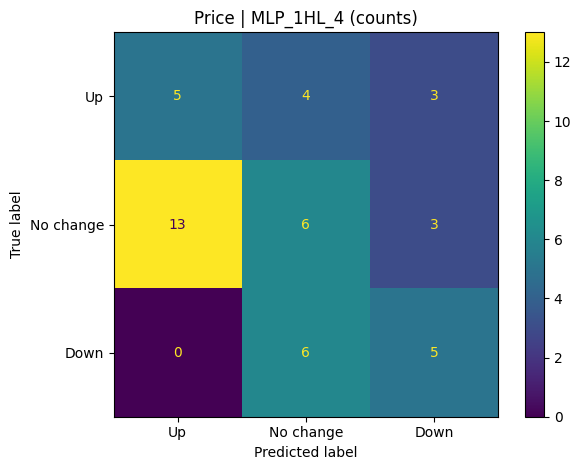

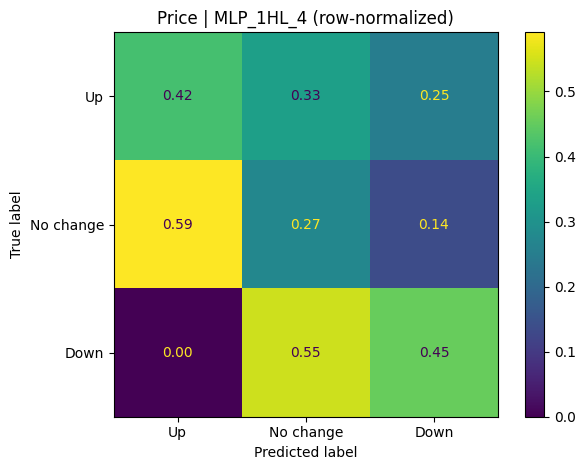

Experiment: Price+Twitter | Best model: MLP_2HL_8_4 | Macro-F1=0.2766±0.1928


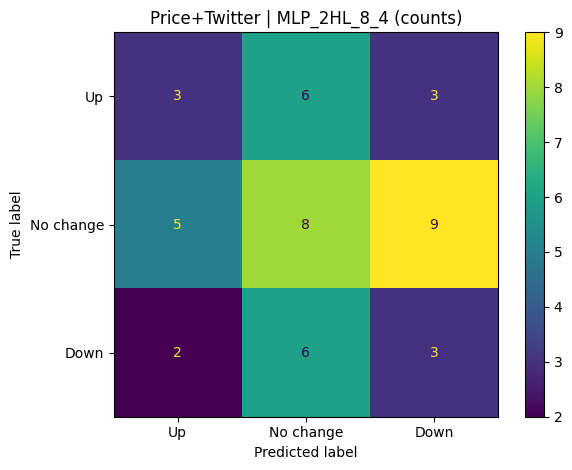

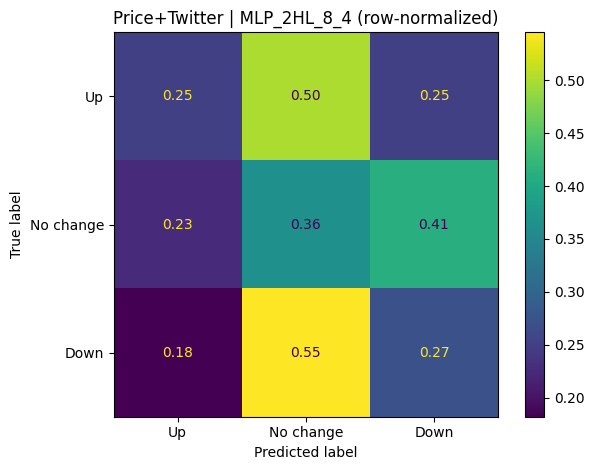

Experiment: Price+News | Best model: MLP_2HL_8_4 | Macro-F1=0.3276±0.0667


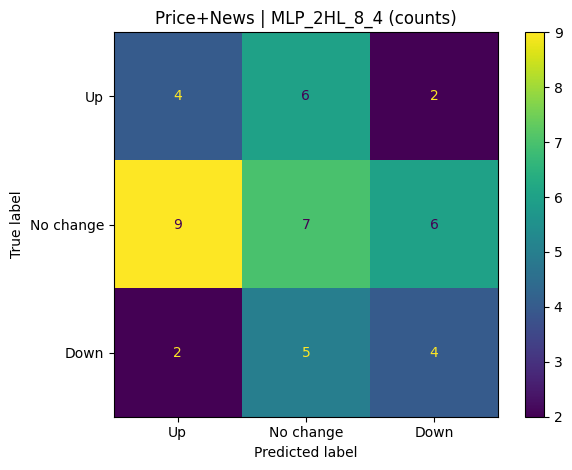

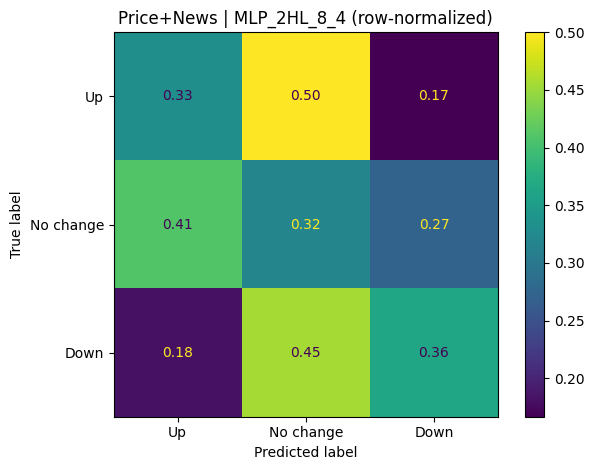

Experiment: All | Best model: MLP_1HL_4 | Macro-F1=0.3658±0.0284


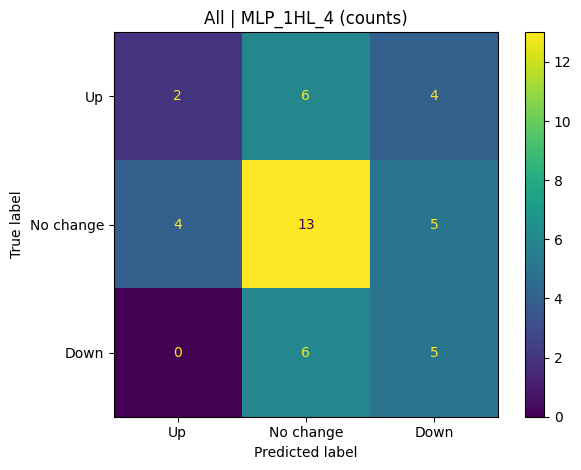

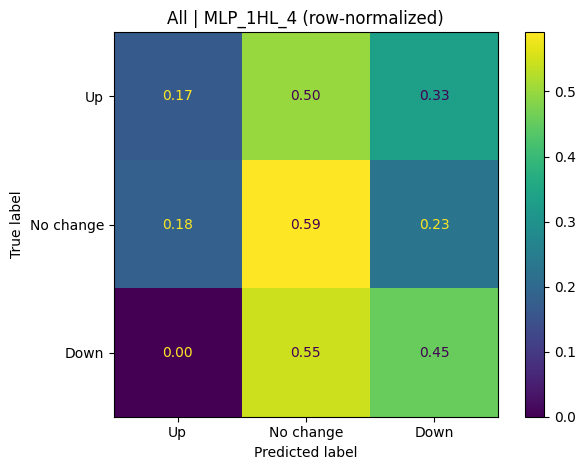

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight

# =========================
# 0) CONFIG (Walk-forward)
# =========================
INITIAL_TRAIN_SIZE = 90
TEST_SIZE = 15
STEP_SIZE = 15
PRINT_FOLDS = True

# 3-class encoding (as requested)
LABELS = [0, 1, 2]
LABEL_NAMES = ["Up", "No change", "Down"]

# =========================
# 1) Paths (DATASET A)
# =========================
main_path = ".."
BTC_Price_News_Tweets_Sentiment_path = main_path + "/data/processed/BTC_Price_News_Tweets_Sentiment.csv"

# =========================
# 2) Load & basic cleaning
# =========================
df = pd.read_csv(BTC_Price_News_Tweets_Sentiment_path)
df.columns = [c.strip() for c in df.columns]

print("COLUMNS IN CSV:")
print(df.columns.tolist())

# Beklenen kolonlar (Dataset A)
req_cols = ["date", "open", "high", "low", "close", "volume"]
for c in req_cols:
    if c not in df.columns:
        raise ValueError(f"Missing required column '{c}'. Columns: {df.columns.tolist()}")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

def to_num(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

# Fiyat kolonlarını sayısala çevir
for c in ["open", "high", "low", "close", "volume"]:
    df[c] = to_num(df[c])

# Twitter ve News kolonlarını sayısala çevir (varsa)
twitter_cols = ["twitter_neg", "twitter_neu", "twitter_pos", "twitter_compound"]
news_cols    = ["news_neg", "news_neu", "news_pos", "news_compound"]

for c in twitter_cols:
    if c in df.columns:
        df[c] = to_num(df[c])
for c in news_cols:
    if c in df.columns:
        df[c] = to_num(df[c])

# En azından fiyat kolonlarında NaN olanları at
df = df.dropna(subset=["open", "high", "low", "close", "volume"]).copy()

# =========================
# 3) Feature engineering (NO TAU)
# =========================
def make_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()

    # log return
    d["ret_1"] = np.log(d["close"]).diff()

    # next-day return used for labeling (not a feature directly)
    d["next_ret"] = d["ret_1"].shift(-1)

    # lagged returns
    for lag in [1, 2, 3, 5, 10]:
        d[f"ret_lag_{lag}"] = d["ret_1"].shift(lag)

    # rolling volatility
    for w in [7, 14, 30]:
        d[f"vol_{w}"] = d["ret_1"].rolling(w).std()

    # momentum via MA ratio
    for w in [7, 14, 30]:
        ma = d["close"].rolling(w).mean()
        d[f"mom_{w}"] = (d["close"] / ma) - 1.0

    # candle/range
    d["range_pct"] = (d["high"] - d["low"]) / d["close"]
    d["body_pct"]  = (d["close"] - d["open"]) / d["open"]

    # volume features
    d["log_vol"] = np.log(d["volume"].replace(0, np.nan))
    d["vol_chg"] = d["volume"].pct_change()
    d["vol_mom_14"] = (d["volume"] / d["volume"].rolling(14).mean()) - 1.0

    engineered = [
        "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
        "vol_7","vol_14","vol_30",
        "mom_7","mom_14","mom_30",
        "range_pct","body_pct",
        "log_vol","vol_chg","vol_mom_14",
        "next_ret"
    ]
    return d.dropna(subset=engineered).copy()

price_features = [
    "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
    "vol_7","vol_14","vol_30",
    "mom_7","mom_14","mom_30",
    "range_pct","body_pct",
    "log_vol","vol_chg","vol_mom_14"
]

d_base = make_features(df)

# =========================
# 4) Walk-forward splitter
# =========================
def walk_forward_splits(n, initial_train_size, test_size, step_size):
    train_end = initial_train_size
    while train_end + test_size <= n:
        train_idx = np.arange(0, train_end)
        test_idx  = np.arange(train_end, train_end + test_size)
        yield train_idx, test_idx
        train_end += step_size

# =========================
# 5) Models (ONLY requested MLPs)
# =========================
def get_models(random_state=42):
    common_kwargs = dict(
        max_iter=5000,
        random_state=random_state
    )
    return {
        # a) MLP with 1 hidden layer with 8 units
        "MLP_1HL_8": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(8,), **common_kwargs))
        ]),
        # b) MLP with 1 hidden layer with 4 units
        "MLP_1HL_4": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(4,), **common_kwargs))
        ]),
        # c) MLP with 2 hidden layers with 4 and 4 units
        "MLP_2HL_4_4": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(4, 4), **common_kwargs))
        ]),
        # d) MLP with 2 hidden layers with 8 and 4 units
        "MLP_2HL_8_4": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(hidden_layer_sizes=(8, 4), **common_kwargs))
        ]),
    }

# =========================
# 6) Walk-forward evaluation (Dynamic q_low/q_high per fold)
# =========================
def _balanced_oversample(X, y, random_state=42):
    """
    Simple class-balance oversampling (with replacement).
    Needed because sklearn MLPClassifier may not support sample_weight.
    """
    rng = np.random.RandomState(random_state)
    classes, counts = np.unique(y, return_counts=True)
    max_count = int(counts.max())

    idx_balanced = []
    for cls, cnt in zip(classes, counts):
        idx = np.where(y == cls)[0]
        if int(cnt) < max_count:
            extra = rng.choice(idx, size=max_count - int(cnt), replace=True)
            idx_new = np.concatenate([idx, extra])
        else:
            idx_new = idx
        idx_balanced.append(idx_new)

    idx_balanced = np.concatenate(idx_balanced)
    rng.shuffle(idx_balanced)
    return X[idx_balanced], y[idx_balanced]

def fit_predict_with_weights(model, X_train, y_train, X_test):
    sw = compute_sample_weight(class_weight="balanced", y=y_train)

    # Try sample_weight first; if not supported (common for MLP), oversample.
    try:
        if isinstance(model, Pipeline):
            model.fit(X_train, y_train, **{"clf__sample_weight": sw})
        else:
            model.fit(X_train, y_train, sample_weight=sw)
    except TypeError:
        Xb, yb = _balanced_oversample(X_train, y_train, random_state=42)
        model.fit(Xb, yb)

    return model.predict(X_test)

def fold_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
    }

def eval_walk_forward_dynamic_terciles(model, d_exp, feature_cols, exp_name, model_name, low_q=0.33, high_q=0.67):
    """
    For EACH fold:
      - compute q_low/q_high from TRAIN slice only
      - label BOTH train and test with these fold thresholds
    """
    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        raise ValueError(
            f"{exp_name}: Not enough rows ({len(d_exp)}) for walk-forward "
            f"(need at least {INITIAL_TRAIN_SIZE + TEST_SIZE})."
        )

    dates = pd.to_datetime(d_exp["date"]).reset_index(drop=True)

    y_true_all, y_pred_all, date_all = [], [], []
    per_fold = []

    fold_no = 0
    for train_idx, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        fold_no += 1

        train_start = dates.iloc[train_idx[0]].date()
        train_end   = dates.iloc[train_idx[-1]].date()
        test_start  = dates.iloc[test_idx[0]].date()
        test_end    = dates.iloc[test_idx[-1]].date()

        train = d_exp.iloc[train_idx]
        test  = d_exp.iloc[test_idx]

        # Fold-specific thresholds from TRAIN only
        train_rets = train["next_ret"].values
        q_low_fold  = float(np.quantile(train_rets, low_q))
        q_high_fold = float(np.quantile(train_rets, high_q))

        # Fold-specific labels (apply same thresholds to train and test)
        y_train = np.where(train["next_ret"].values >= q_high_fold, 0,
                  np.where(train["next_ret"].values <= q_low_fold, 2, 1))
        y_test  = np.where(test["next_ret"].values  >= q_high_fold, 0,
                  np.where(test["next_ret"].values  <= q_low_fold, 2, 1))

        if PRINT_FOLDS:
            dist_tr = pd.Series(y_train).value_counts().sort_index().to_dict()
            dist_te = pd.Series(y_test).value_counts().sort_index().to_dict()
            print(f"[{exp_name} | {model_name}] Fold {fold_no:02d}  "
                  f"TRAIN: {train_start} -> {train_end}   "
                  f"TEST: {test_start} -> {test_end}  | "
                  f"q_low={q_low_fold:.6f}, q_high={q_high_fold:.6f}  | "
                  f"TRAIN dist={dist_tr}  TEST dist={dist_te}")

        X_train = train[feature_cols].values
        X_test  = test[feature_cols].values

        y_pred = fit_predict_with_weights(model, X_train, y_train, X_test)

        y_true_all.append(y_test)
        y_pred_all.append(y_pred)
        date_all.append(dates.iloc[test_idx].values)

        per_fold.append(fold_metrics(y_test, y_pred))

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    date_all = np.concatenate(date_all)

    mf = pd.DataFrame(per_fold)
    summary = {
        "n_folds": fold_no,
        "accuracy_mean": float(mf["accuracy"].mean()),
        "accuracy_std": float(mf["accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "balanced_accuracy_mean": float(mf["balanced_accuracy"].mean()),
        "balanced_accuracy_std": float(mf["balanced_accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_f1_mean": float(mf["macro_f1"].mean()),
        "macro_f1_std": float(mf["macro_f1"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_precision_mean": float(mf["macro_precision"].mean()),
        "macro_precision_std": float(mf["macro_precision"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_recall_mean": float(mf["macro_recall"].mean()),
        "macro_recall_std": float(mf["macro_recall"].std(ddof=1)) if fold_no > 1 else 0.0,
    }

    return summary, date_all, y_true_all, y_pred_all

# =========================
# 7) Experiments (Dataset A: Price/Twitter/News/All)
# =========================
experiments = []

# 1) Price
experiments.append(("Price", d_base.copy(), price_features))

# 2) Price + Twitter
if all(c in d_base.columns for c in twitter_cols):
    d_tw = d_base.dropna(subset=twitter_cols).copy()
    experiments.append(("Price+Twitter", d_tw, price_features + twitter_cols))
else:
    print("Skipping Price+Twitter (missing twitter columns).")

# 3) Price + News
if all(c in d_base.columns for c in news_cols):
    d_nw = d_base.dropna(subset=news_cols).copy()
    experiments.append(("Price+News", d_nw, price_features + news_cols))
else:
    print("Skipping Price+News (missing news columns).")

# 4) All
if all(c in d_base.columns for c in twitter_cols + news_cols):
    d_all = d_base.dropna(subset=twitter_cols + news_cols).copy()
    experiments.append(("All", d_all, price_features + twitter_cols + news_cols))
else:
    print("Skipping All (missing twitter/news columns).")

# =========================
# 8) Run all models, store results + predictions
# =========================
all_results = []
pred_store = {}  # (setup, model) -> (dates, y_true, y_pred)

for exp_name, d_exp, feat_cols in experiments:
    print("\n" + "#" * 70)
    print(f"EXP: {exp_name}")
    print(f"Rows: {len(d_exp)} | Features: {len(feat_cols)}")
    print(f"Overall date range: {pd.to_datetime(d_exp['date']).min().date()} -> {pd.to_datetime(d_exp['date']).max().date()}")

    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        print(f"Skipping {exp_name}: Not enough rows for walk-forward (need {INITIAL_TRAIN_SIZE + TEST_SIZE}).")
        continue

    print(f"[{exp_name}] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.")

    dates_exp = pd.to_datetime(d_exp["date"]).reset_index(drop=True)
    print(f"Walk-forward first TEST start: {dates_exp.iloc[INITIAL_TRAIN_SIZE].date()}")
    last_test_end = None
    for _, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        last_test_end = dates_exp.iloc[test_idx[-1]].date()
    print(f"Walk-forward last  TEST end  : {last_test_end}")
    print("#" * 70)

    for model_name, model in get_models(42).items():
        summary, dates_all, y_true_all, y_pred_all = eval_walk_forward_dynamic_terciles(
            model, d_exp, feat_cols, exp_name, model_name, low_q=0.33, high_q=0.67
        )

        print(f"--> {model_name} summary: "
              f"Acc={summary['accuracy_mean']:.4f}±{summary['accuracy_std']:.4f} | "
              f"BalAcc={summary['balanced_accuracy_mean']:.4f}±{summary['balanced_accuracy_std']:.4f} | "
              f"Prec={summary['macro_precision_mean']:.4f}±{summary['macro_precision_std']:.4f} | "
              f"Rec={summary['macro_recall_mean']:.4f}±{summary['macro_recall_std']:.4f} | "
              f"F1={summary['macro_f1_mean']:.4f}±{summary['macro_f1_std']:.4f}")

        row = {"setup": exp_name, "model": model_name, **summary}
        all_results.append(row)
        pred_store[(exp_name, model_name)] = (dates_all, y_true_all, y_pred_all)

comp = pd.DataFrame(all_results)

def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"

comp["accuracy_mean±std"]   = comp.apply(lambda r: pm(r["accuracy_mean"], r["accuracy_std"]), axis=1)
comp["precision_mean±std"]  = comp.apply(lambda r: pm(r["macro_precision_mean"], r["macro_precision_std"]), axis=1)
comp["recall_mean±std"]     = comp.apply(lambda r: pm(r["macro_recall_mean"], r["macro_recall_std"]), axis=1)
comp["macro_f1_mean±std"]   = comp.apply(lambda r: pm(r["macro_f1_mean"], r["macro_f1_std"]), axis=1)
comp["bal_acc_mean±std"]    = comp.apply(lambda r: pm(r["balanced_accuracy_mean"], r["balanced_accuracy_std"]), axis=1)

comp_sorted = comp.sort_values(["setup", "macro_f1_mean"], ascending=[True, False]).reset_index(drop=True)

print("\n============================")
print("COMPARISON TABLE (Dataset A; Walk-forward; dynamic fold terciles; mean ± std across folds)")
print("============================")
show_cols = [
    "setup", "model", "n_folds",
    "accuracy_mean±std", "precision_mean±std", "recall_mean±std",
    "macro_f1_mean±std", "bal_acc_mean±std"
]
print(comp_sorted[show_cols])

# =========================
# 9) Confusion Matrix: best model per experiment (by macro_f1_mean)
# =========================
def show_confusion(y_true, y_pred, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABEL_NAMES)
    disp.plot(values_format=".2f" if normalize else "d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

print("\n============================")
print("CONFUSION MATRICES (Best model per experiment by Macro-F1 mean)")
print("============================")

for exp_name, _, _ in experiments:
    if exp_name not in comp_sorted["setup"].unique():
        continue

    sub = comp_sorted[comp_sorted["setup"] == exp_name].sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
    best_model = sub.loc[0, "model"]
    best_f1_m = sub.loc[0, "macro_f1_mean"]
    best_f1_s = sub.loc[0, "macro_f1_std"]

    dates_all, y_true_all, y_pred_all = pred_store[(exp_name, best_model)]
    print(f"Experiment: {exp_name} | Best model: {best_model} | Macro-F1={best_f1_m:.4f}±{best_f1_s:.4f}")

    show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {best_model} (counts)", normalize=None)
    show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {best_model} (row-normalized)", normalize="true")


# HYPERPARAMETER TUNİNG;

  # Traditional_ML_Models-BTC_Price_Fear_Greed_News_Sentiment_ACCORDING_TO_TOP5_GRID_SEARCH_RESULTS

COLUMNS IN CSV:
['date', 'close', 'high', 'low', 'open', 'volume', 'Fear_Greed_Value', 'News_neg', 'News_neu', 'News_pos', 'News_compound']

Detected News Sentiment columns: ['News_neg', 'News_neu', 'News_pos', 'News_compound']

######################################################################
EXP: Price
Rows: 678 | Features: 16
Overall date range: 2022-02-09 -> 2023-12-18
[Price] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.
Walk-forward first TEST start: 2023-03-16
Walk-forward last  TEST end  : 2023-12-10
######################################################################
[Price | LogReg] Fold 01  TRAIN: 2022-02-09 -> 2023-03-15   TEST: 2023-03-16 -> 2023-04-14  | q_low=-0.009430, q_high=0.006971  | TRAIN dist={0: 132, 1: 136, 2: 132}  TEST dist={0: 12, 1: 11, 2: 7}
[Price | LogReg] Fold 02  TRAIN: 2022-02-09 -> 2023-04-14   TEST: 2023-04-15 -> 2023-05-14  | q_low=-0.009031, q_high=0.007297  | TRAIN dist={0: 142, 1: 146, 2: 142}  TE

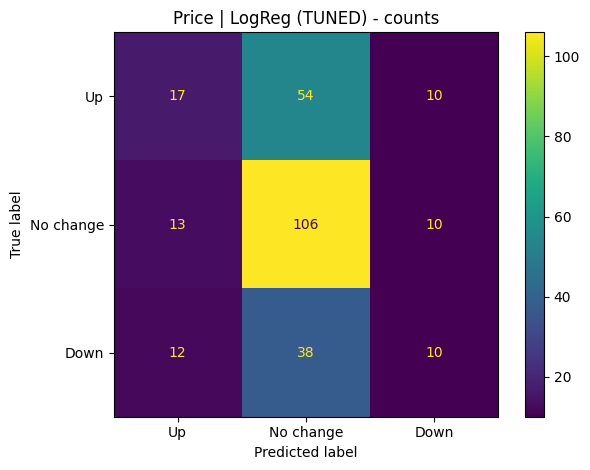

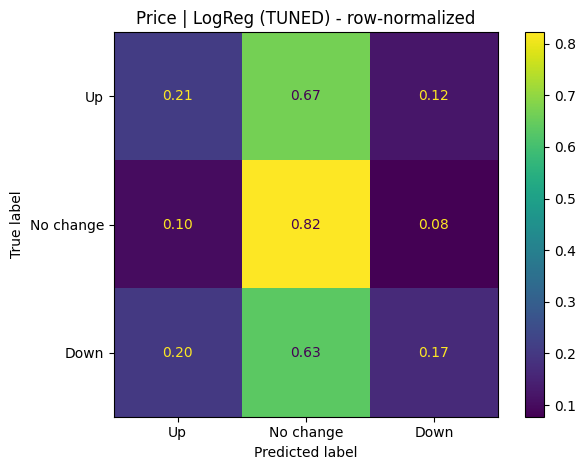


Price+News | LogReg (TUNED) | Macro-F1=0.3454±0.0559
Best params: {'clf__solver': 'saga', 'clf__penalty': 'l2', 'clf__C': np.float64(0.1873817422860383)}


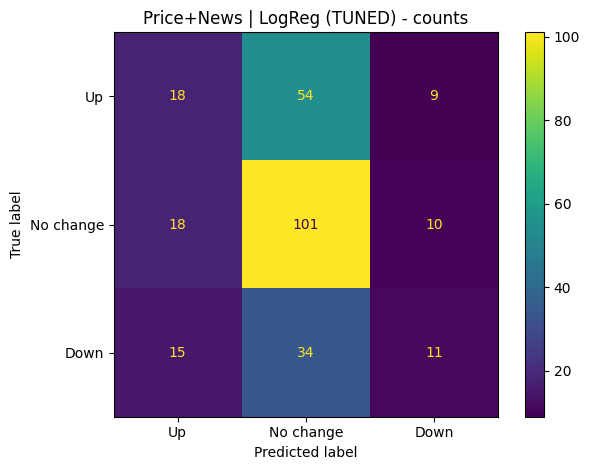

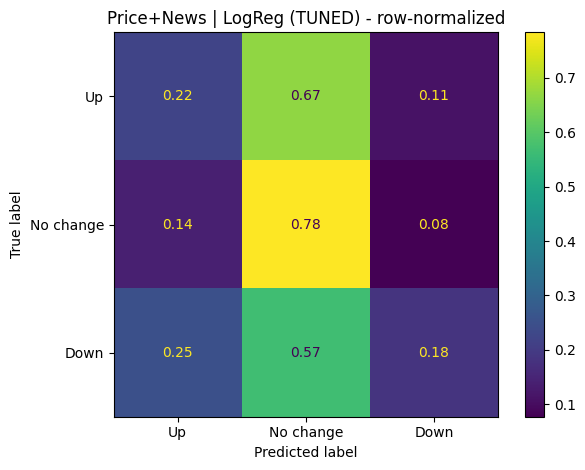


Price | LinearSVM (TUNED) | Macro-F1=0.3399±0.0916
Best params: {'clf__C': np.float64(0.0002894266124716752)}


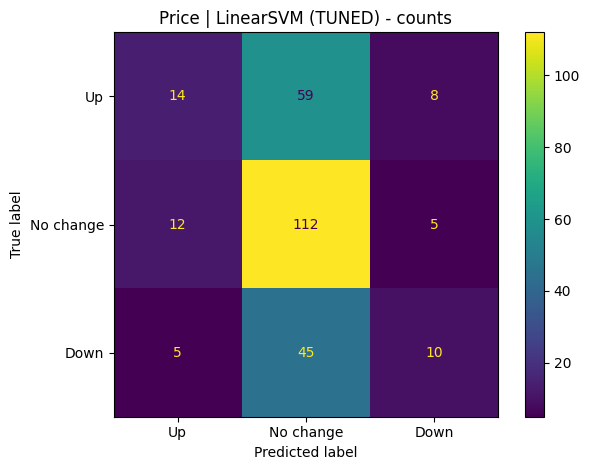

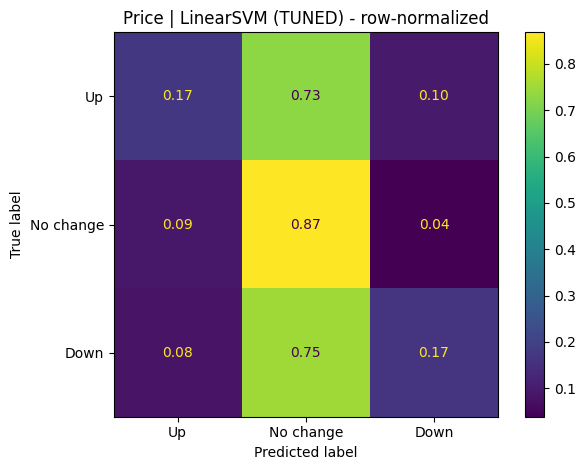


Price+News | LinearSVM (TUNED) | Macro-F1=0.3340±0.0715
Best params: {'clf__C': np.float64(0.0024244620170823282)}


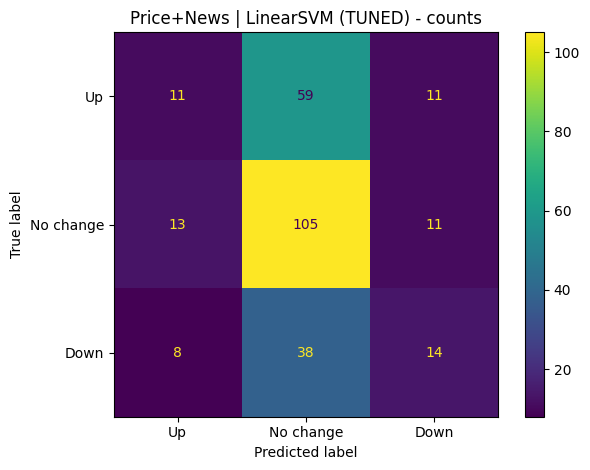

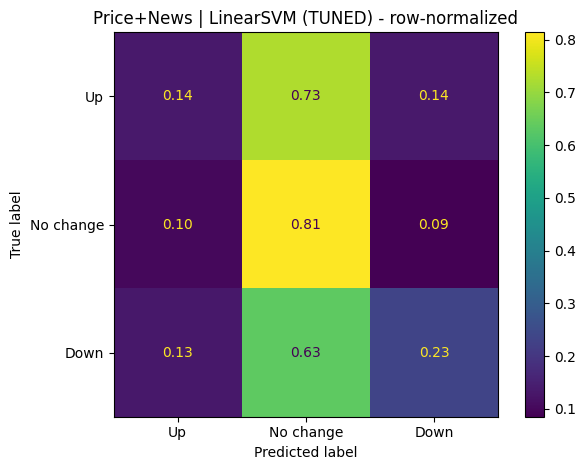


Price+Fear | LinearSVM (TUNED) | Macro-F1=0.3154±0.0737
Best params: {'clf__C': np.float64(0.0002894266124716752)}


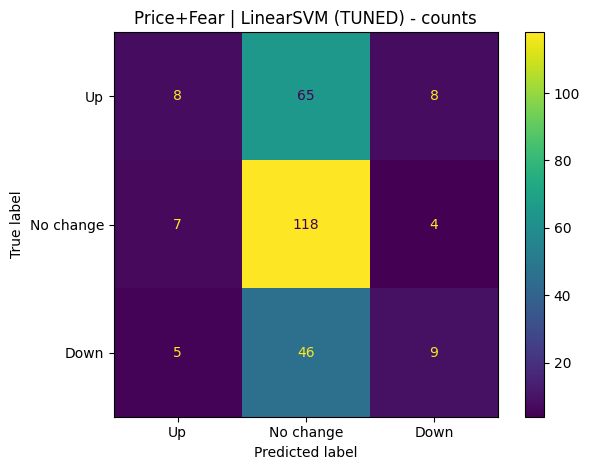

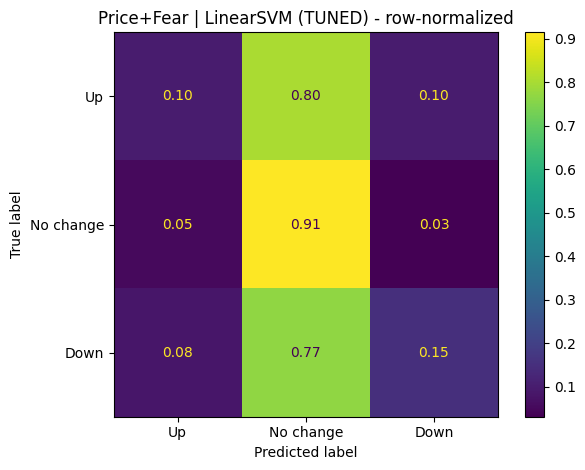

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, make_scorer
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.base import clone

warnings.filterwarnings("ignore")

# =========================
# 0) CONFIG (Walk-forward)
# =========================
INITIAL_TRAIN_SIZE = 400
TEST_SIZE = 30
STEP_SIZE = 30
PRINT_FOLDS = True

# 3-class encoding
LABELS = [0, 1, 2]
LABEL_NAMES = ["Up", "No change", "Down"]

RANDOM_STATE = 42

# =========================
# 1) Paths
# =========================
main_path = ".."
BTC_Price_Fear_Greed_News_Sentiment_path = main_path + "/data/processed/BTC_Price_Fear_Greed_News_Sentiment.csv"

# =========================
# 2) Load & basic cleaning
# =========================
df = pd.read_csv(BTC_Price_Fear_Greed_News_Sentiment_path)
df.columns = [c.strip() for c in df.columns]

print("COLUMNS IN CSV:")
print(df.columns.tolist())

def pick_col(cands):
    for c in cands:
        if c in df.columns:
            return c
    return None

date_col = pick_col(["Date", "date", "DATE"])
if date_col is None:
    raise ValueError(f"Date column not found. Columns: {df.columns.tolist()}")

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

open_col  = pick_col(["Open", "open"])
high_col  = pick_col(["High", "high"])
low_col   = pick_col(["Low", "low"])
close_col = pick_col(["Close", "close", "Adj Close", "adj_close"])
vol_col   = pick_col(["Volume", "volume", "Vol.", "vol"])

missing = [name for name, col in [
    ("Open", open_col), ("High", high_col), ("Low", low_col),
    ("Close", close_col), ("Volume", vol_col)
] if col is None]
if missing:
    raise ValueError(f"Missing required price columns: {missing}. Columns: {df.columns.tolist()}")

fear_col = "Fear_Greed_Value" if "Fear_Greed_Value" in df.columns else None
if fear_col is None:
    print("\nWARNING: 'Fear_Greed_Value' not found -> Fear experiments may be skipped.\n")

def to_num(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

for c in [open_col, high_col, low_col, close_col, vol_col]:
    df[c] = to_num(df[c])
if fear_col is not None:
    df[fear_col] = to_num(df[fear_col])

# =========================
# 3) Detect News Sentiment columns
# =========================
def detect_news_sentiment_cols(columns):
    cols = list(columns)

    preferred_sets = [
        ["news_negative", "news_neutral", "news_positive", "news_compound"],
        ["news_neg", "news_neu", "news_pos", "news_compound"],
    ]
    for s in preferred_sets:
        if all(c in cols for c in s):
            return s

    lowmap = {c: c.lower() for c in cols}
    def find_one(keys):
        for c in cols:
            lc = lowmap[c]
            if "news" in lc and any(k in lc for k in keys):
                return c
        return None

    neg = find_one(["neg", "negative"])
    neu = find_one(["neu", "neutral"])
    pos = find_one(["pos", "positive"])
    comp = find_one(["compound", "score", "vader"])

    found = [c for c in [neg, neu, pos, comp] if c is not None]
    if len(found) > 0:
        return found

    fallback = ["negative", "neutral", "positive", "compound"]
    if all(c in cols for c in fallback):
        return fallback

    return []

news_cols = detect_news_sentiment_cols(df.columns)
if len(news_cols) == 0:
    print("\nWARNING: News sentiment columns not detected -> News experiments may be skipped.\n")
else:
    print("\nDetected News Sentiment columns:", news_cols)
    for c in news_cols:
        df[c] = to_num(df[c])

# =========================
# 4) Feature engineering (NO TAU)
# =========================
def make_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()

    d["ret_1"] = np.log(d[close_col]).diff()
    d["next_ret"] = d["ret_1"].shift(-1)

    for lag in [1, 2, 3, 5, 10]:
        d[f"ret_lag_{lag}"] = d["ret_1"].shift(lag)

    for w in [7, 14, 30]:
        d[f"vol_{w}"] = d["ret_1"].rolling(w).std()

    for w in [7, 14, 30]:
        ma = d[close_col].rolling(w).mean()
        d[f"mom_{w}"] = (d[close_col] / ma) - 1.0

    d["range_pct"] = (d[high_col] - d[low_col]) / d[close_col]
    d["body_pct"]  = (d[close_col] - d[open_col]) / d[open_col]

    d["log_vol"] = np.log(d[vol_col].replace(0, np.nan))
    d["vol_chg"] = d[vol_col].pct_change()
    d["vol_mom_14"] = (d[vol_col] / d[vol_col].rolling(14).mean()) - 1.0

    engineered = [
        "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
        "vol_7","vol_14","vol_30",
        "mom_7","mom_14","mom_30",
        "range_pct","body_pct",
        "log_vol","vol_chg","vol_mom_14",
        "next_ret"
    ]
    return d.dropna(subset=engineered).copy()

price_features = [
    "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
    "vol_7","vol_14","vol_30",
    "mom_7","mom_14","mom_30",
    "range_pct","body_pct",
    "log_vol","vol_chg","vol_mom_14"
]

d_base = make_features(df)

# =========================
# 5) Walk-forward splitter
# =========================
def walk_forward_splits(n, initial_train_size, test_size, step_size):
    train_end = initial_train_size
    while train_end + test_size <= n:
        train_idx = np.arange(0, train_end)
        test_idx  = np.arange(train_end, train_end + test_size)
        yield train_idx, test_idx
        train_end += step_size

# =========================
# 6) Models
# =========================
def get_models(random_state=42):
    return {
        "LogReg": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=5000, random_state=random_state))
        ]),
        "LinearSVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LinearSVC(random_state=random_state))
        ]),
        "RBFSVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", random_state=random_state))
        ]),
        "RandomForest": RandomForestClassifier(random_state=random_state),
        "ExtraTrees": ExtraTreesClassifier(random_state=random_state),
        "GradBoost": GradientBoostingClassifier(random_state=random_state),
        "HistGradBoost": HistGradientBoostingClassifier(random_state=random_state),
    }

# =========================
# 7) Core evaluation helpers (dynamic fold terciles)
# =========================
def fit_predict_with_weights(model, X_train, y_train, X_test):
    sw = compute_sample_weight(class_weight="balanced", y=y_train)
    if isinstance(model, Pipeline):
        model.fit(X_train, y_train, **{"clf__sample_weight": sw})
    else:
        model.fit(X_train, y_train, sample_weight=sw)
    return model.predict(X_test)

def fold_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
    }

def eval_walk_forward_dynamic_terciles(model, d_exp, feature_cols, exp_name, model_name, low_q=0.33, high_q=0.67):
    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        raise ValueError(
            f"{exp_name}: Not enough rows ({len(d_exp)}) for walk-forward "
            f"(need at least {INITIAL_TRAIN_SIZE + TEST_SIZE})."
        )

    dates = pd.to_datetime(d_exp[date_col]).reset_index(drop=True)

    y_true_all, y_pred_all, date_all = [], [], []
    per_fold = []

    fold_no = 0
    for train_idx, test_idx in walk_forward_splits(
        len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE
    ):
        fold_no += 1

        train_start = dates.iloc[train_idx[0]].date()
        train_end   = dates.iloc[train_idx[-1]].date()
        test_start  = dates.iloc[test_idx[0]].date()
        test_end    = dates.iloc[test_idx[-1]].date()

        train = d_exp.iloc[train_idx]
        test  = d_exp.iloc[test_idx]

        # fold-specific thresholds from TRAIN only
        train_rets = train["next_ret"].values
        q_low_fold = float(np.quantile(train_rets, low_q))
        q_high_fold = float(np.quantile(train_rets, high_q))

        # fold-specific labels (same thresholds applied to train and test)
        y_train = np.where(train["next_ret"].values >= q_high_fold, 0,
                  np.where(train["next_ret"].values <= q_low_fold, 2, 1))
        y_test  = np.where(test["next_ret"].values  >= q_high_fold, 0,
                  np.where(test["next_ret"].values  <= q_low_fold, 2, 1))

        if PRINT_FOLDS:
            dist_tr = pd.Series(y_train).value_counts().sort_index().to_dict()
            dist_te = pd.Series(y_test).value_counts().sort_index().to_dict()
            print(f"[{exp_name} | {model_name}] Fold {fold_no:02d}  "
                  f"TRAIN: {train_start} -> {train_end}   "
                  f"TEST: {test_start} -> {test_end}  | "
                  f"q_low={q_low_fold:.6f}, q_high={q_high_fold:.6f}  | "
                  f"TRAIN dist={dist_tr}  TEST dist={dist_te}")

        X_train = train[feature_cols].values
        X_test  = test[feature_cols].values

        y_pred = fit_predict_with_weights(model, X_train, y_train, X_test)

        y_true_all.append(y_test)
        y_pred_all.append(y_pred)
        date_all.append(dates.iloc[test_idx].values)

        per_fold.append(fold_metrics(y_test, y_pred))

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    date_all = np.concatenate(date_all)

    mf = pd.DataFrame(per_fold)
    summary = {
        "n_folds": fold_no,
        "accuracy_mean": float(mf["accuracy"].mean()),
        "accuracy_std": float(mf["accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "balanced_accuracy_mean": float(mf["balanced_accuracy"].mean()),
        "balanced_accuracy_std": float(mf["balanced_accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_f1_mean": float(mf["macro_f1"].mean()),
        "macro_f1_std": float(mf["macro_f1"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_precision_mean": float(mf["macro_precision"].mean()),
        "macro_precision_std": float(mf["macro_precision"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_recall_mean": float(mf["macro_recall"].mean()),
        "macro_recall_std": float(mf["macro_recall"].std(ddof=1)) if fold_no > 1 else 0.0,
    }

    return summary, date_all, y_true_all, y_pred_all

# =========================
# 8) Experiments: 4 feature sets
# =========================
experiments = []
experiments.append(("Price", d_base.copy(), price_features))

if fear_col is not None:
    d_pf = d_base.copy()
    d_pf["fear_greed"] = d_pf[fear_col]
    d_pf = d_pf.dropna(subset=["fear_greed"]).copy()
    experiments.append(("Price+Fear", d_pf, price_features + ["fear_greed"]))
else:
    print("Skipping Price+Fear (Fear_Greed_Value missing).")

if len(news_cols) > 0:
    d_pn = d_base.copy().dropna(subset=news_cols).copy()
    experiments.append(("Price+News", d_pn, price_features + news_cols))
else:
    print("Skipping Price+News (News sentiment columns not detected).")

if (fear_col is not None) and (len(news_cols) > 0):
    d_pfn = d_base.copy()
    d_pfn["fear_greed"] = d_pfn[fear_col]
    d_pfn = d_pfn.dropna(subset=["fear_greed"] + news_cols).copy()
    experiments.append(("Price+Fear+News", d_pfn, price_features + ["fear_greed"] + news_cols))
else:
    print("Skipping Price+Fear+News (Fear or News missing).")

# =========================
# 9) BASELINE run (all models) to find TOP-5
# =========================
all_results = []
pred_store = {}  # (setup, model, "baseline") -> (dates, y_true, y_pred)

for exp_name, d_exp, feat_cols in experiments:
    print("\n" + "#" * 70)
    print(f"EXP: {exp_name}")
    print(f"Rows: {len(d_exp)} | Features: {len(feat_cols)}")
    print(f"Overall date range: {pd.to_datetime(d_exp[date_col]).min().date()} -> {pd.to_datetime(d_exp[date_col]).max().date()}")

    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        print(f"Skipping {exp_name}: Not enough rows for walk-forward (need {INITIAL_TRAIN_SIZE + TEST_SIZE}).")
        continue

    print(f"[{exp_name}] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.")
    dates_exp = pd.to_datetime(d_exp[date_col]).reset_index(drop=True)
    print(f"Walk-forward first TEST start: {dates_exp.iloc[INITIAL_TRAIN_SIZE].date()}")
    last_test_end = None
    for _, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        last_test_end = dates_exp.iloc[test_idx[-1]].date()
    print(f"Walk-forward last  TEST end  : {last_test_end}")
    print("#" * 70)

    for model_name, model in get_models(RANDOM_STATE).items():
        summary, dates_all, y_true_all, y_pred_all = eval_walk_forward_dynamic_terciles(
            clone(model), d_exp, feat_cols, exp_name, model_name, low_q=0.33, high_q=0.67
        )

        print(f"--> {model_name} summary: "
              f"Acc={summary['accuracy_mean']:.4f}±{summary['accuracy_std']:.4f} | "
              f"BalAcc={summary['balanced_accuracy_mean']:.4f}±{summary['balanced_accuracy_std']:.4f} | "
              f"Prec={summary['macro_precision_mean']:.4f}±{summary['macro_precision_std']:.4f} | "
              f"Rec={summary['macro_recall_mean']:.4f}±{summary['macro_recall_std']:.4f} | "
              f"F1={summary['macro_f1_mean']:.4f}±{summary['macro_f1_std']:.4f}")

        row = {"setup": exp_name, "model": model_name, "phase": "baseline", **summary}
        all_results.append(row)
        pred_store[(exp_name, model_name, "baseline")] = (dates_all, y_true_all, y_pred_all)

comp = pd.DataFrame(all_results)

def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"

comp["accuracy_mean±std"]   = comp.apply(lambda r: pm(r["accuracy_mean"], r["accuracy_std"]), axis=1)
comp["precision_mean±std"]  = comp.apply(lambda r: pm(r["macro_precision_mean"], r["macro_precision_std"]), axis=1)
comp["recall_mean±std"]     = comp.apply(lambda r: pm(r["macro_recall_mean"], r["macro_recall_std"]), axis=1)
comp["macro_f1_mean±std"]   = comp.apply(lambda r: pm(r["macro_f1_mean"], r["macro_f1_std"]), axis=1)
comp["bal_acc_mean±std"]    = comp.apply(lambda r: pm(r["balanced_accuracy_mean"], r["balanced_accuracy_std"]), axis=1)

print("\n============================")
print("BASELINE COMPARISON TABLE (Walk-forward; dynamic fold terciles; mean ± std across folds)")
print("============================")

show_cols = [
    "setup", "model", "n_folds",
    "accuracy_mean±std", "precision_mean±std", "recall_mean±std",
    "macro_f1_mean±std", "bal_acc_mean±std"
]
comp_baseline_sorted = comp.sort_values(["setup", "macro_f1_mean"], ascending=[True, False]).reset_index(drop=True)
print(comp_baseline_sorted[show_cols])

# ---- TOP-5 overall by Macro-F1 mean (across ALL setups/models) ----
top5 = (
    comp[comp["phase"] == "baseline"]
    .sort_values("macro_f1_mean", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("\n============================")
print("TOP-5 BASELINE (Overall) by Macro-F1 mean")
print("============================")
print(top5[["setup", "model", "macro_f1_mean±std", "accuracy_mean±std", "bal_acc_mean±std"]])

# =========================
# 10) Hyperparameter search space (simple/medium)
# =========================
def get_param_distributions(model_name):
    # Keep searches modest (simple/medium)
    if model_name == "LogReg":
        return {
            "clf__C": np.logspace(-3, 2, 12),
            "clf__solver": ["lbfgs", "liblinear", "saga"],
            "clf__penalty": ["l2"],   # keep simple/stable for multiclass
        }
    if model_name == "LinearSVM":
        return {
            "clf__C": np.logspace(-4, 2, 14),
        }
    if model_name == "RBFSVM":
        return {
            "clf__C": np.logspace(-2, 3, 12),
            "clf__gamma": ["scale", "auto"] + list(np.logspace(-4, 0, 8)),
        }
    if model_name == "RandomForest":
        return {
            "n_estimators": [200, 400, 800],
            "max_depth": [None, 4, 6, 8, 12],
            "min_samples_leaf": [1, 2, 4, 8],
            "max_features": ["sqrt", "log2", 0.5],
        }
    if model_name == "ExtraTrees":
        return {
            "n_estimators": [200, 400, 800],
            "max_depth": [None, 4, 6, 8, 12],
            "min_samples_leaf": [1, 2, 4, 8],
            "max_features": ["sqrt", "log2", 0.5],
        }
    if model_name == "GradBoost":
        return {
            "n_estimators": [100, 200, 400],
            "learning_rate": [0.02, 0.05, 0.1, 0.2],
            "max_depth": [2, 3, 4],
            "subsample": [0.7, 0.85, 1.0],
        }
    if model_name == "HistGradBoost":
        return {
            "max_iter": [100, 200, 400],
            "learning_rate": [0.02, 0.05, 0.1, 0.2],
            "max_depth": [None, 3, 5, 7],
            "max_leaf_nodes": [15, 31, 63],
            "l2_regularization": [0.0, 0.1, 1.0],
        }
    return None

macro_f1_scorer = make_scorer(
    f1_score, average="macro", labels=LABELS, zero_division=0
)

# =========================
# 11) Tune on FIRST TRAIN WINDOW only (then evaluate across all folds)
# =========================
def tune_on_first_window(exp_name, d_exp, feat_cols, model_name, base_model,
                         n_splits_inner=4, n_iter=20):
    """
    1) Take the first outer train window (size INITIAL_TRAIN_SIZE)
    2) Build y_train using tercile thresholds from that window only
    3) Do RandomizedSearchCV with TimeSeriesSplit inside that window
    4) Return best_params and a fresh model configured with those params
    """
    # First outer split
    splits = list(walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE))
    if len(splits) == 0:
        raise ValueError(f"{exp_name}: no valid walk-forward splits with given sizes.")
    train_idx, _ = splits[0]

    train = d_exp.iloc[train_idx]
    train_rets = train["next_ret"].values
    q_low = float(np.quantile(train_rets, 0.33))
    q_high = float(np.quantile(train_rets, 0.67))

    y_train = np.where(train["next_ret"].values >= q_high, 0,
              np.where(train["next_ret"].values <= q_low, 2, 1))
    X_train = train[feat_cols].values

    sw = compute_sample_weight(class_weight="balanced", y=y_train)

    param_dist = get_param_distributions(model_name)
    if param_dist is None:
        # no tuning space defined -> return original
        return {}, None, clone(base_model)

    # Inner time-series CV
    tscv = TimeSeriesSplit(n_splits=n_splits_inner)

    # Fit params for sample weights (Pipeline vs non-Pipeline)
    fit_params = {"clf__sample_weight": sw} if isinstance(base_model, Pipeline) else {"sample_weight": sw}

    search = RandomizedSearchCV(
        estimator=clone(base_model),
        param_distributions=param_dist,
        n_iter=min(n_iter, max(5, len(list(param_dist.values())[0])) * 2),
        scoring=macro_f1_scorer,
        cv=tscv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=0
    )

    search.fit(X_train, y_train, **fit_params)

    best_params = search.best_params_
    best_cv_score = float(search.best_score_)

    tuned_model = clone(base_model).set_params(**best_params)
    return best_params, best_cv_score, tuned_model

# =========================
# 12) Run tuning for TOP-5 only, then evaluate tuned models
# =========================
tuned_rows = []
pred_store_tuned = {}  # (setup, model, "tuned") -> (dates, y_true, y_pred)

print("\n" + "="*90)
print("HYPERPARAMETER TUNING + EVALUATION FOR TOP-5 ONLY")
print("="*90)

# helper: find experiment data by name
exp_map = {name: (dexp, feats) for (name, dexp, feats) in experiments}

for i, r in top5.iterrows():
    exp_name = r["setup"]
    model_name = r["model"]

    if exp_name not in exp_map:
        print(f"Skipping {exp_name} (not in experiments map).")
        continue

    d_exp, feat_cols = exp_map[exp_name]
    base_models = get_models(RANDOM_STATE)
    base_model = base_models[model_name]

    print("\n" + "-"*90)
    print(f"[TOP-{i+1}] {exp_name} | {model_name}")
    print("-"*90)

    best_params, best_cv_score, tuned_model = tune_on_first_window(
        exp_name=exp_name,
        d_exp=d_exp,
        feat_cols=feat_cols,
        model_name=model_name,
        base_model=base_model,
        n_splits_inner=4,
        n_iter=20
    )

    if best_params:
        print(f"Best params (picked on FIRST train window via TimeSeriesSplit CV): {best_params}")
        print(f"Best inner-CV Macro-F1: {best_cv_score:.4f}")
    else:
        print("No param grid found for this model -> using default params.")

    # Evaluate tuned model across ALL outer folds (same evaluation as baseline)
    summary_t, dates_all, y_true_all, y_pred_all = eval_walk_forward_dynamic_terciles(
        clone(tuned_model), d_exp, feat_cols, exp_name, model_name + " (TUNED)", low_q=0.33, high_q=0.67
    )

    tuned_rows.append({
        "setup": exp_name,
        "model": model_name,
        "phase": "tuned",
        "best_params": str(best_params) if best_params else "{}",
        "best_inner_cv_macro_f1": best_cv_score if best_params else np.nan,
        **summary_t
    })
    pred_store_tuned[(exp_name, model_name, "tuned")] = (dates_all, y_true_all, y_pred_all)

tuned_df = pd.DataFrame(tuned_rows)

if len(tuned_df) > 0:
    tuned_df["accuracy_mean±std"]   = tuned_df.apply(lambda r: pm(r["accuracy_mean"], r["accuracy_std"]), axis=1)
    tuned_df["precision_mean±std"]  = tuned_df.apply(lambda r: pm(r["macro_precision_mean"], r["macro_precision_std"]), axis=1)
    tuned_df["recall_mean±std"]     = tuned_df.apply(lambda r: pm(r["macro_recall_mean"], r["macro_recall_std"]), axis=1)
    tuned_df["macro_f1_mean±std"]   = tuned_df.apply(lambda r: pm(r["macro_f1_mean"], r["macro_f1_std"]), axis=1)
    tuned_df["bal_acc_mean±std"]    = tuned_df.apply(lambda r: pm(r["balanced_accuracy_mean"], r["balanced_accuracy_std"]), axis=1)

    tuned_sorted = tuned_df.sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)

    print("\n============================")
    print("TUNED TOP-5 RESULTS (Walk-forward; dynamic fold terciles; mean ± std across folds)")
    print("============================")
    print(tuned_sorted[
        ["setup","model","n_folds",
         "macro_f1_mean±std","accuracy_mean±std","bal_acc_mean±std",
         "precision_mean±std","recall_mean±std",
         "best_inner_cv_macro_f1","best_params"
        ]
    ])
else:
    print("\nNo tuned results produced (tuned_df is empty).")

# =========================
# 13) Confusion matrices for tuned TOP-5
# =========================
def show_confusion(y_true, y_pred, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABEL_NAMES)
    disp.plot(values_format=".2f" if normalize else "d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

if len(tuned_df) > 0:
    print("\n============================")
    print("CONFUSION MATRICES (TUNED TOP-5)")
    print("============================")

    # show in tuned performance order
    for _, row in tuned_sorted.iterrows():
        exp_name = row["setup"]
        model_name = row["model"]
        dates_all, y_true_all, y_pred_all = pred_store_tuned[(exp_name, model_name, "tuned")]

        print(f"\n{exp_name} | {model_name} (TUNED) | Macro-F1={row['macro_f1_mean']:.4f}±{row['macro_f1_std']:.4f}")
        print(f"Best params: {row['best_params']}")

        show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {model_name} (TUNED) - counts", normalize=None)
        show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {model_name} (TUNED) - row-normalized", normalize="true")


# Traditional_ML_Models-BTC_Price_Tweet_News_Sentiment_HYPERPARAMETER_TUNING_CODE_BASED_ON_TOP5_RESULTS


COLUMNS IN CSV:
['date', 'close', 'high', 'low', 'open', 'volume', 'twitter_neg', 'twitter_neu', 'twitter_pos', 'twitter_compound', 'news_neg', 'news_neu', 'news_pos', 'news_compound']

######################################################################
EXP: Price
Rows: 136 | Features: 16
Overall date range: 2022-01-22 -> 2023-01-09
[Price] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.
Walk-forward first TEST start: 2022-07-16
Walk-forward last  TEST end  : 2023-01-08
######################################################################
[Price | LogReg] Fold 01  TRAIN: 2022-01-22 -> 2022-07-15   TEST: 2022-07-16 -> 2022-09-15  | q_low=-0.015257, q_high=0.012618  | TRAIN dist={0: 30, 1: 30, 2: 30}  TEST dist={0: 4, 1: 7, 2: 4}
[Price | LogReg] Fold 02  TRAIN: 2022-01-22 -> 2022-09-15   TEST: 2022-10-09 -> 2022-11-13  | q_low=-0.013937, q_high=0.011489  | TRAIN dist={0: 35, 1: 35, 2: 35}  TEST dist={0: 4, 1: 6, 2: 5}
[Price | LogReg] Fold 03

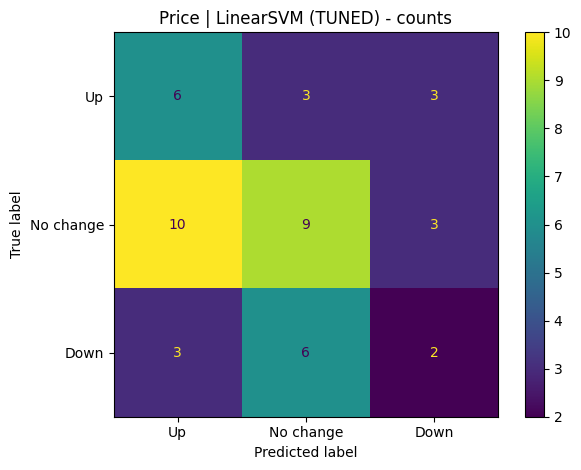

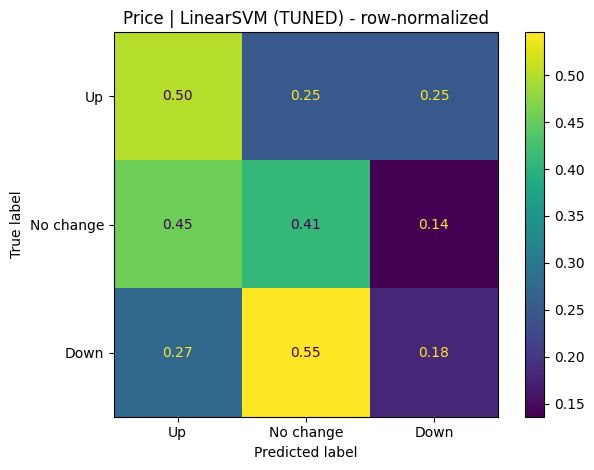


Price+News | LinearSVM (TUNED) | Macro-F1=0.3344±0.0494
Best params: {'clf__C': np.float64(100.0)}


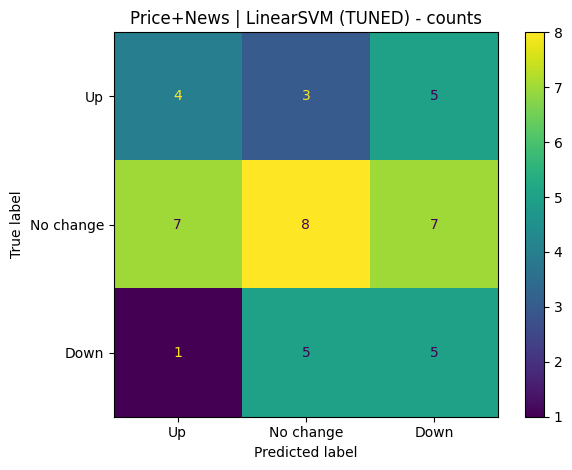

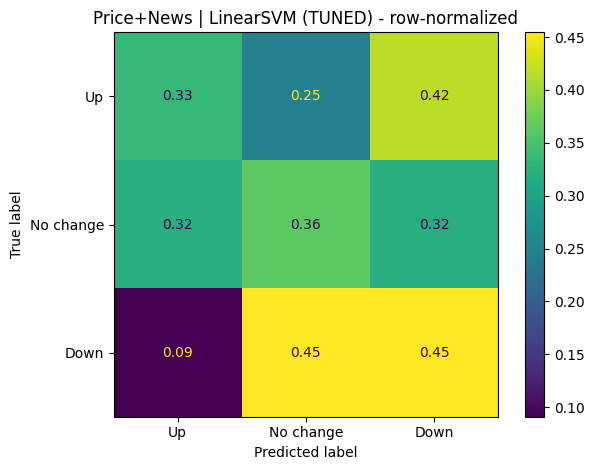


Price+News | LogReg (TUNED) | Macro-F1=0.3344±0.0494
Best params: {'clf__solver': 'liblinear', 'clf__penalty': 'l2', 'clf__C': np.float64(35.11191734215127)}


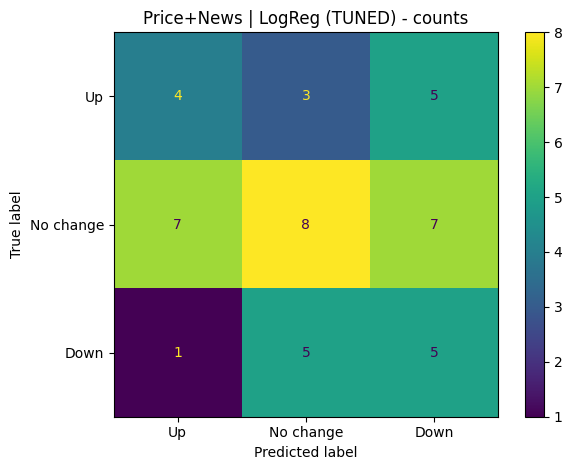

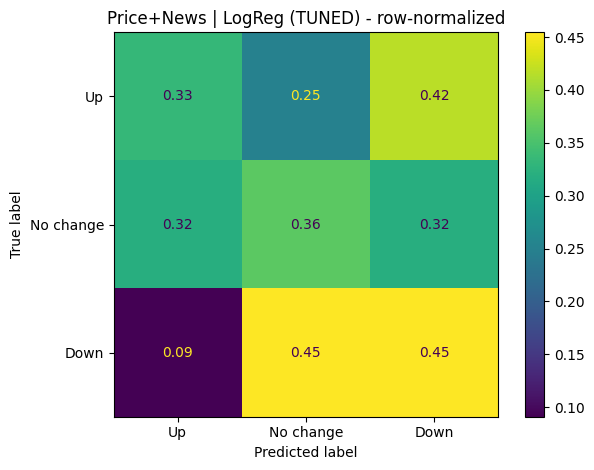


Price | LogReg (TUNED) | Macro-F1=0.3185±0.1027
Best params: {'clf__solver': 'saga', 'clf__penalty': 'l2', 'clf__C': np.float64(4.328761281083057)}


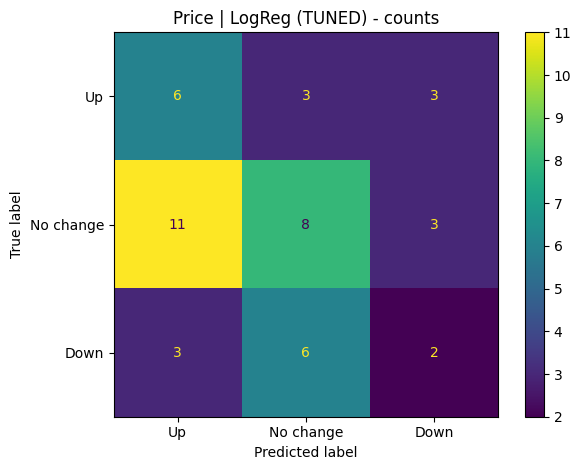

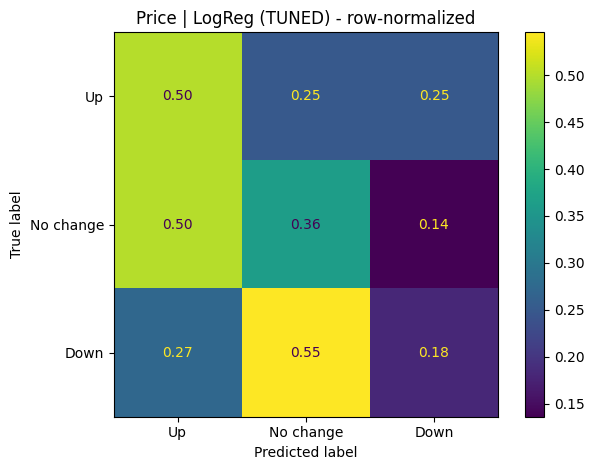


Price+Twitter | LinearSVM (TUNED) | Macro-F1=0.3114±0.0596
Best params: {'clf__C': np.float64(34.55107294592218)}


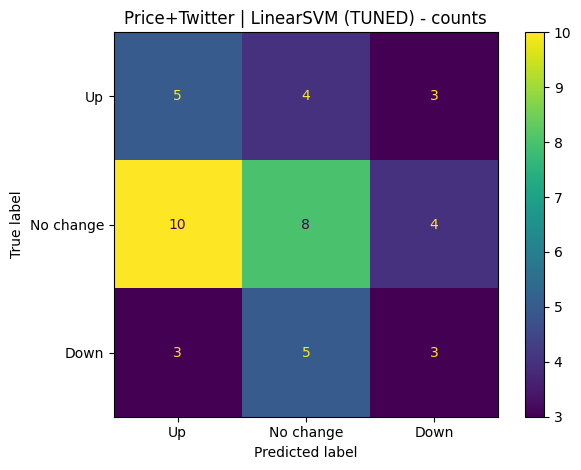

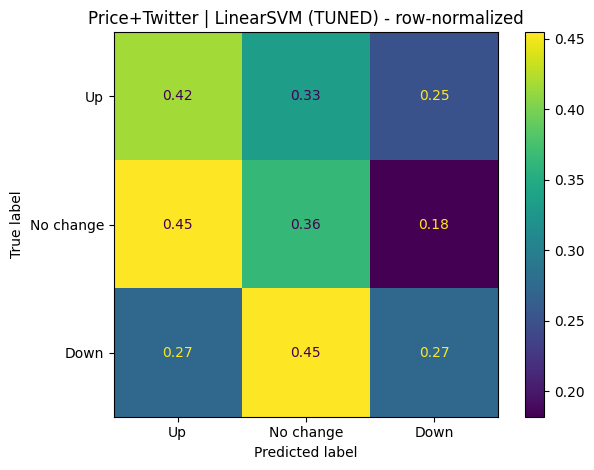

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, ConfusionMatrixDisplay, make_scorer
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.base import clone

warnings.filterwarnings("ignore")

# =========================
# 0) CONFIG (Walk-forward)
# =========================
INITIAL_TRAIN_SIZE = 90
TEST_SIZE = 15
STEP_SIZE = 15
PRINT_FOLDS = True

LABELS = [0, 1, 2]
LABEL_NAMES = ["Up", "No change", "Down"]

RANDOM_STATE = 42

# =========================
# 1) Paths (DATASET A)
# =========================
main_path = ".."
BTC_Price_News_Tweets_Sentiment_path = main_path + "/data/processed/BTC_Price_News_Tweets_Sentiment.csv"

# =========================
# 2) Load & basic cleaning
# =========================
df = pd.read_csv(BTC_Price_News_Tweets_Sentiment_path)
df.columns = [c.strip() for c in df.columns]

print("COLUMNS IN CSV:")
print(df.columns.tolist())

req_cols = ["date", "open", "high", "low", "close", "volume"]
for c in req_cols:
    if c not in df.columns:
        raise ValueError(f"Missing required column '{c}'. Columns: {df.columns.tolist()}")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

def to_num(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

for c in ["open", "high", "low", "close", "volume"]:
    df[c] = to_num(df[c])

twitter_cols = ["twitter_neg", "twitter_neu", "twitter_pos", "twitter_compound"]
news_cols    = ["news_neg", "news_neu", "news_pos", "news_compound"]

for c in twitter_cols:
    if c in df.columns:
        df[c] = to_num(df[c])
for c in news_cols:
    if c in df.columns:
        df[c] = to_num(df[c])

df = df.dropna(subset=["open", "high", "low", "close", "volume"]).copy()

# =========================
# 3) Feature engineering (NO TAU)
# =========================
def make_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()

    d["ret_1"] = np.log(d["close"]).diff()
    d["next_ret"] = d["ret_1"].shift(-1)

    for lag in [1, 2, 3, 5, 10]:
        d[f"ret_lag_{lag}"] = d["ret_1"].shift(lag)

    for w in [7, 14, 30]:
        d[f"vol_{w}"] = d["ret_1"].rolling(w).std()

    for w in [7, 14, 30]:
        ma = d["close"].rolling(w).mean()
        d[f"mom_{w}"] = (d["close"] / ma) - 1.0

    d["range_pct"] = (d["high"] - d["low"]) / d["close"]
    d["body_pct"]  = (d["close"] - d["open"]) / d["open"]

    d["log_vol"] = np.log(d["volume"].replace(0, np.nan))
    d["vol_chg"] = d["volume"].pct_change()
    d["vol_mom_14"] = (d["volume"] / d["volume"].rolling(14).mean()) - 1.0

    engineered = [
        "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
        "vol_7","vol_14","vol_30",
        "mom_7","mom_14","mom_30",
        "range_pct","body_pct",
        "log_vol","vol_chg","vol_mom_14",
        "next_ret"
    ]
    return d.dropna(subset=engineered).copy()

price_features = [
    "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
    "vol_7","vol_14","vol_30",
    "mom_7","mom_14","mom_30",
    "range_pct","body_pct",
    "log_vol","vol_chg","vol_mom_14"
]

d_base = make_features(df)

# =========================
# 4) Walk-forward splitter
# =========================
def walk_forward_splits(n, initial_train_size, test_size, step_size):
    train_end = initial_train_size
    while train_end + test_size <= n:
        train_idx = np.arange(0, train_end)
        test_idx  = np.arange(train_end, train_end + test_size)
        yield train_idx, test_idx
        train_end += step_size

# =========================
# 5) Models
# =========================
def get_models(random_state=42):
    return {
        "LogReg": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=5000, random_state=random_state))
        ]),
        "LinearSVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LinearSVC(random_state=random_state))
        ]),
        "RBFSVM": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", random_state=random_state))
        ]),
        "RandomForest": RandomForestClassifier(random_state=random_state),
        "ExtraTrees": ExtraTreesClassifier(random_state=random_state),
        "GradBoost": GradientBoostingClassifier(random_state=random_state),
        "HistGradBoost": HistGradientBoostingClassifier(random_state=random_state),
    }

# =========================
# 6) Walk-forward evaluation (Dynamic q_low/q_high per fold)
# =========================
def fit_predict_with_weights(model, X_train, y_train, X_test):
    sw = compute_sample_weight(class_weight="balanced", y=y_train)
    if isinstance(model, Pipeline):
        model.fit(X_train, y_train, **{"clf__sample_weight": sw})
    else:
        model.fit(X_train, y_train, sample_weight=sw)
    return model.predict(X_test)

def fold_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
    }

def eval_walk_forward_dynamic_terciles(model, d_exp, feature_cols, exp_name, model_name, low_q=0.33, high_q=0.67):
    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        raise ValueError(
            f"{exp_name}: Not enough rows ({len(d_exp)}) for walk-forward "
            f"(need at least {INITIAL_TRAIN_SIZE + TEST_SIZE})."
        )

    dates = pd.to_datetime(d_exp["date"]).reset_index(drop=True)

    y_true_all, y_pred_all, date_all = [], [], []
    per_fold = []
    fold_no = 0

    for train_idx, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        fold_no += 1

        train_start = dates.iloc[train_idx[0]].date()
        train_end   = dates.iloc[train_idx[-1]].date()
        test_start  = dates.iloc[test_idx[0]].date()
        test_end    = dates.iloc[test_idx[-1]].date()

        train = d_exp.iloc[train_idx]
        test  = d_exp.iloc[test_idx]

        train_rets = train["next_ret"].values
        q_low_fold  = float(np.quantile(train_rets, low_q))
        q_high_fold = float(np.quantile(train_rets, high_q))

        y_train = np.where(train["next_ret"].values >= q_high_fold, 0,
                  np.where(train["next_ret"].values <= q_low_fold, 2, 1))
        y_test  = np.where(test["next_ret"].values  >= q_high_fold, 0,
                  np.where(test["next_ret"].values  <= q_low_fold, 2, 1))

        if PRINT_FOLDS:
            dist_tr = pd.Series(y_train).value_counts().sort_index().to_dict()
            dist_te = pd.Series(y_test).value_counts().sort_index().to_dict()
            print(f"[{exp_name} | {model_name}] Fold {fold_no:02d}  "
                  f"TRAIN: {train_start} -> {train_end}   "
                  f"TEST: {test_start} -> {test_end}  | "
                  f"q_low={q_low_fold:.6f}, q_high={q_high_fold:.6f}  | "
                  f"TRAIN dist={dist_tr}  TEST dist={dist_te}")

        X_train = train[feature_cols].values
        X_test  = test[feature_cols].values

        y_pred = fit_predict_with_weights(model, X_train, y_train, X_test)

        y_true_all.append(y_test)
        y_pred_all.append(y_pred)
        date_all.append(dates.iloc[test_idx].values)

        per_fold.append(fold_metrics(y_test, y_pred))

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    date_all = np.concatenate(date_all)

    mf = pd.DataFrame(per_fold)
    summary = {
        "n_folds": fold_no,
        "accuracy_mean": float(mf["accuracy"].mean()),
        "accuracy_std": float(mf["accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "balanced_accuracy_mean": float(mf["balanced_accuracy"].mean()),
        "balanced_accuracy_std": float(mf["balanced_accuracy"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_f1_mean": float(mf["macro_f1"].mean()),
        "macro_f1_std": float(mf["macro_f1"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_precision_mean": float(mf["macro_precision"].mean()),
        "macro_precision_std": float(mf["macro_precision"].std(ddof=1)) if fold_no > 1 else 0.0,
        "macro_recall_mean": float(mf["macro_recall"].mean()),
        "macro_recall_std": float(mf["macro_recall"].std(ddof=1)) if fold_no > 1 else 0.0,
    }

    return summary, date_all, y_true_all, y_pred_all

# =========================
# 7) Experiments
# =========================
experiments = []

experiments.append(("Price", d_base.copy(), price_features))

if all(c in d_base.columns for c in twitter_cols):
    d_tw = d_base.dropna(subset=twitter_cols).copy()
    experiments.append(("Price+Twitter", d_tw, price_features + twitter_cols))
else:
    print("Skipping Price+Twitter (missing twitter columns).")

if all(c in d_base.columns for c in news_cols):
    d_nw = d_base.dropna(subset=news_cols).copy()
    experiments.append(("Price+News", d_nw, price_features + news_cols))
else:
    print("Skipping Price+News (missing news columns).")

if all(c in d_base.columns for c in twitter_cols + news_cols):
    d_all = d_base.dropna(subset=twitter_cols + news_cols).copy()
    experiments.append(("All", d_all, price_features + twitter_cols + news_cols))
else:
    print("Skipping All (missing twitter/news columns).")

# =========================
# 8) BASELINE run (all models) to find TOP-5 overall
# =========================
all_results = []
pred_store = {}  # (setup, model, phase) -> (dates, y_true, y_pred)

for exp_name, d_exp, feat_cols in experiments:
    print("\n" + "#" * 70)
    print(f"EXP: {exp_name}")
    print(f"Rows: {len(d_exp)} | Features: {len(feat_cols)}")
    print(f"Overall date range: {pd.to_datetime(d_exp['date']).min().date()} -> {pd.to_datetime(d_exp['date']).max().date()}")

    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        print(f"Skipping {exp_name}: Not enough rows for walk-forward (need {INITIAL_TRAIN_SIZE + TEST_SIZE}).")
        continue

    print(f"[{exp_name}] NOTE: Labels are computed dynamically per fold from that fold's TRAIN next_ret terciles.")

    dates_exp = pd.to_datetime(d_exp["date"]).reset_index(drop=True)
    print(f"Walk-forward first TEST start: {dates_exp.iloc[INITIAL_TRAIN_SIZE].date()}")
    last_test_end = None
    for _, test_idx in walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE):
        last_test_end = dates_exp.iloc[test_idx[-1]].date()
    print(f"Walk-forward last  TEST end  : {last_test_end}")
    print("#" * 70)

    for model_name, model in get_models(RANDOM_STATE).items():
        summary, dates_all, y_true_all, y_pred_all = eval_walk_forward_dynamic_terciles(
            clone(model), d_exp, feat_cols, exp_name, model_name, low_q=0.33, high_q=0.67
        )

        print(f"--> {model_name} summary: "
              f"Acc={summary['accuracy_mean']:.4f}±{summary['accuracy_std']:.4f} | "
              f"BalAcc={summary['balanced_accuracy_mean']:.4f}±{summary['balanced_accuracy_std']:.4f} | "
              f"Prec={summary['macro_precision_mean']:.4f}±{summary['macro_precision_std']:.4f} | "
              f"Rec={summary['macro_recall_mean']:.4f}±{summary['macro_recall_std']:.4f} | "
              f"F1={summary['macro_f1_mean']:.4f}±{summary['macro_f1_std']:.4f}")

        row = {"setup": exp_name, "model": model_name, "phase": "baseline", **summary}
        all_results.append(row)
        pred_store[(exp_name, model_name, "baseline")] = (dates_all, y_true_all, y_pred_all)

comp = pd.DataFrame(all_results)

def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"

comp["accuracy_mean±std"]   = comp.apply(lambda r: pm(r["accuracy_mean"], r["accuracy_std"]), axis=1)
comp["precision_mean±std"]  = comp.apply(lambda r: pm(r["macro_precision_mean"], r["macro_precision_std"]), axis=1)
comp["recall_mean±std"]     = comp.apply(lambda r: pm(r["macro_recall_mean"], r["macro_recall_std"]), axis=1)
comp["macro_f1_mean±std"]   = comp.apply(lambda r: pm(r["macro_f1_mean"], r["macro_f1_std"]), axis=1)
comp["bal_acc_mean±std"]    = comp.apply(lambda r: pm(r["balanced_accuracy_mean"], r["balanced_accuracy_std"]), axis=1)

comp_sorted = comp.sort_values(["setup", "macro_f1_mean"], ascending=[True, False]).reset_index(drop=True)

print("\n============================")
print("BASELINE COMPARISON TABLE (Dataset A; Walk-forward; dynamic fold terciles; mean ± std across folds)")
print("============================")
show_cols = [
    "setup", "model", "n_folds",
    "accuracy_mean±std", "precision_mean±std", "recall_mean±std",
    "macro_f1_mean±std", "bal_acc_mean±std"
]
print(comp_sorted[show_cols])

# ---- TOP-5 overall by Macro-F1 mean (across ALL setups/models) ----
top5 = (
    comp[comp["phase"] == "baseline"]
    .sort_values("macro_f1_mean", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("\n============================")
print("TOP-5 BASELINE (Overall) by Macro-F1 mean")
print("============================")
print(top5[["setup", "model", "macro_f1_mean±std", "accuracy_mean±std", "bal_acc_mean±std"]])

# =========================
# 9) Hyperparameter search space (simple/medium)
# =========================
def get_param_distributions(model_name):
    if model_name == "LogReg":
        return {
            "clf__C": np.logspace(-3, 2, 12),
            "clf__solver": ["lbfgs", "liblinear", "saga"],
            "clf__penalty": ["l2"],
        }
    if model_name == "LinearSVM":
        return {"clf__C": np.logspace(-4, 2, 14)}
    if model_name == "RBFSVM":
        return {
            "clf__C": np.logspace(-2, 3, 12),
            "clf__gamma": ["scale", "auto"] + list(np.logspace(-4, 0, 8)),
        }
    if model_name == "RandomForest":
        return {
            "n_estimators": [200, 400, 800],
            "max_depth": [None, 4, 6, 8, 12],
            "min_samples_leaf": [1, 2, 4, 8],
            "max_features": ["sqrt", "log2", 0.5],
        }
    if model_name == "ExtraTrees":
        return {
            "n_estimators": [200, 400, 800],
            "max_depth": [None, 4, 6, 8, 12],
            "min_samples_leaf": [1, 2, 4, 8],
            "max_features": ["sqrt", "log2", 0.5],
        }
    if model_name == "GradBoost":
        return {
            "n_estimators": [100, 200, 400],
            "learning_rate": [0.02, 0.05, 0.1, 0.2],
            "max_depth": [2, 3, 4],
            "subsample": [0.7, 0.85, 1.0],
        }
    if model_name == "HistGradBoost":
        return {
            "max_iter": [100, 200, 400],
            "learning_rate": [0.02, 0.05, 0.1, 0.2],
            "max_depth": [None, 3, 5, 7],
            "max_leaf_nodes": [15, 31, 63],
            "l2_regularization": [0.0, 0.1, 1.0],
        }
    return None

macro_f1_scorer = make_scorer(
    f1_score, average="macro", labels=LABELS, zero_division=0
)

# =========================
# 10) Tune on FIRST TRAIN WINDOW only (then evaluate across all folds)
# =========================
def tune_on_first_window(exp_name, d_exp, feat_cols, model_name, base_model,
                         n_splits_inner=3, n_iter=20):
    splits = list(walk_forward_splits(len(d_exp), INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE))
    if len(splits) == 0:
        raise ValueError(f"{exp_name}: no valid walk-forward splits with given sizes.")
    train_idx, _ = splits[0]

    train = d_exp.iloc[train_idx]
    train_rets = train["next_ret"].values
    q_low = float(np.quantile(train_rets, 0.33))
    q_high = float(np.quantile(train_rets, 0.67))

    y_train = np.where(train["next_ret"].values >= q_high, 0,
              np.where(train["next_ret"].values <= q_low, 2, 1))
    X_train = train[feat_cols].values

    sw = compute_sample_weight(class_weight="balanced", y=y_train)

    param_dist = get_param_distributions(model_name)
    if param_dist is None:
        return {}, None, clone(base_model)

    # With small data, keep inner splits small (n_splits_inner=3 default)
    tscv = TimeSeriesSplit(n_splits=n_splits_inner)

    fit_params = {"clf__sample_weight": sw} if isinstance(base_model, Pipeline) else {"sample_weight": sw}

    search = RandomizedSearchCV(
        estimator=clone(base_model),
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring=macro_f1_scorer,
        cv=tscv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=0
    )

    search.fit(X_train, y_train, **fit_params)

    best_params = search.best_params_
    best_cv_score = float(search.best_score_)

    tuned_model = clone(base_model).set_params(**best_params)
    return best_params, best_cv_score, tuned_model

# =========================
# 11) Run tuning for TOP-5 only, then evaluate tuned models
# =========================
tuned_rows = []
pred_store_tuned = {}  # (setup, model, "tuned") -> (dates, y_true, y_pred)

print("\n" + "="*90)
print("HYPERPARAMETER TUNING + EVALUATION FOR TOP-5 ONLY (Dataset A)")
print("="*90)

exp_map = {name: (dexp, feats) for (name, dexp, feats) in experiments}

for i, r in top5.iterrows():
    exp_name = r["setup"]
    model_name = r["model"]

    if exp_name not in exp_map:
        print(f"Skipping {exp_name} (not in experiments map).")
        continue

    d_exp, feat_cols = exp_map[exp_name]
    base_models = get_models(RANDOM_STATE)
    base_model = base_models[model_name]

    print("\n" + "-"*90)
    print(f"[TOP-{i+1}] {exp_name} | {model_name}")
    print("-"*90)

    best_params, best_cv_score, tuned_model = tune_on_first_window(
        exp_name=exp_name,
        d_exp=d_exp,
        feat_cols=feat_cols,
        model_name=model_name,
        base_model=base_model,
        n_splits_inner=3,
        n_iter=20
    )

    if best_params:
        print(f"Best params (picked on FIRST train window via TimeSeriesSplit CV): {best_params}")
        print(f"Best inner-CV Macro-F1: {best_cv_score:.4f}")
    else:
        print("No param grid found for this model -> using default params.")

    summary_t, dates_all, y_true_all, y_pred_all = eval_walk_forward_dynamic_terciles(
        clone(tuned_model), d_exp, feat_cols, exp_name, model_name + " (TUNED)", low_q=0.33, high_q=0.67
    )

    tuned_rows.append({
        "setup": exp_name,
        "model": model_name,
        "phase": "tuned",
        "best_params": str(best_params) if best_params else "{}",
        "best_inner_cv_macro_f1": best_cv_score if best_params else np.nan,
        **summary_t
    })
    pred_store_tuned[(exp_name, model_name, "tuned")] = (dates_all, y_true_all, y_pred_all)

tuned_df = pd.DataFrame(tuned_rows)

if len(tuned_df) > 0:
    tuned_df["accuracy_mean±std"]   = tuned_df.apply(lambda r: pm(r["accuracy_mean"], r["accuracy_std"]), axis=1)
    tuned_df["precision_mean±std"]  = tuned_df.apply(lambda r: pm(r["macro_precision_mean"], r["macro_precision_std"]), axis=1)
    tuned_df["recall_mean±std"]     = tuned_df.apply(lambda r: pm(r["macro_recall_mean"], r["macro_recall_std"]), axis=1)
    tuned_df["macro_f1_mean±std"]   = tuned_df.apply(lambda r: pm(r["macro_f1_mean"], r["macro_f1_std"]), axis=1)
    tuned_df["bal_acc_mean±std"]    = tuned_df.apply(lambda r: pm(r["balanced_accuracy_mean"], r["balanced_accuracy_std"]), axis=1)

    tuned_sorted = tuned_df.sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)

    print("\n============================")
    print("TUNED TOP-5 RESULTS (Dataset A; Walk-forward; dynamic fold terciles; mean ± std across folds)")
    print("============================")
    print(tuned_sorted[
        ["setup","model","n_folds",
         "macro_f1_mean±std","accuracy_mean±std","bal_acc_mean±std",
         "precision_mean±std","recall_mean±std",
         "best_inner_cv_macro_f1","best_params"
        ]
    ])
else:
    print("\nNo tuned results produced (tuned_df is empty).")

# =========================
# 12) Confusion matrices for tuned TOP-5
# =========================
def show_confusion(y_true, y_pred, title, normalize=None):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS, normalize=normalize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=LABEL_NAMES)
    disp.plot(values_format=".2f" if normalize else "d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

if len(tuned_df) > 0:
    print("\n============================")
    print("CONFUSION MATRICES (TUNED TOP-5) - Dataset A")
    print("============================")

    for _, row in tuned_sorted.iterrows():
        exp_name = row["setup"]
        model_name = row["model"]
        dates_all, y_true_all, y_pred_all = pred_store_tuned[(exp_name, model_name, "tuned")]

        print(f"\n{exp_name} | {model_name} (TUNED) | Macro-F1={row['macro_f1_mean']:.4f}±{row['macro_f1_std']:.4f}")
        print(f"Best params: {row['best_params']}")

        show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {model_name} (TUNED) - counts", normalize=None)
        show_confusion(y_true_all, y_pred_all, title=f"{exp_name} | {model_name} (TUNED) - row-normalized", normalize="true")


  # Deep_Models-BTC_Price_Fear_Greed_News_Sentiment_ACCORDING_TO_TOP5_GRID_SEARCH_RESULTS

In [ ]:

import numpy as np
import pandas as pd
from itertools import product
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.base import clone

# -------------------------
# 0) CONFIG
# -------------------------
INITIAL_TRAIN_SIZE = 400
TEST_SIZE = 30
STEP_SIZE = 30

LOW_Q = 0.33
HIGH_Q = 0.67

RANDOM_STATE = 42
MAX_ITER = 1000   # <<<<<< 5000 -> 1000 (speed)

LABELS = [0, 1, 2]  # Up, No change, Down

# TUNING SPEED CONTROL:
MAX_PARAM_COMBOS_PER_MODEL = 40   # <<<<<< her model için en fazla 40 kombinasyon dene
PARAM_SAMPLE_SEED = 123

# -------------------------
# 1) PATH
# -------------------------
main_path = ".."
BTC_Price_Fear_Greed_News_Sentiment_path = main_path + "/data/processed/BTC_Price_Fear_Greed_News_Sentiment.csv"

# -------------------------
# 2) Helpers
# -------------------------
def pick_col(df, cands):
    for c in cands:
        if c in df.columns:
            return c
    return None

def to_num(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

def walk_forward_splits(n, initial_train_size, test_size, step_size):
    train_end = initial_train_size
    while train_end + test_size <= n:
        train_idx = np.arange(0, train_end)
        test_idx  = np.arange(train_end, train_end + test_size)
        yield train_idx, test_idx
        train_end += step_size

def _balanced_oversample(X, y, random_state=42):
    rng = np.random.RandomState(random_state)
    classes, counts = np.unique(y, return_counts=True)
    max_count = int(counts.max())
    idx_balanced = []
    for cls, cnt in zip(classes, counts):
        idx = np.where(y == cls)[0]
        if int(cnt) < max_count:
            extra = rng.choice(idx, size=max_count - int(cnt), replace=True)
            idx_new = np.concatenate([idx, extra])
        else:
            idx_new = idx
        idx_balanced.append(idx_new)
    idx_balanced = np.concatenate(idx_balanced)
    rng.shuffle(idx_balanced)
    return X[idx_balanced], y[idx_balanced]

def fit_predict_with_weights(model, X_train, y_train, X_test, random_state=42):
    sw = compute_sample_weight(class_weight="balanced", y=y_train)
    try:
        if isinstance(model, Pipeline):
            model.fit(X_train, y_train, **{"clf__sample_weight": sw})
        else:
            model.fit(X_train, y_train, sample_weight=sw)
    except TypeError:
        Xb, yb = _balanced_oversample(X_train, y_train, random_state=random_state)
        model.fit(Xb, yb)
    return model.predict(X_test)

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0)

def eval_walk_forward_dynamic_terciles(model, d_exp, feature_cols, date_col,
                                      initial_train_size, test_size, step_size,
                                      low_q=0.33, high_q=0.67, random_state=42):
    if len(d_exp) < (initial_train_size + test_size):
        return None

    fold_scores = []
    fold_acc = []
    fold_balacc = []
    fold_no = 0

    for train_idx, test_idx in walk_forward_splits(len(d_exp), initial_train_size, test_size, step_size):
        fold_no += 1
        train = d_exp.iloc[train_idx]
        test  = d_exp.iloc[test_idx]

        train_rets = train["next_ret"].values
        q_low_fold = float(np.quantile(train_rets, low_q))
        q_high_fold = float(np.quantile(train_rets, high_q))

        y_train = np.where(train["next_ret"].values >= q_high_fold, 0,
                  np.where(train["next_ret"].values <= q_low_fold, 2, 1))
        y_test  = np.where(test["next_ret"].values  >= q_high_fold, 0,
                  np.where(test["next_ret"].values  <= q_low_fold, 2, 1))

        X_train = train[feature_cols].values
        X_test  = test[feature_cols].values

        m = clone(model)
        y_pred = fit_predict_with_weights(m, X_train, y_train, X_test, random_state=random_state)

        fold_scores.append(macro_f1(y_test, y_pred))
        fold_acc.append(accuracy_score(y_test, y_pred))
        fold_balacc.append(balanced_accuracy_score(y_test, y_pred))

    fs = np.array(fold_scores, float)
    fa = np.array(fold_acc, float)
    fb = np.array(fold_balacc, float)

    return {
        "n_folds": fold_no,
        "macro_f1_mean": float(fs.mean()),
        "macro_f1_std": float(fs.std(ddof=1) if len(fs) > 1 else 0.0),
        "acc_mean": float(fa.mean()),
        "balacc_mean": float(fb.mean()),
    }

def detect_news_sentiment_cols(columns):
    cols = list(columns)
    preferred_sets = [
        ["news_negative", "news_neutral", "news_positive", "news_compound"],
        ["news_neg", "news_neu", "news_pos", "news_compound"],
    ]
    for s in preferred_sets:
        if all(c in cols for c in s):
            return s

    lowmap = {c: c.lower() for c in cols}
    def find_one(keys):
        for c in cols:
            lc = lowmap[c]
            if "news" in lc and any(k in lc for k in keys):
                return c
        return None

    neg = find_one(["neg", "negative"])
    neu = find_one(["neu", "neutral"])
    pos = find_one(["pos", "positive"])
    comp = find_one(["compound", "score", "vader"])
    found = [c for c in [neg, neu, pos, comp] if c is not None]
    if len(found) > 0:
        return found

    fallback = ["negative", "neutral", "positive", "compound"]
    if all(c in cols for c in fallback):
        return fallback

    return []

def make_features(df, open_col, high_col, low_col, close_col, vol_col):
    d = df.copy()
    d["ret_1"] = np.log(d[close_col]).diff()
    d["next_ret"] = d["ret_1"].shift(-1)

    for lag in [1,2,3,5,10]:
        d[f"ret_lag_{lag}"] = d["ret_1"].shift(lag)

    for w in [7,14,30]:
        d[f"vol_{w}"] = d["ret_1"].rolling(w).std()

    for w in [7,14,30]:
        ma = d[close_col].rolling(w).mean()
        d[f"mom_{w}"] = (d[close_col] / ma) - 1.0

    d["range_pct"] = (d[high_col] - d[low_col]) / d[close_col]
    d["body_pct"]  = (d[close_col] - d[open_col]) / d[open_col]

    d["log_vol"] = np.log(d[vol_col].replace(0, np.nan))
    d["vol_chg"] = d[vol_col].pct_change()
    d["vol_mom_14"] = (d[vol_col] / d[vol_col].rolling(14).mean()) - 1.0

    engineered = [
        "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
        "vol_7","vol_14","vol_30",
        "mom_7","mom_14","mom_30",
        "range_pct","body_pct",
        "log_vol","vol_chg","vol_mom_14",
        "next_ret"
    ]
    return d.dropna(subset=engineered).copy()

def make_mlp_pipeline(hidden_layer_sizes, random_state=42, max_iter=1000):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes,
            max_iter=max_iter,
            random_state=random_state
        ))
    ])

# -------------------------
# 3) LOAD + CLEAN
# -------------------------
df = pd.read_csv(BTC_Price_Fear_Greed_News_Sentiment_path)
df.columns = [c.strip() for c in df.columns]

date_col = pick_col(df, ["Date", "date", "DATE"])
if date_col is None:
    raise ValueError(f"Date column not found. Columns: {df.columns.tolist()}")

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

open_col  = pick_col(df, ["Open", "open"])
high_col  = pick_col(df, ["High", "high"])
low_col   = pick_col(df, ["Low", "low"])
close_col = pick_col(df, ["Close", "close", "Adj Close", "adj_close"])
vol_col   = pick_col(df, ["Volume", "volume", "Vol.", "vol"])

missing = [name for name, col in [
    ("Open", open_col), ("High", high_col), ("Low", low_col),
    ("Close", close_col), ("Volume", vol_col)
] if col is None]
if missing:
    raise ValueError(f"Missing required price columns: {missing}. Columns: {df.columns.tolist()}")

fear_col = "Fear_Greed_Value" if "Fear_Greed_Value" in df.columns else None
news_cols = detect_news_sentiment_cols(df.columns)

for c in [open_col, high_col, low_col, close_col, vol_col]:
    df[c] = to_num(df[c])
if fear_col is not None:
    df[fear_col] = to_num(df[fear_col])
if len(news_cols) > 0:
    for c in news_cols:
        df[c] = to_num(df[c])

# -------------------------
# 4) FEATURES + EXPERIMENTS
# -------------------------
d_base = make_features(df, open_col, high_col, low_col, close_col, vol_col)

price_features = [
    "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
    "vol_7","vol_14","vol_30",
    "mom_7","mom_14","mom_30",
    "range_pct","body_pct",
    "log_vol","vol_chg","vol_mom_14"
]

experiments = []
experiments.append(("Price", d_base.copy(), price_features))

if fear_col is not None:
    d_pf = d_base.copy()
    d_pf["fear_greed"] = d_pf[fear_col]
    d_pf = d_pf.dropna(subset=["fear_greed"]).copy()
    experiments.append(("Price+Fear", d_pf, price_features + ["fear_greed"]))

if len(news_cols) > 0:
    d_pn = d_base.copy().dropna(subset=news_cols).copy()
    experiments.append(("Price+News", d_pn, price_features + news_cols))

if (fear_col is not None) and (len(news_cols) > 0):
    d_pfn = d_base.copy()
    d_pfn["fear_greed"] = d_pfn[fear_col]
    d_pfn = d_pfn.dropna(subset=["fear_greed"] + news_cols).copy()
    experiments.append(("Price+Fear+News", d_pfn, price_features + ["fear_greed"] + news_cols))

print("Experiments created:")
for e, d, f in experiments:
    print(f"- {e}: rows={len(d)}, features={len(f)}")

# -------------------------
# 5) BASE EVAL -> TOP-5
# -------------------------
archs = {
    "MLP_1HL_8": (8,),
    "MLP_1HL_4": (4,),
    "MLP_2HL_4_4": (4,4),
    "MLP_2HL_8_4": (8,4),
}

base_rows = []
for exp_name, d_exp, feat_cols in experiments:
    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        continue
    for model_name, hls in archs.items():
        model = make_mlp_pipeline(hls, random_state=RANDOM_STATE, max_iter=MAX_ITER)
        res = eval_walk_forward_dynamic_terciles(
            model, d_exp, feat_cols, date_col,
            INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE,
            low_q=LOW_Q, high_q=HIGH_Q, random_state=RANDOM_STATE
        )
        base_rows.append({
            "setup": exp_name,
            "model": model_name,
            "hidden_layer_sizes": hls,
            **res
        })

base_df = pd.DataFrame(base_rows).sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
print("\nBASE RESULTS (sorted by macro_f1_mean):")
display(base_df[["setup","model","hidden_layer_sizes","n_folds","macro_f1_mean","macro_f1_std","acc_mean","balacc_mean"]].head(15))

top5 = base_df.head(5)[["setup","model","hidden_layer_sizes"]].to_dict("records")
print("\nTOP-5 to tune:")
for t in top5:
    print(t)

# -------------------------
# 6) FAST TUNING CANDIDATES (solver-specific, small)
#   - adam: tunes all requested (+ optionals) but small ranges
#   - lbfgs: only meaningful params (alpha, activation)
#   - sgd: skipped for speed (istersen eklerim)
# -------------------------
adam_grid = {
    "clf__solver": ["adam"],
    "clf__alpha": [1e-5, 1e-4, 1e-3],
    "clf__learning_rate_init": [1e-4, 1e-3, 1e-2],
    "clf__activation": ["relu", "tanh"],
    # optionals (small)
    "clf__early_stopping": [True, False],
    "clf__validation_fraction": [0.1, 0.15],
    "clf__n_iter_no_change": [10],
    "clf__batch_size": [32, 64],
}

lbfgs_grid = {
    "clf__solver": ["lbfgs"],
    "clf__alpha": [1e-5, 1e-4, 1e-3],
    "clf__activation": ["relu", "tanh"],
}

def grid_to_param_list(grid_dict):
    keys = list(grid_dict.keys())
    vals = [grid_dict[k] for k in keys]
    out = []
    for combo in product(*vals):
        d = dict(zip(keys, combo))
        # type safety
        if "clf__alpha" in d: d["clf__alpha"] = float(d["clf__alpha"])
        if "clf__learning_rate_init" in d: d["clf__learning_rate_init"] = float(d["clf__learning_rate_init"])
        if "clf__validation_fraction" in d: d["clf__validation_fraction"] = float(d["clf__validation_fraction"])
        if "clf__n_iter_no_change" in d: d["clf__n_iter_no_change"] = int(d["clf__n_iter_no_change"])
        if "clf__batch_size" in d: d["clf__batch_size"] = int(d["clf__batch_size"])
        out.append(d)
    return out

param_candidates = grid_to_param_list(adam_grid) + grid_to_param_list(lbfgs_grid)

# CAP combos to keep runtime short (shuffle once, then slice)
rng = np.random.RandomState(PARAM_SAMPLE_SEED)
rng.shuffle(param_candidates)

print(f"\nTotal candidate param sets before cap: {len(param_candidates)}")
print(f"Per-model cap: {MAX_PARAM_COMBOS_PER_MODEL}")

# -------------------------
# 7) TUNE TOP-5 (capped)
# -------------------------
exp_map = {exp_name: (d_exp, feat_cols) for exp_name, d_exp, feat_cols in experiments}

tuning_rows = []
for item in top5:
    setup = item["setup"]
    model_name = item["model"]
    hls = tuple(item["hidden_layer_sizes"])

    d_exp, feat_cols = exp_map[setup]
    base_model = make_mlp_pipeline(hls, random_state=RANDOM_STATE, max_iter=MAX_ITER)

    best_mean = -np.inf
    best_std = None
    best_nf = None
    best_params = None

    tested = 0

    for params in param_candidates[:MAX_PARAM_COMBOS_PER_MODEL]:
        tested += 1
        model = clone(base_model).set_params(**params)

        res = eval_walk_forward_dynamic_terciles(
            model, d_exp, feat_cols, date_col,
            INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE,
            low_q=LOW_Q, high_q=HIGH_Q, random_state=RANDOM_STATE
        )

        mean_f1 = res["macro_f1_mean"]
        std_f1 = res["macro_f1_std"]
        nf = res["n_folds"]

        if np.isfinite(mean_f1) and mean_f1 > best_mean:
            best_mean = mean_f1
            best_std = std_f1
            best_nf = nf
            best_params = params.copy()

    tuning_rows.append({
        "setup": setup,
        "model": model_name,
        "hidden_layer_sizes": hls,
        "n_folds": int(best_nf),
        "best_macro_f1_mean": float(best_mean),
        "best_macro_f1_std": float(best_std if best_std is not None else 0.0),
        "tested": int(tested),
        "best_params": best_params
    })

    print("\n" + "="*90)
    print(f"[TUNED-FAST] {setup} | {model_name} | HLS={hls}")
    print(f"Best Macro-F1 = {best_mean:.4f} ± {best_std:.4f} | folds={best_nf} | tested={tested}")
    print("Best Params:")
    print(best_params)

tuned_df = pd.DataFrame(tuning_rows).sort_values("best_macro_f1_mean", ascending=False).reset_index(drop=True)

print("\n" + "#"*90)
print("FAST TUNING SUMMARY (Top-5, capped search)")
print("#"*90)
display(tuned_df[["setup","model","hidden_layer_sizes","n_folds","best_macro_f1_mean","best_macro_f1_std","tested","best_params"]])


Experiments created:
- Price: rows=678, features=16
- Price+Fear: rows=678, features=17
- Price+News: rows=678, features=20
- Price+Fear+News: rows=678, features=21

BASE RESULTS (sorted by macro_f1_mean):


,setup,model,hidden_layer_sizes,n_folds,macro_f1_mean,macro_f1_std,acc_mean,balacc_mean
0,Price+Fear,MLP_2HL_8_4,"(8, 4)",9,0.354998,0.086049,0.485185,0.400094
1,Price,MLP_1HL_4,"(4,)",9,0.354120,0.057366,0.440741,0.379450
2,Price,MLP_1HL_8,"(8,)",9,0.352923,0.085448,0.451852,0.379657
3,Price+Fear,MLP_2HL_4_4,"(4, 4)",9,0.351625,0.055171,0.459259,0.384565
4,Price+Fear,MLP_1HL_4,"(4,)",9,0.338964,0.075836,0.425926,0.379373
5,Price+News,MLP_2HL_8_4,"(8, 4)",9,0.334565,0.085097,0.425926,0.343827
6,Price+Fear+News,MLP_2HL_4_4,"(4, 4)",9,0.333955,0.077502,0.462963,0.366721
7,Price+Fear,MLP_1HL_8,"(8,)",9,0.324533,0.075637,0.422222,0.365234
8,Price+Fear+News,MLP_1HL_4,"(4,)",9,0.324333,0.077577,0.414815,0.387315
9,Price+News,MLP_1HL_8,"(8,)",9,0.322463,0.057176,0.411111,0.382188



TOP-5 to tune:
{'setup': 'Price+Fear', 'model': 'MLP_2HL_8_4', 'hidden_layer_sizes': (8, 4)}
{'setup': 'Price', 'model': 'MLP_1HL_4', 'hidden_layer_sizes': (4,)}
{'setup': 'Price', 'model': 'MLP_1HL_8', 'hidden_layer_sizes': (8,)}
{'setup': 'Price+Fear', 'model': 'MLP_2HL_4_4', 'hidden_layer_sizes': (4, 4)}
{'setup': 'Price+Fear', 'model': 'MLP_1HL_4', 'hidden_layer_sizes': (4,)}

Total candidate param sets before cap: 150
Per-model cap: 40

[TUNED-FAST] Price+Fear | MLP_2HL_8_4 | HLS=(8, 4)
Best Macro-F1 = 0.3678 ± 0.1253 | folds=9 | tested=40
Best Params:
{'clf__solver': 'adam', 'clf__alpha': 1e-05, 'clf__learning_rate_init': 0.01, 'clf__activation': 'relu', 'clf__early_stopping': False, 'clf__validation_fraction': 0.1, 'clf__n_iter_no_change': 10, 'clf__batch_size': 32}

[TUNED-FAST] Price | MLP_1HL_4 | HLS=(4,)
Best Macro-F1 = 0.3833 ± 0.0664 | folds=9 | tested=40
Best Params:
{'clf__solver': 'adam', 'clf__alpha': 0.001, 'clf__learning_rate_init': 0.001, 'clf__activation': 'relu',

,setup,model,hidden_layer_sizes,n_folds,best_macro_f1_mean,best_macro_f1_std,tested,best_params
0,Price,MLP_1HL_4,"(4,)",9,0.383330,0.066383,40,"{'clf__solver': 'adam', 'clf__alpha': 0.001, '..."
1,Price+Fear,MLP_2HL_4_4,"(4, 4)",9,0.380953,0.126339,40,"{'clf__solver': 'adam', 'clf__alpha': 0.0001, ..."
2,Price+Fear,MLP_1HL_4,"(4,)",9,0.377628,0.119351,40,"{'clf__solver': 'adam', 'clf__alpha': 1e-05, '..."
3,Price,MLP_1HL_8,"(8,)",9,0.372039,0.059643,40,"{'clf__solver': 'adam', 'clf__alpha': 0.0001, ..."
4,Price+Fear,MLP_2HL_8_4,"(8, 4)",9,0.367817,0.125264,40,"{'clf__solver': 'adam', 'clf__alpha': 1e-05, '..."


  # Deep_Models-BTC_Price_Tweet_News_Sentiment_HYPERPARAMETER_TUNING_CODE_BASED_ON_TOP5_RESULTS

In [ ]:

import numpy as np
import pandas as pd
from itertools import product
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.base import clone

try:
    from IPython.display import display
except Exception:
    def display(x):
        print(x)

# -------------------------
# 0) CONFIG
# -------------------------
INITIAL_TRAIN_SIZE = 90
TEST_SIZE = 15
STEP_SIZE = 15

LOW_Q = 0.33
HIGH_Q = 0.67

RANDOM_STATE = 42
MAX_ITER = 1000   # speed

LABELS = [0, 1, 2]  # Up, No change, Down

# TUNING SPEED CONTROL:
MAX_PARAM_COMBOS_PER_MODEL = 40
PARAM_SAMPLE_SEED = 123

# -------------------------
# 1) PATH  (2.koddan alındı)
# -------------------------
main_path = ".."
BTC_Price_News_Tweets_Sentiment_path = main_path + "/data/processed/BTC_Price_News_Tweets_Sentiment.csv"

# -------------------------
# 2) Helpers
# -------------------------
def to_num(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    return pd.to_numeric(s, errors="coerce")

def walk_forward_splits(n, initial_train_size, test_size, step_size):
    train_end = initial_train_size
    while train_end + test_size <= n:
        train_idx = np.arange(0, train_end)
        test_idx  = np.arange(train_end, train_end + test_size)
        yield train_idx, test_idx
        train_end += step_size

def _balanced_oversample(X, y, random_state=42):
    rng = np.random.RandomState(random_state)
    classes, counts = np.unique(y, return_counts=True)
    max_count = int(counts.max())
    idx_balanced = []
    for cls, cnt in zip(classes, counts):
        idx = np.where(y == cls)[0]
        if int(cnt) < max_count:
            extra = rng.choice(idx, size=max_count - int(cnt), replace=True)
            idx_new = np.concatenate([idx, extra])
        else:
            idx_new = idx
        idx_balanced.append(idx_new)
    idx_balanced = np.concatenate(idx_balanced)
    rng.shuffle(idx_balanced)
    return X[idx_balanced], y[idx_balanced]

def fit_predict_with_weights(model, X_train, y_train, X_test, random_state=42):
    sw = compute_sample_weight(class_weight="balanced", y=y_train)
    try:
        if isinstance(model, Pipeline):
            model.fit(X_train, y_train, **{"clf__sample_weight": sw})
        else:
            model.fit(X_train, y_train, sample_weight=sw)
    except TypeError:
        Xb, yb = _balanced_oversample(X_train, y_train, random_state=random_state)
        model.fit(Xb, yb)
    return model.predict(X_test)

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0)

def eval_walk_forward_dynamic_terciles(model, d_exp, feature_cols, date_col,
                                      initial_train_size, test_size, step_size,
                                      low_q=0.33, high_q=0.67, random_state=42):
    if len(d_exp) < (initial_train_size + test_size):
        return None

    fold_scores = []
    fold_acc = []
    fold_balacc = []
    fold_no = 0

    for train_idx, test_idx in walk_forward_splits(len(d_exp), initial_train_size, test_size, step_size):
        fold_no += 1
        train = d_exp.iloc[train_idx]
        test  = d_exp.iloc[test_idx]

        train_rets = train["next_ret"].values
        q_low_fold = float(np.quantile(train_rets, low_q))
        q_high_fold = float(np.quantile(train_rets, high_q))

        # 0: Up (>= q_high), 2: Down (<= q_low), else 1: No change
        y_train = np.where(train["next_ret"].values >= q_high_fold, 0,
                  np.where(train["next_ret"].values <= q_low_fold, 2, 1))
        y_test  = np.where(test["next_ret"].values  >= q_high_fold, 0,
                  np.where(test["next_ret"].values  <= q_low_fold, 2, 1))

        X_train = train[feature_cols].values
        X_test  = test[feature_cols].values

        m = clone(model)
        y_pred = fit_predict_with_weights(m, X_train, y_train, X_test, random_state=random_state)

        fold_scores.append(macro_f1(y_test, y_pred))
        fold_acc.append(accuracy_score(y_test, y_pred))
        fold_balacc.append(balanced_accuracy_score(y_test, y_pred))

    fs = np.array(fold_scores, float)
    fa = np.array(fold_acc, float)
    fb = np.array(fold_balacc, float)

    return {
        "n_folds": fold_no,
        "macro_f1_mean": float(fs.mean()),
        "macro_f1_std": float(fs.std(ddof=1) if len(fs) > 1 else 0.0),
        "acc_mean": float(fa.mean()),
        "balacc_mean": float(fb.mean()),
    }

def make_features(df, open_col, high_col, low_col, close_col, vol_col):
    d = df.copy()
    d["ret_1"] = np.log(d[close_col]).diff()
    d["next_ret"] = d["ret_1"].shift(-1)

    for lag in [1,2,3,5,10]:
        d[f"ret_lag_{lag}"] = d["ret_1"].shift(lag)

    for w in [7,14,30]:
        d[f"vol_{w}"] = d["ret_1"].rolling(w).std()

    for w in [7,14,30]:
        ma = d[close_col].rolling(w).mean()
        d[f"mom_{w}"] = (d[close_col] / ma) - 1.0

    d["range_pct"] = (d[high_col] - d[low_col]) / d[close_col]
    d["body_pct"]  = (d[close_col] - d[open_col]) / d[open_col]

    d["log_vol"] = np.log(d[vol_col].replace(0, np.nan))
    d["vol_chg"] = d[vol_col].pct_change()
    d["vol_mom_14"] = (d[vol_col] / d[vol_col].rolling(14).mean()) - 1.0

    engineered = [
        "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
        "vol_7","vol_14","vol_30",
        "mom_7","mom_14","mom_30",
        "range_pct","body_pct",
        "log_vol","vol_chg","vol_mom_14",
        "next_ret"
    ]
    return d.dropna(subset=engineered).copy()

def make_mlp_pipeline(hidden_layer_sizes, random_state=42, max_iter=1000):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes,
            max_iter=max_iter,
            random_state=random_state
        ))
    ])

# -------------------------
# 3) LOAD + CLEAN  (2.koddan alındı)
# -------------------------
df = pd.read_csv(BTC_Price_News_Tweets_Sentiment_path)
df.columns = [c.strip() for c in df.columns]

print("COLUMNS IN CSV:")
print(df.columns.tolist())

req_cols = ["date", "open", "high", "low", "close", "volume"]
for c in req_cols:
    if c not in df.columns:
        raise ValueError(f"Missing required column '{c}'. Columns: {df.columns.tolist()}")

date_col  = "date"
open_col  = "open"
high_col  = "high"
low_col   = "low"
close_col = "close"
vol_col   = "volume"

df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(date_col).reset_index(drop=True)

for c in [open_col, high_col, low_col, close_col, vol_col]:
    df[c] = to_num(df[c])

twitter_cols = ["twitter_neg", "twitter_neu", "twitter_pos", "twitter_compound"]
news_cols    = ["news_neg", "news_neu", "news_pos", "news_compound"]

for c in twitter_cols:
    if c in df.columns:
        df[c] = to_num(df[c])
for c in news_cols:
    if c in df.columns:
        df[c] = to_num(df[c])

df = df.dropna(subset=[open_col, high_col, low_col, close_col, vol_col]).copy()

# -------------------------
# 4) FEATURES + EXPERIMENTS
# -------------------------
d_base = make_features(df, open_col, high_col, low_col, close_col, vol_col)

price_features = [
    "ret_lag_1","ret_lag_2","ret_lag_3","ret_lag_5","ret_lag_10",
    "vol_7","vol_14","vol_30",
    "mom_7","mom_14","mom_30",
    "range_pct","body_pct",
    "log_vol","vol_chg","vol_mom_14"
]

experiments = []
experiments.append(("Price", d_base.copy(), price_features))

if all(c in d_base.columns for c in twitter_cols):
    d_pt = d_base.dropna(subset=twitter_cols).copy()
    experiments.append(("Price+Twitter", d_pt, price_features + twitter_cols))
else:
    print("Skipping Price+Twitter (missing twitter columns).")

if all(c in d_base.columns for c in news_cols):
    d_pn = d_base.dropna(subset=news_cols).copy()
    experiments.append(("Price+News", d_pn, price_features + news_cols))
else:
    print("Skipping Price+News (missing news columns).")

if all(c in d_base.columns for c in twitter_cols + news_cols):
    d_all = d_base.dropna(subset=twitter_cols + news_cols).copy()
    experiments.append(("All", d_all, price_features + twitter_cols + news_cols))
else:
    print("Skipping All (missing twitter/news columns).")

print("\nExperiments created:")
for e, d, f in experiments:
    print(f"- {e}: rows={len(d)}, features={len(f)}")

# -------------------------
# 5) BASE EVAL (ACCURACY zaten var)
# -------------------------
archs = {
    "MLP_1HL_8": (8,),
    "MLP_1HL_4": (4,),
    "MLP_2HL_4_4": (4,4),
    "MLP_2HL_8_4": (8,4),
}

base_rows = []
for exp_name, d_exp, feat_cols in experiments:
    if len(d_exp) < (INITIAL_TRAIN_SIZE + TEST_SIZE):
        continue
    for model_name, hls in archs.items():
        model = make_mlp_pipeline(hls, random_state=RANDOM_STATE, max_iter=MAX_ITER)
        res = eval_walk_forward_dynamic_terciles(
            model, d_exp, feat_cols, date_col,
            INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE,
            low_q=LOW_Q, high_q=HIGH_Q, random_state=RANDOM_STATE
        )
        if res is None:
            continue
        base_rows.append({
            "setup": exp_name,
            "model": model_name,
            "hidden_layer_sizes": hls,
            **res
        })

if len(base_rows) == 0:
    raise RuntimeError(
        "BASE EVAL için yeterli sonuç oluşmadı. "
        "Muhtemelen INITIAL_TRAIN_SIZE/TEST_SIZE çok büyük veya deneylerde yeterli satır yok."
    )

base_df = pd.DataFrame(base_rows).sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)

print("\nBASE RESULTS (sorted by macro_f1_mean):")
display(base_df[[
    "setup","model","hidden_layer_sizes","n_folds",
    "macro_f1_mean","macro_f1_std",
    "acc_mean","balacc_mean"
]])

# -------------------------
# 5.1) TOP-5 (SABİT)
# -------------------------
top5 = [
    {"setup": "All",       "model": "MLP_1HL_4",   "hidden_layer_sizes": (4,)},
    {"setup": "Price",     "model": "MLP_1HL_4",   "hidden_layer_sizes": (4,)},
    {"setup": "Price+News","model": "MLP_2HL_8_4", "hidden_layer_sizes": (8,4)},
    {"setup": "All",       "model": "MLP_2HL_4_4", "hidden_layer_sizes": (4,4)},
    {"setup": "Price",     "model": "MLP_2HL_4_4", "hidden_layer_sizes": (4,4)},
]

print("\nTOP-5 (fixed from your COMPARISON TABLE):")
for t in top5:
    print(t)

# -------------------------
# 6) FAST TUNING CANDIDATES
# -------------------------
adam_grid = {
    "clf__solver": ["adam"],
    "clf__alpha": [1e-5, 1e-4, 1e-3],
    "clf__learning_rate_init": [1e-4, 1e-3, 1e-2],
    "clf__activation": ["relu", "tanh"],
    "clf__early_stopping": [True, False],
    "clf__validation_fraction": [0.1, 0.15],
    "clf__n_iter_no_change": [10],
    "clf__batch_size": [32, 64],
}

lbfgs_grid = {
    "clf__solver": ["lbfgs"],
    "clf__alpha": [1e-5, 1e-4, 1e-3],
    "clf__activation": ["relu", "tanh"],
}

def grid_to_param_list(grid_dict):
    keys = list(grid_dict.keys())
    vals = [grid_dict[k] for k in keys]
    out = []
    for combo in product(*vals):
        d = dict(zip(keys, combo))
        if "clf__alpha" in d: d["clf__alpha"] = float(d["clf__alpha"])
        if "clf__learning_rate_init" in d: d["clf__learning_rate_init"] = float(d["clf__learning_rate_init"])
        if "clf__validation_fraction" in d: d["clf__validation_fraction"] = float(d["clf__validation_fraction"])
        if "clf__n_iter_no_change" in d: d["clf__n_iter_no_change"] = int(d["clf__n_iter_no_change"])
        if "clf__batch_size" in d: d["clf__batch_size"] = int(d["clf__batch_size"])
        out.append(d)
    return out

param_candidates = grid_to_param_list(adam_grid) + grid_to_param_list(lbfgs_grid)

rng = np.random.RandomState(PARAM_SAMPLE_SEED)
rng.shuffle(param_candidates)

print(f"\nTotal candidate param sets before cap: {len(param_candidates)}")
print(f"Per-model cap: {MAX_PARAM_COMBOS_PER_MODEL}")

# -------------------------
# 7) TUNE TOP-5 (capped) + ACCURACY EKLENDİ
# -------------------------
exp_map = {exp_name: (d_exp, feat_cols) for exp_name, d_exp, feat_cols in experiments}

tuning_rows = []
for item in top5:
    setup = item["setup"]
    model_name = item["model"]
    hls = tuple(item["hidden_layer_sizes"])

    if setup not in exp_map:
        print("\n" + "="*90)
        print(f"[SKIP] Setup '{setup}' not available (probably missing columns / dropped by NaNs).")
        continue

    d_exp, feat_cols = exp_map[setup]
    base_model = make_mlp_pipeline(hls, random_state=RANDOM_STATE, max_iter=MAX_ITER)

    best_mean = -np.inf
    best_std = None
    best_nf = None
    best_params = None
    best_acc = None
    best_balacc = None

    tested = 0

    for params in param_candidates[:MAX_PARAM_COMBOS_PER_MODEL]:
        tested += 1
        model = clone(base_model).set_params(**params)

        res = eval_walk_forward_dynamic_terciles(
            model, d_exp, feat_cols, date_col,
            INITIAL_TRAIN_SIZE, TEST_SIZE, STEP_SIZE,
            low_q=LOW_Q, high_q=HIGH_Q, random_state=RANDOM_STATE
        )
        if res is None:
            continue

        mean_f1 = res["macro_f1_mean"]
        std_f1 = res["macro_f1_std"]
        nf = res["n_folds"]
        acc = res["acc_mean"]
        balacc = res["balacc_mean"]

        if np.isfinite(mean_f1) and mean_f1 > best_mean:
            best_mean = mean_f1
            best_std = std_f1
            best_nf = nf
            best_params = params.copy()
            best_acc = acc
            best_balacc = balacc

    tuning_rows.append({
        "setup": setup,
        "model": model_name,
        "hidden_layer_sizes": hls,
        "n_folds": int(best_nf) if best_nf is not None else 0,
        "best_macro_f1_mean": float(best_mean) if np.isfinite(best_mean) else np.nan,
        "best_macro_f1_std": float(best_std if best_std is not None else 0.0),
        "best_accuracy_mean": float(best_acc) if best_acc is not None else np.nan,
        "best_balacc_mean": float(best_balacc) if best_balacc is not None else np.nan,
        "tested": int(tested),
        "best_params": best_params
    })

    print("\n" + "="*90)
    print(f"[TUNED-FAST] {setup} | {model_name} | HLS={hls}")
    if np.isfinite(best_mean):
        print(f"Best Macro-F1 = {best_mean:.4f} ± {best_std:.4f} | folds={best_nf} | tested={tested}")
        print(f"Best Accuracy Mean = {best_acc:.4f} | Best BalAcc Mean = {best_balacc:.4f}")
    else:
        print(f"Best Macro-F1 = NaN | folds={best_nf} | tested={tested}")
    print("Best Params:")
    print(best_params)

tuned_df = pd.DataFrame(tuning_rows).sort_values("best_macro_f1_mean", ascending=False).reset_index(drop=True)

print("\n" + "#"*90)
print("FAST TUNING SUMMARY (Fixed Top-5, capped search) + ACCURACY")
print("#"*90)
display(tuned_df[[
    "setup","model","hidden_layer_sizes","n_folds",
    "best_macro_f1_mean","best_macro_f1_std",
    "best_accuracy_mean","best_balacc_mean",
    "tested","best_params"
]])


COLUMNS IN CSV:
['date', 'close', 'high', 'low', 'open', 'volume', 'twitter_neg', 'twitter_neu', 'twitter_pos', 'twitter_compound', 'news_neg', 'news_neu', 'news_pos', 'news_compound']

Experiments created:
- Price: rows=136, features=16
- Price+Twitter: rows=136, features=20
- Price+News: rows=136, features=20
- All: rows=136, features=24

BASE RESULTS (sorted by macro_f1_mean):


,setup,model,hidden_layer_sizes,n_folds,macro_f1_mean,macro_f1_std,acc_mean,balacc_mean
0,Price,MLP_1HL_4,"(4,)",3,0.393687,0.122881,0.400000,0.413051
1,All,MLP_2HL_4_4,"(4, 4)",3,0.373732,0.109476,0.422222,0.372928
2,All,MLP_1HL_4,"(4,)",3,0.348813,0.036451,0.422222,0.382187
3,Price,MLP_2HL_4_4,"(4, 4)",3,0.317996,0.071185,0.333333,0.293122
4,Price,MLP_1HL_8,"(8,)",3,0.306634,0.105673,0.333333,0.311023
5,Price+Twitter,MLP_2HL_4_4,"(4, 4)",3,0.281648,0.137951,0.333333,0.331305
6,Price+Twitter,MLP_1HL_4,"(4,)",3,0.281149,0.058547,0.311111,0.288977
7,Price,MLP_2HL_8_4,"(8, 4)",3,0.266498,0.075397,0.288889,0.255203
8,Price+News,MLP_2HL_8_4,"(8, 4)",3,0.253030,0.104458,0.288889,0.264462
9,Price+Twitter,MLP_2HL_8_4,"(8, 4)",3,0.233084,0.234066,0.266667,0.245062



TOP-5 (fixed from your COMPARISON TABLE):
{'setup': 'All', 'model': 'MLP_1HL_4', 'hidden_layer_sizes': (4,)}
{'setup': 'Price', 'model': 'MLP_1HL_4', 'hidden_layer_sizes': (4,)}
{'setup': 'Price+News', 'model': 'MLP_2HL_8_4', 'hidden_layer_sizes': (8, 4)}
{'setup': 'All', 'model': 'MLP_2HL_4_4', 'hidden_layer_sizes': (4, 4)}
{'setup': 'Price', 'model': 'MLP_2HL_4_4', 'hidden_layer_sizes': (4, 4)}

Total candidate param sets before cap: 150
Per-model cap: 40

[TUNED-FAST] All | MLP_1HL_4 | HLS=(4,)
Best Macro-F1 = 0.4216 ± 0.1379 | folds=3 | tested=40
Best Accuracy Mean = 0.4667 | Best BalAcc Mean = 0.4935
Best Params:
{'clf__solver': 'adam', 'clf__alpha': 1e-05, 'clf__learning_rate_init': 0.0001, 'clf__activation': 'tanh', 'clf__early_stopping': False, 'clf__validation_fraction': 0.1, 'clf__n_iter_no_change': 10, 'clf__batch_size': 64}

[TUNED-FAST] Price | MLP_1HL_4 | HLS=(4,)
Best Macro-F1 = 0.3716 ± 0.0748 | folds=3 | tested=40
Best Accuracy Mean = 0.3556 | Best BalAcc Mean = 0.434

,setup,model,hidden_layer_sizes,n_folds,best_macro_f1_mean,best_macro_f1_std,best_accuracy_mean,best_balacc_mean,tested,best_params
0,All,MLP_1HL_4,"(4,)",3,0.421602,0.137876,0.466667,0.493474,40,"{'clf__solver': 'adam', 'clf__alpha': 1e-05, '..."
1,Price,MLP_1HL_4,"(4,)",3,0.371621,0.074785,0.355556,0.434039,40,"{'clf__solver': 'adam', 'clf__alpha': 1e-05, '..."
2,All,MLP_2HL_4_4,"(4, 4)",3,0.366611,0.041018,0.377778,0.379277,40,"{'clf__solver': 'adam', 'clf__alpha': 1e-05, '..."
3,Price,MLP_2HL_4_4,"(4, 4)",3,0.364194,0.127427,0.377778,0.348413,40,"{'clf__solver': 'adam', 'clf__alpha': 1e-05, '..."
4,Price+News,MLP_2HL_8_4,"(8, 4)",3,0.348797,0.087559,0.377778,0.366314,40,"{'clf__solver': 'adam', 'clf__alpha': 1e-05, '..."


# Converting this ipynb to html

In [9]:
# (Colab only) from google.colab import drive
# (Colab only) drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
!ls -lah "Crypto Price Prediction Using Sentiment Score.ipynb"

!jupyter nbconvert --to html "Crypto Price Prediction Using Sentiment Score.ipynb" \
  --output-dir "../outputs"

!ls -lah "../data/Crypto_Price_Prediction_Using_Sentiment_Score.html"


-rw------- 1 root root 2.4M Jan  4 14:39 /content/drive/MyDrive/Crypto_Price_Prediction_Using_Sentiment_Score.ipynb
[NbConvertApp] Converting notebook /content/drive/MyDrive/Crypto_Price_Prediction_Using_Sentiment_Score.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 52 image(s).
[NbConvertApp] Writing 3257869 bytes to /content/drive/MyDrive/Crypto_Price_Prediction_Using_Sentiment_Score.html
-rw------- 1 root root 3.2M Jan  4 14:40 /content/drive/MyDrive/Crypto_Price_Prediction_Using_Sentiment_Score.html
